<a href="https://colab.research.google.com/github/elinastefani/Applied-AI-in-Transportation/blob/main/AH2179_Project_Group_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *AH2179 Final Project — Short-term Traffic Flow Prediction (v7)*

**Objective.** Every minute between 07:30 and 08:30, predict the **average traffic flow over the next 15 minutes** at the bottleneck portals of the E4S corridor, using **only data that is available at the moment of prediction**.

**Timing convention.** Each MCS record covers one full minute: the row labelled `07:02:00` contains the vehicles counted between 07:02:00 and 07:02:59, so it only becomes available at 07:03:00. We therefore define the *time of forecast* $t$ as the latest **complete** minute (feature lag 0) and predict

* **15-minute flow (main target):** the average flow over the next 15 minutes, $\bar q_{t+1:t+15}$. It is predicted in two ways: by averaging the 15 one-minute forecasts (*Method 1*), or with a model trained directly on the 15-minute average (*Method 2*).
* **1-minute forecast:** the flow in each of the next 15 minutes, $q_{t+1}, \dots, q_{t+15}$, predicted together by one model.

Example: when the clock reaches 07:02:00 the latest complete minute is 07:01 ($t$ = 07:01) and we predict the interval 07:02:00–07:17:00, i.e. exactly "at 7:02, predict flow for 7:02–7:17". Forecasts are made every minute from 07:30 to 08:30 (61 per day); data from 06:00 onwards is used as history.

| Part | Task  | Content |
|---|---|---|
| 1 | A. Descriptive analysis | Data loading, overlap check of the 2022 files, data quality, distributions, spatial patterns along the corridor |
| 2 | B. Problem formulation | What/why to predict, hypotheses H1–H6, space-time diagrams and bottleneck, day-type clustering |
| 3 | C. Model development | Day-type classifier, real-time processing, feature engineering, baselines, Ridge / XGBoost / recurrent NN, tuning, validation, feature-group removal test (1-min and 15-min targets) |
| 4 | D. Model evaluation and diagnostics | Final test evaluation, 1-minute vs. 15-minute comparison, averaging periods, example day, errors by traffic state / day type / month, robustness, prediction time, hypothesis check |
| 5 | E. Model deployment | Recommendation, saved files (`.keras`, `.json`), operational design |
| 6 | (optional) | Speed prediction with the same pipeline, for comparison |
| 7 | F. Report | Mapping of notebook sections to report sections |

**Data split policy (no leakage).**
* Model selection and tuning use **only 2021 data**: training = Jun–Oct 2021, validation = Nov–Dec 2021.
* After selection, the final models are re-fitted on all of 2021.
* The 2022 data is used **once**, for the final evaluation (Part 4). Section 1.2 checks whether the two 2022 files overlap: they share no days, so `final_evaluation_dataset.csv` is the final test set and `evaluation_dataset.csv` a second independent test set.

## 1.0 Imports and global configuration

In [ ]:
import os
import sys
import time
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import xgboost as xgb
import tensorflow as tf
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score,
    calinski_harabasz_score,
    confusion_matrix,
    davies_bouldin_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import GRU, LSTM, Dense, Dropout, Input, Rescaling
from tensorflow.keras.models import Sequential

warnings.filterwarnings("ignore", category=FutureWarning)
# Ridge on strongly collinear lags triggers harmless "ill-conditioned matrix" warnings
warnings.filterwarnings("ignore", message=".*ill-conditioned.*")
tf.get_logger().setLevel("ERROR")          # hide tf.function retracing messages
pd.set_option("display.max_columns", 40)

# ---------------------------------------------------------------- reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---------------------------------------------------------------- corridor definition
# Portals ordered in the driving direction (upstream -> downstream), as in the MCS schema
# of the task description.
CORRIDOR_PORTALS = [
    "E4S 58,140", "E4S 57,820", "E4S 57,435", "E4S 57,055",
    "E4S 56,780", "E4S 56,490", "E4S 56,160", "E4S 55,620",
]

# ---------------------------------------------------------------- problem definition
PEAK_START, PEAK_END = "07:30", "08:30"   # forecast times (inclusive)
HISTORY_START = "06:00:00"                # earliest data used as history
GRID_END = "10:00:00"                     # end of the one-minute grid
HORIZON = 15                              # predict t+1 ... t+15
SEQUENCE_LEN = 15                         # input window of the recurrent networks
VAL_START = "20211101"                    # 2021 validation split: Nov-Dec 2021

OUTPUT_DIR = "model_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"TensorFlow {tf.__version__} | XGBoost {xgb.__version__}")

TensorFlow 2.20.0 | XGBoost 3.4.1


# **PART 1: DATA LOADING & DESCRIPTIVE ANALYSIS (Task A)**

## 1.1 Load data
Three files are provided: `training_dataset.csv` (2021-06-01 – 2021-12-31), `evaluation_dataset.csv` and `final_evaluation_dataset.csv` (both first half of 2022).

In [ ]:
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    DATA_DIR = "/content/drive/MyDrive/Project/Option 2 - Data/dataset_for_traffic_project_assignment"
else:
    DATA_DIR = os.environ.get("TRAFFIC_DATA_DIR", "./data")

print("Files in data folder:", sorted(os.listdir(DATA_DIR)))

train_df = pd.read_csv(os.path.join(DATA_DIR, "training_dataset.csv"), sep=";")
eval_df = pd.read_csv(os.path.join(DATA_DIR, "evaluation_dataset.csv"), sep=";")
final_eval_df = pd.read_csv(os.path.join(DATA_DIR, "final_evaluation_dataset.csv"), sep=";")

for name, df in [("TRAIN", train_df), ("EVALUATION", eval_df), ("FINAL EVALUATION", final_eval_df)]:
    print(f"\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns | "
          f"dates {df['Date'].min()} -> {df['Date'].max()}")

print("\nPortals:", sorted(train_df["PORTAL"].unique()))

Mounted at /content/drive
Files in data folder: ['evaluation_dataset.csv', 'final_evaluation_dataset.csv', 'training_dataset.csv']

TRAIN: 1,921,967 rows x 11 columns | dates 20210601 -> 20211231

EVALUATION: 803,377 rows x 11 columns | dates 20220101 -> 20220625

FINAL EVALUATION: 803,501 rows x 11 columns | dates 20220105 -> 20220630

Portals: ['E4S 55,620', 'E4S 56,160', 'E4S 56,490', 'E4S 56,780', 'E4S 57,055', 'E4S 57,435', 'E4S 57,820', 'E4S 58,140']


## 1.2 Do the two 2022 files overlap?
The two 2022 files have almost the same number of rows and nearly identical date ranges. The cell below counts shared days and checks whether the records on those days are identical.

In [ ]:
train_dates = set(train_df["Date"].astype(str).unique())
eval_dates = set(eval_df["Date"].astype(str).unique())
test_dates = set(final_eval_df["Date"].astype(str).unique())
shared_dates = eval_dates & test_dates

print(f"Days in evaluation_dataset       : {len(eval_dates)}")
print(f"Days in final_evaluation_dataset : {len(test_dates)}")
print(f"Days present in BOTH files       : {len(shared_dates)}")
print(f"2022 days that also occur in 2021 training data: {len((eval_dates | test_dates) & train_dates)}")

if shared_dates:
    key = ["DP_ID", "Date", "Time"]
    a = eval_df[eval_df["Date"].astype(str).isin(shared_dates)][key + ["FLOW", "SPEED_MS_AVG"]]
    b = final_eval_df[final_eval_df["Date"].astype(str).isin(shared_dates)][key + ["FLOW", "SPEED_MS_AVG"]]
    both = a.merge(b, on=key, suffixes=("_eval", "_final"))
    identical = (
        np.isclose(both["FLOW_eval"], both["FLOW_final"], equal_nan=True)
        & np.isclose(both["SPEED_MS_AVG_eval"], both["SPEED_MS_AVG_final"], equal_nan=True)
    )
    print(f"Records matched on shared days   : {len(both):,} "
          f"({identical.mean() * 100:.1f}% with identical FLOW and SPEED)")

# Days that exist only in evaluation_dataset can serve as an additional independent check
EVAL_ONLY_DATES = sorted(eval_dates - test_dates)
print(f"\nDays ONLY in evaluation_dataset (extra independent test days): {len(EVAL_ONLY_DATES)}")

Days in evaluation_dataset       : 90
Days in final_evaluation_dataset : 91
Days present in BOTH files       : 0
2022 days that also occur in 2021 training data: 0

Days ONLY in evaluation_dataset (extra independent test days): 90


**Decision:** `final_evaluation_dataset.csv` is the final test set and is used once, in Part 4. Days that appear in both 2022 files are not counted twice: from `evaluation_dataset.csv` we only use the days that are *not* in the final file (if any) as an extra check. All model choices (architecture, hyper-parameters, features) are made on the 2021 validation split (Nov–Dec 2021).

The overlap check shows that the two 2022 evaluation files contain no shared dates:`evaluation_dataset.csv` contains 90 days, while the `final_evaluation_dataset.csv` contains 91 days, with zero days occurring in both files. Therefore, all 90 days in `evaluation_dataset.csv` can be used as an additional independent check without overlapping with the final test set.




## 1.3 Data quality: missing values, sensor error codes and lane completeness

In [ ]:
def data_quality_summary(df, name):
    speed_kmh = df["SPEED_MS_AVG"] * 3.6
    return {
        "Dataset": name,
        "Rows": len(df),
        "FLOW missing": int(df["FLOW"].isna().sum()),
        "FLOW == 0": int((df["FLOW"] == 0).sum()),
        "SPEED == 0": int((df["SPEED_MS_AVG"] == 0).sum()),
        "SPEED > 150 km/h": int((speed_kmh > 150).sum()),
    }

display(pd.DataFrame([
    data_quality_summary(train_df, "Training (2021)"),
    data_quality_summary(eval_df, "Evaluation (2022)"),
    data_quality_summary(final_eval_df, "Final evaluation (2022)"),
]).set_index("Dataset"))

print("Speed values (m/s) recorded on rows with missing FLOW (training):")
print(train_df.loc[train_df["FLOW"].isna(), "SPEED_MS_AVG"].value_counts().head(10))

,Rows,FLOW missing,FLOW == 0,SPEED == 0,SPEED > 150 km/h
Dataset,,,,,
Training (2021),1921967,62,0,2,8
Evaluation (2022),803377,29,0,4,2
Final evaluation (2022),803501,4,0,10,2


Speed values (m/s) recorded on rows with missing FLOW (training):
SPEED_MS_AVG
1.0     31
3.0      9
2.0      7
6.0      3
5.0      3
4.0      3
7.0      2
8.0      1
13.0     1
14.0     1
Name: count, dtype: int64


**Observations.**
* Rows with a missing `FLOW` carry implausibly low speeds (mostly 1–3 m/s: 47 of the 62 training rows), which look like sensor error codes rather than measurements → these rows are removed.
* There are **no zero flows** at all (minimum = 1). A minute without vehicles therefore produces *no row* instead of a 0. During the peak this is rare, but it means "missing row" and "zero flow" cannot be distinguished; we treat missing minutes as missing and impute them.
* A few speeds are 0 or above 150 km/h (physically implausible for this urban motorway) → speed set to missing, flow kept.

Next, each portal has several lane detectors (`DP_ID`). The portal flow is the **sum over lanes**, so if one detector is missing in a minute, the portal flow silently drops. We count how often that happens.

In [ ]:
SPEED_MAX_KMH = 150.0

def clean_raw(df):
    """Remove error-code rows and set implausible speeds to NaN (flow is kept)."""
    d = df.copy()
    d["SPEED_KMH"] = d["SPEED_MS_AVG"] * 3.6
    bad_speed = (d["SPEED_KMH"] <= 0) | (d["SPEED_KMH"] > SPEED_MAX_KMH)
    d.loc[bad_speed, ["SPEED_MS_AVG", "SPEED_KMH"]] = np.nan
    n_bad_flow = int(d["FLOW"].isna().sum())
    d = d[d["FLOW"].notna()].reset_index(drop=True)
    return d, n_bad_flow, int(bad_speed.sum())

train_df, nf, ns = clean_raw(train_df)
print(f"Training : removed {nf} rows with missing FLOW, set {ns} implausible speeds to NaN")
eval_df, nf, ns = clean_raw(eval_df)
print(f"Eval     : removed {nf} rows with missing FLOW, set {ns} implausible speeds to NaN")
final_eval_df, nf, ns = clean_raw(final_eval_df)
print(f"Final    : removed {nf} rows with missing FLOW, set {ns} implausible speeds to NaN")

# ---------------------------------------------------------------- lane completeness
det_counts = train_df.groupby(["PORTAL", "Date", "Time"])["DP_ID"].nunique()
EXPECTED_DETECTORS = det_counts.groupby(level="PORTAL").agg(lambda s: int(s.mode().iloc[0]))
expected_per_row = det_counts.index.get_level_values("PORTAL").map(EXPECTED_DETECTORS).values
incomplete = det_counts < expected_per_row

lane_summary = pd.DataFrame({
    "Detectors per portal (mode)": EXPECTED_DETECTORS,
    "Portal-minutes with a missing detector (%)": (incomplete.groupby(level="PORTAL").mean() * 100).round(2),
}).reindex(CORRIDOR_PORTALS)
display(lane_summary)

Training : removed 62 rows with missing FLOW, set 10 implausible speeds to NaN
Eval     : removed 29 rows with missing FLOW, set 6 implausible speeds to NaN
Final    : removed 4 rows with missing FLOW, set 12 implausible speeds to NaN


,Detectors per portal (mode),Portal-minutes with a missing detector (%)
PORTAL,,
"E4S 58,140",5,62.78
"E4S 57,820",4,57.66
"E4S 57,435",3,30.49
"E4S 57,055",3,4.76
"E4S 56,780",4,31.69
"E4S 56,490",4,35.23
"E4S 56,160",3,6.85
"E4S 55,620",3,7.45


**Decision.** When a portal-minute has fewer detectors than usual, the portal flow is scaled up by *expected / observed* detectors (Section 3.2). This keeps the flow on the right level instead of creating artificial drops. Minutes where the whole portal is missing are imputed causally (Section 3.2).

*Limitation:* because the data contains no zero flows, a missing lane record can also mean that no vehicle used that lane in that minute. The high shares at the portals with most lanes (e.g. 63% at E4S 58,140) suggest that many gaps are empty lanes, in which case the correction overestimates the flow. Models and baselines use the same corrected data, so the comparison between them is fair, but absolute flow levels may be slightly too high.

## 1.4 Descriptive statistics: training vs. evaluation

In [ ]:
# Build flat comparison table
records = [
    {
        'Dataset': 'Training (2021)',
        'Feature': 'Flow (veh/min)',
        'Average': train_df['FLOW'].mean(),
        'Median': train_df['FLOW'].median(),
        'Std.dev': train_df['FLOW'].std(),
        'Min': train_df['FLOW'].min(),
        'Max': train_df['FLOW'].max()
    },
    {
        'Dataset': 'Evaluation (2022)',
        'Feature': 'Flow (veh/min)',
        'Average': eval_df['FLOW'].mean(),
        'Median': eval_df['FLOW'].median(),
        'Std.dev': eval_df['FLOW'].std(),
        'Min': eval_df['FLOW'].min(),
        'Max': eval_df['FLOW'].max()
    },
    {
        'Dataset': 'Training (2021)',
        'Feature': 'Speed (km/h)',
        'Average': train_df['SPEED_KMH'].mean(),
        'Median': train_df['SPEED_KMH'].median(),
        'Std.dev': train_df['SPEED_KMH'].std(),
        'Min': train_df['SPEED_KMH'].min(),
        'Max': train_df['SPEED_KMH'].max()
    },
    {
        'Dataset': 'Evaluation (2022)',
        'Feature': 'Speed (km/h)',
        'Average': eval_df['SPEED_KMH'].mean(),
        'Median': eval_df['SPEED_KMH'].median(),
        'Std.dev': eval_df['SPEED_KMH'].std(),
        'Min': eval_df['SPEED_KMH'].min(),
        'Max': eval_df['SPEED_KMH'].max()
    }
]

# Create comparison DataFrame
df_flat_comparison = pd.DataFrame(records).round(2)
df_flat_comparison

,Dataset,Feature,Average,Median,Std.dev,Min,Max
0,Training (2021),Flow (veh/min),12.37,12.00,8.02,1.00,45.00
1,Evaluation (2022),Flow (veh/min),11.98,12.00,8.10,1.00,44.00
2,Training (2021),Speed (km/h),72.10,71.46,10.89,2.02,146.02
3,Evaluation (2022),Speed (km/h),72.21,72.00,10.77,2.02,149.00


### Time-based features
We add a timestamp, hour, minute, day of week and weekday/weekend label to the training data for the descriptive analysis.

In [ ]:
# Convert Date to datetime timestamp and classify records as weekdays or weekends
train_df['Timestamp'] = pd.to_datetime(train_df['Date'].astype(str) + ' ' + train_df['Time'].astype(str),errors='coerce')
train_df['Hour'] = train_df['Timestamp'].dt.hour.astype(int)
train_df['Minute'] = train_df['Timestamp'].dt.minute

# Monday=0, Tuesday=1, ..., Saturday=5, Sunday=6
train_df['DayOfWeek'] = train_df['Timestamp'].dt.dayofweek

# Classify weekdays and weekends
train_df['DayType'] = train_df['DayOfWeek'].apply(lambda x: 'Weekday' if x < 5 else 'Weekend')

train_df = train_df.sort_values('Timestamp').reset_index(drop=True)
# Move Timestamp directly after Time
cols = train_df.columns.tolist()
cols.remove('Timestamp')
time_idx = cols.index('Time')
cols.insert(time_idx + 1, 'Timestamp')

train_df = train_df[cols]
train_df.head()

,DP_ID,PORTAL,Date,Time,Timestamp,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW,SPEED_KMH,Hour,Minute,DayOfWeek,DayType
0,543,"E4S 56,780",20210601,04:00:00,2021-06-01 04:00:00,240,48,16,8,4,19.34,10.0,69.624,4,0,1,Weekday
1,1079,"E4S 56,780",20210601,04:00:00,2021-06-01 04:00:00,240,48,16,8,4,21.10,11.0,75.960,4,0,1,Weekday
2,1076,"E4S 55,620",20210601,04:00:00,2021-06-01 04:00:00,240,48,16,8,4,20.27,6.0,72.972,4,0,1,Weekday
3,1254,"E4S 55,620",20210601,04:00:00,2021-06-01 04:00:00,240,48,16,8,4,24.53,4.0,88.308,4,0,1,Weekday
4,902,"E4S 56,490",20210601,04:00:00,2021-06-01 04:00:00,240,48,16,8,4,22.92,15.0,82.512,4,0,1,Weekday


Descriptive statistics of weekdays vs. weekends (training data):

In [ ]:
# Distribution analysis: Weekday vs. Weekend
print("WEEKDAY VS. WEEKEND ANALYSIS")
print(f"Total records: {len(train_df):,}")
print(f"Date range: {train_df['Timestamp'].min().date()} to {train_df['Timestamp'].max().date()}")
print(f"Number of weekdays: {(train_df['DayType'] == 'Weekday').sum():,}")
print(f"Number of weekends: {(train_df['DayType'] == 'Weekend').sum():,}")
print(f"Number of days: {train_df['Timestamp'].dt.date.nunique()}")
print(f"Hours covered: {sorted([int(hour) for hour in train_df['Hour'].unique()])}")

WEEKDAY VS. WEEKEND ANALYSIS
Total records: 1,921,905
Date range: 2021-06-01 to 2021-12-31
Number of weekdays: 1,419,892
Number of weekends: 502,013
Number of days: 214
Hours covered: [4, 5, 6, 7, 8, 9, 10]


In [ ]:
# Descriptive statistics of FLOW and SPEED for weekdays and weekends
stats_flow = train_df.groupby('DayType')['FLOW'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
stats_speed_kmh = train_df.groupby('DayType')['SPEED_KMH'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])

print("DESCRIPTIVE STATISTICS OF FLOW (vehicles/min)")
print(stats_flow)

print("\nDESCRIPTIVE STATISTICS OF SPEED (km/h)")
print(stats_speed_kmh)

DESCRIPTIVE STATISTICS OF FLOW (vehicles/min)
           count       mean  median  min   max       std
DayType                                                 
Weekday  1419892  14.099803    15.0  1.0  45.0  7.830860
Weekend   502013   7.460273     5.0  1.0  41.0  6.358577

DESCRIPTIVE STATISTICS OF SPEED (km/h)
           count       mean  median    min      max        std
DayType                                                       
Weekday  1419889  70.842405  70.056  2.016  146.016  10.812755
Weekend   502006  75.661696  74.988  2.016  145.080  10.306096


## 1.5 Distribution analysis
(training data, values per lane and minute)

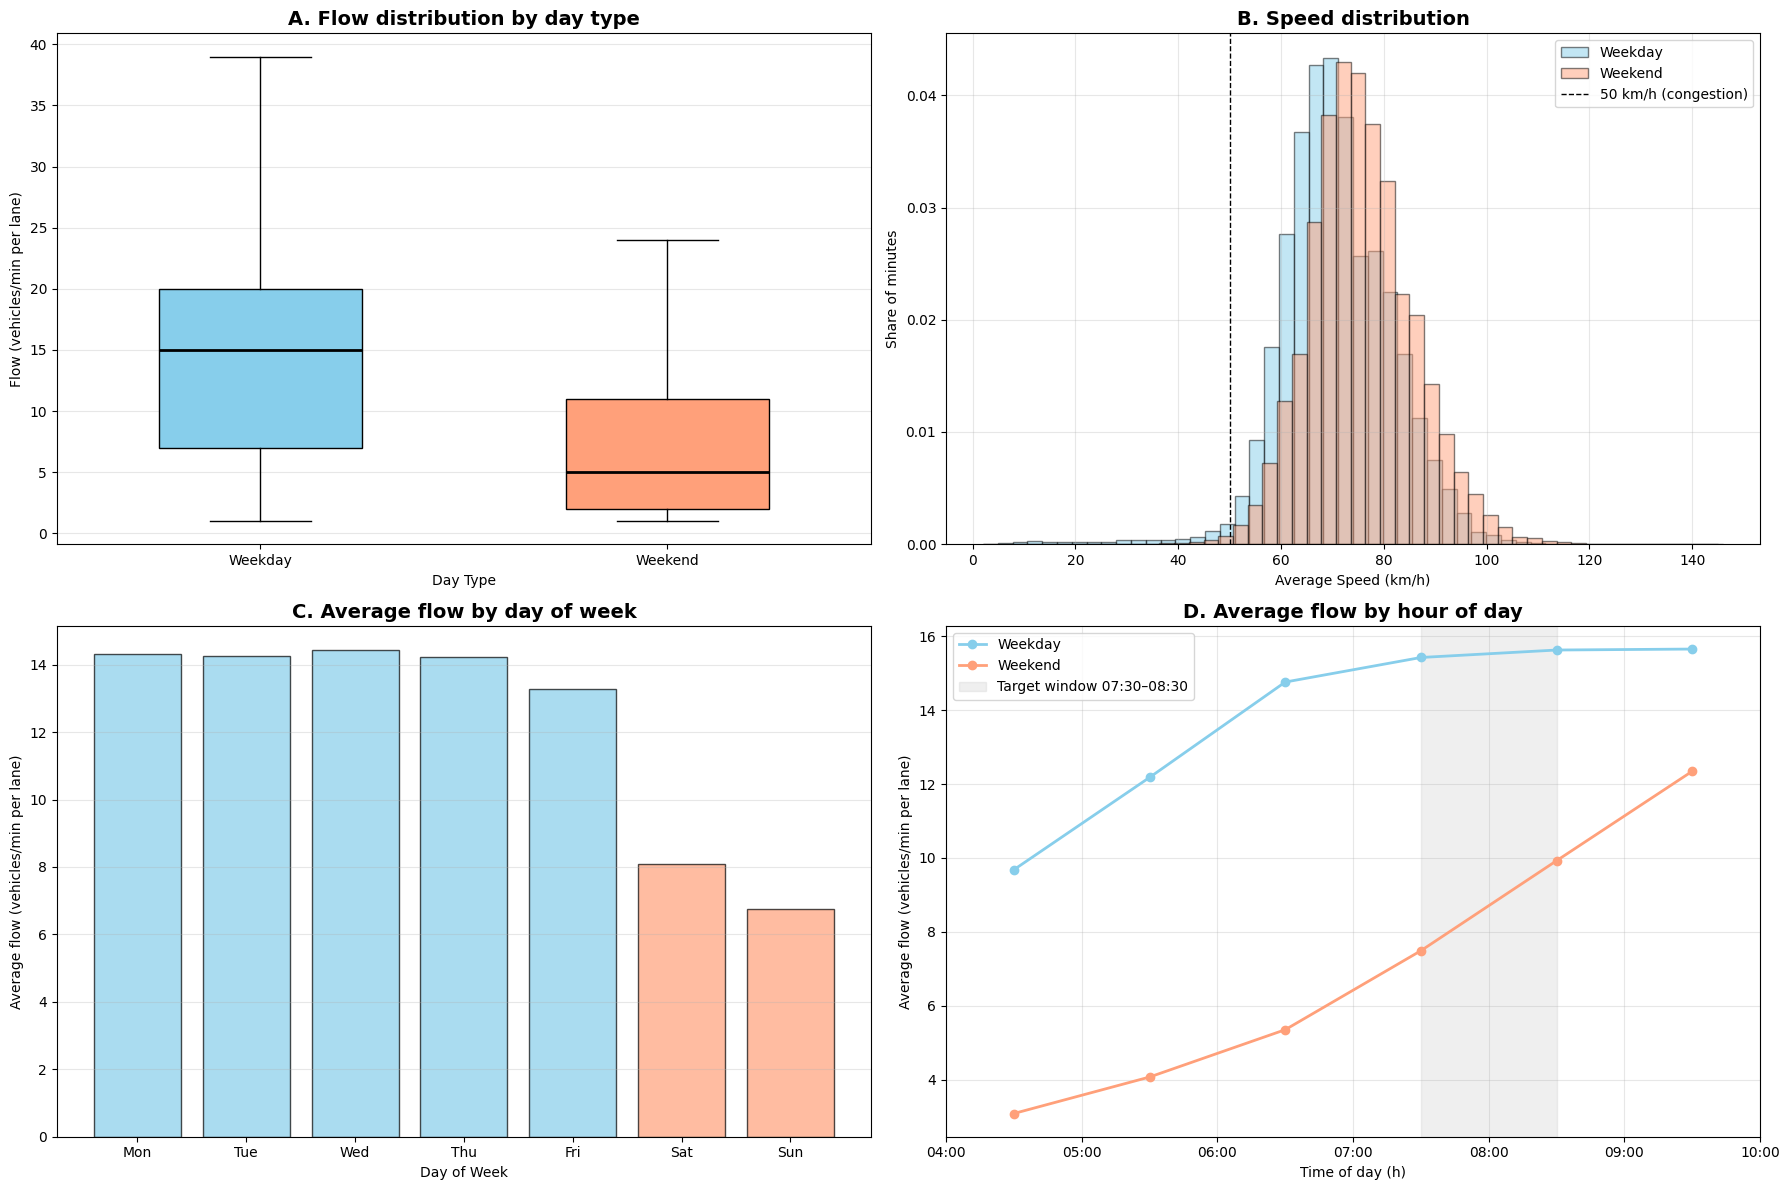

,FLOW,SPEED_KMH,Minutes below 50 km/h (%)
DayType,,,
Weekday,14.1,70.8,1.8
Weekend,7.5,75.7,0.5


In [ ]:
import matplotlib

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

colors = {"Weekday": "skyblue", "Weekend": "lightsalmon"}

# A. Flow distribution: weekday vs. weekend
ax = axes[0, 0]
flow_weekday = train_df.loc[train_df["DayType"] == "Weekday", "FLOW"].dropna()
flow_weekend = train_df.loc[train_df["DayType"] == "Weekend", "FLOW"].dropna()

# Matplotlib >= 3.9 uses "tick_labels"; older versions use "labels"
mpl_version = tuple(int(v) for v in matplotlib.__version__.split(".")[:2])
label_arg = "tick_labels" if mpl_version >= (3, 9) else "labels"

bp = ax.boxplot(
    [flow_weekday, flow_weekend],
    patch_artist=True,
    widths=0.5,
    showfliers=False,
    **{label_arg: ["Weekday", "Weekend"]}
)

bp["boxes"][0].set_facecolor(colors["Weekday"])
bp["boxes"][1].set_facecolor(colors["Weekend"])

for box in bp["boxes"]:
    box.set_edgecolor("black")

for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(2)

ax.set_title("A. Flow distribution by day type", fontsize=14, fontweight="bold")
ax.set_xlabel("Day Type")
ax.set_ylabel("Flow (vehicles/min per lane)")
ax.grid(True, alpha=0.3, axis="y")

# B. Speed distribution: weekday vs. weekend
# density=True -> both histograms show the share of minutes, so they are comparable
# even though there are more weekday than weekend minutes
ax = axes[0, 1]
for dt in ["Weekday", "Weekend"]:
    ax.hist(
        train_df.loc[train_df["DayType"] == dt, "SPEED_KMH"].dropna(),
        bins=50,
        alpha=0.5,
        density=True,
        color=colors[dt],
        edgecolor="black",
        label=dt
    )

ax.axvline(50, color="black", linestyle="--", linewidth=1, label="50 km/h (congestion)")
ax.set_title("B. Speed distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Average Speed (km/h)")
ax.set_ylabel("Share of minutes")
ax.legend()
ax.grid(True, alpha=0.3)

# C. Average flow by day of week
ax = axes[1, 0]
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_flow = train_df.groupby("DayOfWeek")["FLOW"].mean().reindex(range(7))

ax.bar(
    range(7),
    dow_flow.values,
    color=["skyblue"] * 5 + ["lightsalmon"] * 2,
    alpha=0.7,
    edgecolor="black"
)

ax.set_title("C. Average flow by day of week", fontsize=14, fontweight="bold")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average flow (vehicles/min per lane)")
ax.set_xticks(range(7))
ax.set_xticklabels(dow_names)
ax.grid(True, alpha=0.3, axis="y")

# D. Average flow by hour: weekday vs. weekend
ax = axes[1, 1]
hourly = train_df.groupby(["DayType", "Hour"])["FLOW"].mean().unstack(0)
hourly = hourly.loc[hourly.index < 10]          # hour 10 contains only the 10:00 minute

for dt in ["Weekday", "Weekend"]:
    ax.plot(
        hourly.index + 0.5,                     # each hourly average drawn in the middle of its hour
        hourly[dt],
        marker="o",
        linewidth=2,
        color=colors[dt],
        label=dt
    )

ax.axvspan(7.5, 8.5, color="silver", alpha=0.25, label="Target window 07:30–08:30")
ax.set_title("D. Average flow by hour of day", fontsize=14, fontweight="bold")
ax.set_xlabel("Time of day (h)")
ax.set_ylabel("Average flow (vehicles/min per lane)")
ax.set_xticks(range(hourly.index.min(), hourly.index.max() + 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(hourly.index.min(), hourly.index.max() + 2)])
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Key numbers for the report
summary = train_df.groupby("DayType")[["FLOW", "SPEED_KMH"]].mean().round(1)
summary["Minutes below 50 km/h (%)"] = (
    train_df.assign(slow=train_df["SPEED_KMH"] < 50)
    .groupby("DayType")["slow"].mean() * 100
).round(1)

display(summary)

## 1.6 Spatial patterns along the corridor

The portals are grouped into the sectors of the MCS schema in the task description (blue, pink, yellow and green). We compare the average speed and flow of each portal during the weekday peak, when congestion occurs.

In [ ]:
# ==============================================================================
# 1.6 CORRIDOR SECTORS (from the MCS schema in the task description)
# ==============================================================================
SECTOR_MAPPING = {
    "E4S 58,140": "Blue Sector",
    "E4S 57,820": "Blue Sector",
    "E4S 57,435": "Blue Sector",
    "E4S 57,055": "Blue Sector",
    "E4S 56,780": "Pink Sector",
    "E4S 56,490": "Pink Sector",
    "E4S 56,160": "Yellow Sector",
    "E4S 55,620": "Green Sector",
}

train_df["SECTOR"] = train_df["PORTAL"].map(SECTOR_MAPPING)

print("Portal-to-sector mapping (upstream -> downstream):")
for p in CORRIDOR_PORTALS:
    print(f"  {p} -> {SECTOR_MAPPING[p]}")
print("All portals mapped:", train_df["SECTOR"].notna().all())

Portal-to-sector mapping (upstream -> downstream):
  E4S 58,140 -> Blue Sector
  E4S 57,820 -> Blue Sector
  E4S 57,435 -> Blue Sector
  E4S 57,055 -> Blue Sector
  E4S 56,780 -> Pink Sector
  E4S 56,490 -> Pink Sector
  E4S 56,160 -> Yellow Sector
  E4S 55,620 -> Green Sector
All portals mapped: True


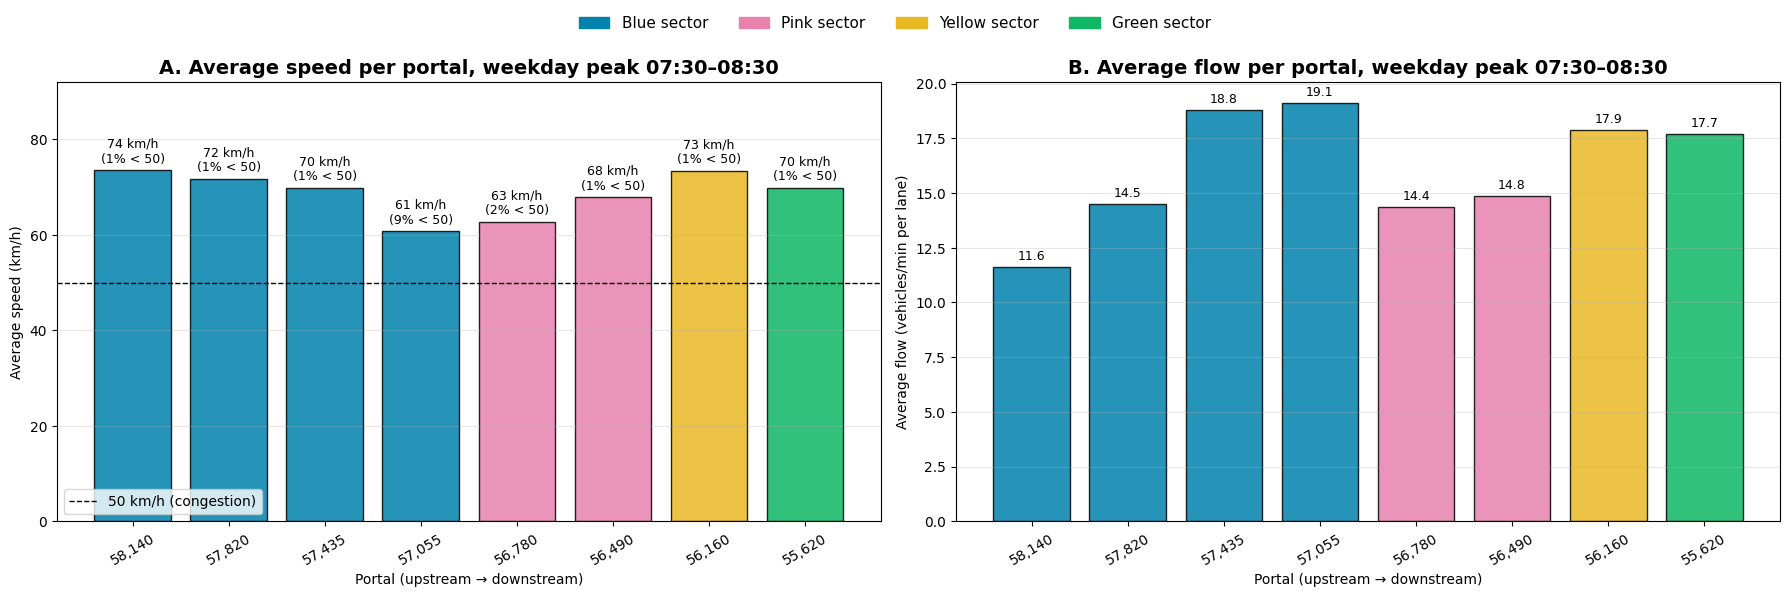

,Sector,Average flow (veh/min per lane),Average speed (km/h),Minutes below 50 km/h (%)
"E4S 58,140",Blue,11.6,73.6,1.1
"E4S 57,820",Blue,14.5,71.8,1.1
"E4S 57,435",Blue,18.8,69.9,1.3
"E4S 57,055",Blue,19.1,60.8,9.2
"E4S 56,780",Pink,14.4,62.8,2.5
"E4S 56,490",Pink,14.8,67.9,0.7
"E4S 56,160",Yellow,17.9,73.4,0.6
"E4S 55,620",Green,17.7,69.9,0.6


In [ ]:
# ==============================================================================
# 1.6 SPATIAL PATTERNS: TRAFFIC PER PORTAL DURING THE WEEKDAY PEAK
# ==============================================================================
# Portals in driving direction (upstream -> downstream), coloured by MCS sector
sector_colors = {"Blue": "#0082ad", "Pink": "#e882ad", "Yellow": "#e9b924", "Green": "#0db764"}
portal_sector = {p: SECTOR_MAPPING[p].replace(" Sector", "") for p in CORRIDOR_PORTALS}
bar_colors = [sector_colors[portal_sector[p]] for p in CORRIDOR_PORTALS]

# Weekday peak only (07:30-08:30): this is when congestion occurs
peak_wd = train_df[(train_df["DayType"] == "Weekday")
                   & (train_df["Time"].astype(str) >= "07:30:00")
                   & (train_df["Time"].astype(str) < "08:30:00")]

portal_stats = pd.DataFrame({
    "Sector": pd.Series(portal_sector),
    "Average flow (veh/min per lane)": peak_wd.groupby("PORTAL")["FLOW"].mean(),
    "Average speed (km/h)": peak_wd.groupby("PORTAL")["SPEED_KMH"].mean(),
    "Minutes below 50 km/h (%)": peak_wd.assign(slow=peak_wd["SPEED_KMH"] < 50)
                                        .groupby("PORTAL")["slow"].mean() * 100,
}).reindex(CORRIDOR_PORTALS)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
x = np.arange(len(CORRIDOR_PORTALS))
short_names = [p.replace("E4S ", "") for p in CORRIDOR_PORTALS]

# A. Average speed per portal
ax = axes[0]
ax.bar(x, portal_stats["Average speed (km/h)"], color=bar_colors, edgecolor="black", alpha=0.85)
ax.axhline(50, color="black", linestyle="--", linewidth=1, label="50 km/h (congestion)")
for i, (v, s) in enumerate(zip(portal_stats["Average speed (km/h)"], portal_stats["Minutes below 50 km/h (%)"])):
    ax.text(i, v + 1, f"{v:.0f} km/h\n({s:.0f}% < 50)", ha="center", va="bottom", fontsize=9)
ax.set_title("A. Average speed per portal, weekday peak 07:30–08:30", fontsize=14, fontweight="bold")
ax.set_xlabel("Portal (upstream → downstream)")
ax.set_ylabel("Average speed (km/h)")
ax.set_xticks(x); ax.set_xticklabels(short_names, rotation=30)
ax.set_ylim(0, portal_stats["Average speed (km/h)"].max() * 1.25)
ax.legend(loc="lower left"); ax.grid(True, alpha=0.3, axis="y")

# B. Average flow per portal
ax = axes[1]
ax.bar(x, portal_stats["Average flow (veh/min per lane)"], color=bar_colors, edgecolor="black", alpha=0.85)
for i, v in enumerate(portal_stats["Average flow (veh/min per lane)"]):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_title("B. Average flow per portal, weekday peak 07:30–08:30", fontsize=14, fontweight="bold")
ax.set_xlabel("Portal (upstream → downstream)")
ax.set_ylabel("Average flow (vehicles/min per lane)")
ax.set_xticks(x); ax.set_xticklabels(short_names, rotation=30)
ax.grid(True, alpha=0.3, axis="y")

# Sector legend (shared)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in sector_colors.values()]
fig.legend(handles, [f"{s} sector" for s in sector_colors], loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

display(portal_stats.round(1))

**Interpretation.** During the weekday peak, the average speed drops at the portals where traffic queues and the label above each bar shows how often the speed is below 50 km/h. The lowest speeds and most congested minutes indicate where the corridor breaks down; this is examined in detail with the space-time diagrams in Section 2.3. Flow per lane is similar along the corridor, because the same vehicles pass all portals. A bottleneck shows up mainly in the **speed**, not in the flow, which is why speed is used as an input for the flow forecast (H3).

# **PART 2: PROBLEM FORMULATION & DAY-TYPE REGIMES (Task B)**

## 2.1 Problem formulation

**What to predict?** Traffic **flow** (veh/min, summed over lanes) at the three portals around the bottleneck (E4S 57,055 – 56,780 – 56,490). Speed is used as an *input*. Speed prediction can be run in Part 6 (optional) as a comparison.

*Why flow?* Flow ($q$) measures throughput and demand, which is what ramp metering and capacity management act on. Flow alone is ambiguous, though: the same flow (say 20 veh/min per lane) occurs both in free flow and in a congested state (the two branches of the fundamental diagram). Speed ($v$) and the density proxy $k = q/v$ resolve this ambiguity, which is why they enter as explanatory features.

**Problem type.** A regression problem: one value for the 15-minute flow (main target) and 15 values at once for the 1-minute forecast (t+1…t+15). **Clustering** is used as an auxiliary step: days are grouped into regimes (K-Means, Sections 2.5–2.6), and a real-time classifier assigns the current day to a regime from its pre-peak traffic (Section 3.1). The regime label enters the regression as a feature.

**Practical use.** A prediction must be produced within the one-minute update cycle, must not use future data, and must keep working when single detectors fail. These requirements drive the design of the causal pipeline (Section 3.2) and the robustness tests (Section 4.6).



## 2.2 A-priori hypotheses
These hypotheses were formulated before modelling. Each is tested explicitly; the summary is in Section 4.8.

| # | Hypothesis | Features it motivates | How it is tested |
|---|---|---|---|
| **H1** | *Temporal persistence:* the current and very recent flow (lags 0–5 min) and short rolling averages are the strongest predictors; their value decays with the horizon, so errors grow from $t+1$ to $t+15$. | Flow lags 0, 1, 2, 3, 5, 10, 15; rolling averages 5/15 min | Feature importance (3.9), horizon-degradation curve (4.2) |
| **H2** | *Spatial propagation:* traffic at the up-/downstream neighbours and along the corridor carries information about the target portal's near future (demand arrives from upstream; queues spill back from downstream). | Upstream/downstream flow & speed, speed gradient, corridor flow vector | Feature-group removal test, 1-min and 15-min targets (3.8); sensor-outage test (4.6) |
| **H3** | *Speed resolves regime ambiguity:* adding speed and density improves flow prediction, especially in congestion. | Speed lags, rolling speeds, density proxy | Feature-group removal test (3.8); error by traffic state (4.5) |
| **H4** | *Day-type regimes:* the demand level depends on day type and season; a regime label identified from pre-peak traffic helps. | Weekday/weekend & time encodings, cluster indicators | Clustering (2.5–2.6), feature-group removal test (3.8), error by day type and month (4.5) |
| **H5** | *Aggregation:* one-minute counts contain a large random (Poisson-like) component, so the relative error of the 15-minute average is much lower, and the 15-minute flow is the operationally useful target. | 15-minute targets (Methods 1/2) | 1-minute forecast vs. Methods 1/2 (3.7, 4.1), noise floor (4.2), 1-min vs. 15-min comparison (4.2b), aggregation-window sweep (4.2c) |
| **H6** | *Non-linearity:* breakdown is a non-linear phenomenon, so tree-based and recurrent models beat the linear model mainly in congested conditions. | Model families: Ridge vs. XGBoost vs. RNN | Model comparison (3.7, 4.1), error by traffic state (4.5) |

*Longer horizons (30/60 min, mentioned in the TRV description):* we expect calendar and regime features (H4) to gain importance and recent lags (H1) to lose importance as the horizon grows. This is outside the scope of the 15-minute benchmark but is listed as future work.

## 2.3 Spatio-temporal day vectors (portal × 5-minute interval)
For the clustering, each day is represented by one vector: for every portal, the 5-minute flow (or flow-weighted speed) for all intervals between 04:00 and 10:00. We use 5-minute resolution because it is a balance between temporal detail and noise: 1-minute values are very noisy, and 15-minute values leave too few points to describe the morning shape.

Expected size: 214 days × (8 portals × 73 intervals = 584 features).

In [ ]:
# Downstream spatial sequence matching corridor layout
downstream_portals = CORRIDOR_PORTALS

# Momentum product at detector level (flow * speed in m/s)
train_df['FLOW_x_SPEED'] = train_df['FLOW'] * train_df['SPEED_MS_AVG']

# Aggregate all lanes per portal and 5-minute interval
portal_5min = train_df.groupby(['Date', 'Interval_5', 'PORTAL'], as_index=False).agg(
    FLOW=('FLOW', 'sum'),
    FLOW_x_SPEED=('FLOW_x_SPEED', 'sum'),
    SPEED_MS_UNWEIGHTED=('SPEED_MS_AVG', 'mean')
)

# Flow-weighted speed in m/s, falling back to arithmetic mean if FLOW == 0
portal_5min['SPEED_MS_WEIGHTED'] = np.where(
    portal_5min['FLOW'] > 0,
    portal_5min['FLOW_x_SPEED'] / portal_5min['FLOW'],
    portal_5min['SPEED_MS_UNWEIGHTED']
)

# Convert aggregated weighted speed to km/h
portal_5min['SPEED_KMH_WEIGHTED'] = portal_5min['SPEED_MS_WEIGHTED'] * 3.6

# HUMAN-READABLE TIME FORMATTING (CONVERT INTERVAL_5 TO HH:MM)
def interval5_to_time_str(interval):
    total_minutes = interval * 5
    hours = total_minutes // 60
    minutes = total_minutes % 60
    return f"{hours:02d}:{minutes:02d}"

portal_5min['Time_HHMM'] = portal_5min['Interval_5'].apply(interval5_to_time_str)

# Clear composite identifier: "PortalName_HH:MM" (e.g., E4S 56,780_04:00)
portal_5min['PORTAL_TIME'] = portal_5min['PORTAL'] + '_' + portal_5min['Time_HHMM']

# STRICT COLUMN ORDERING (UPSTREAM -> DOWNSTREAM ACROSS TIME)
available_intervals = sorted(portal_5min['Interval_5'].unique())
time_labels = [interval5_to_time_str(i) for i in available_intervals]

ordered_columns = [
    f"{portal}_{time_str}"
    for portal in downstream_portals
    for time_str in time_labels
]

# PIVOT BOTH FLOW AND SPEED MATRICES

# A. Day Matrix for Traffic Flow (Vehicle count per 5 minutes)
day_matrix_flow = portal_5min.pivot(
    index='Date',
    columns='PORTAL_TIME',
    values='FLOW'
).reindex(columns=ordered_columns)

# B. Day Matrix for Traffic Speed (Flow-weighted km/h)
day_matrix_speed = portal_5min.pivot(
    index='Date',
    columns='PORTAL_TIME',
    values='SPEED_KMH_WEIGHTED'
).reindex(columns=ordered_columns)

# VERIFICATION AND DISPLAY OF BOTH MATRICES
print(f"Flow Matrix Dimensions  : {day_matrix_flow.shape} (Days x Features)")
print(f"Speed Matrix Dimensions : {day_matrix_speed.shape} (Days x Features)")

print("\n--- SAMPLE: DAY MATRIX FLOW (Vehicles / 5-min) ---")
display(day_matrix_flow.iloc[:5, :6])

print("\n--- SAMPLE: DAY MATRIX SPEED (km/h) ---")
display(day_matrix_speed.iloc[:5, :6].round(1))

Flow Matrix Dimensions  : (214, 584) (Days x Features)
Speed Matrix Dimensions : (214, 584) (Days x Features)

--- SAMPLE: DAY MATRIX FLOW (Vehicles / 5-min) ---


PORTAL_TIME,"E4S 58,140_04:00","E4S 58,140_04:05","E4S 58,140_04:10","E4S 58,140_04:15","E4S 58,140_04:20","E4S 58,140_04:25"
Date,,,,,,
20210601,20.0,22.0,14.0,25.0,16.0,37.0
20210602,15.0,26.0,15.0,17.0,27.0,26.0
20210603,34.0,16.0,14.0,18.0,28.0,28.0
20210604,17.0,20.0,22.0,31.0,22.0,23.0
20210605,18.0,15.0,14.0,17.0,22.0,22.0



--- SAMPLE: DAY MATRIX SPEED (km/h) ---


PORTAL_TIME,"E4S 58,140_04:00","E4S 58,140_04:05","E4S 58,140_04:10","E4S 58,140_04:15","E4S 58,140_04:20","E4S 58,140_04:25"
Date,,,,,,
20210601,80.7,79.2,80.9,79.2,80.6,79.2
20210602,76.3,75.2,78.2,77.9,81.1,83.2
20210603,79.7,78.3,80.3,79.0,71.8,79.7
20210604,81.3,77.6,79.6,76.7,80.8,86.1
20210605,83.2,80.8,87.2,80.2,84.1,79.0


### Space-time diagrams (weekdays)
Average flow and speed along the corridor; the dashed lines mark the target window.

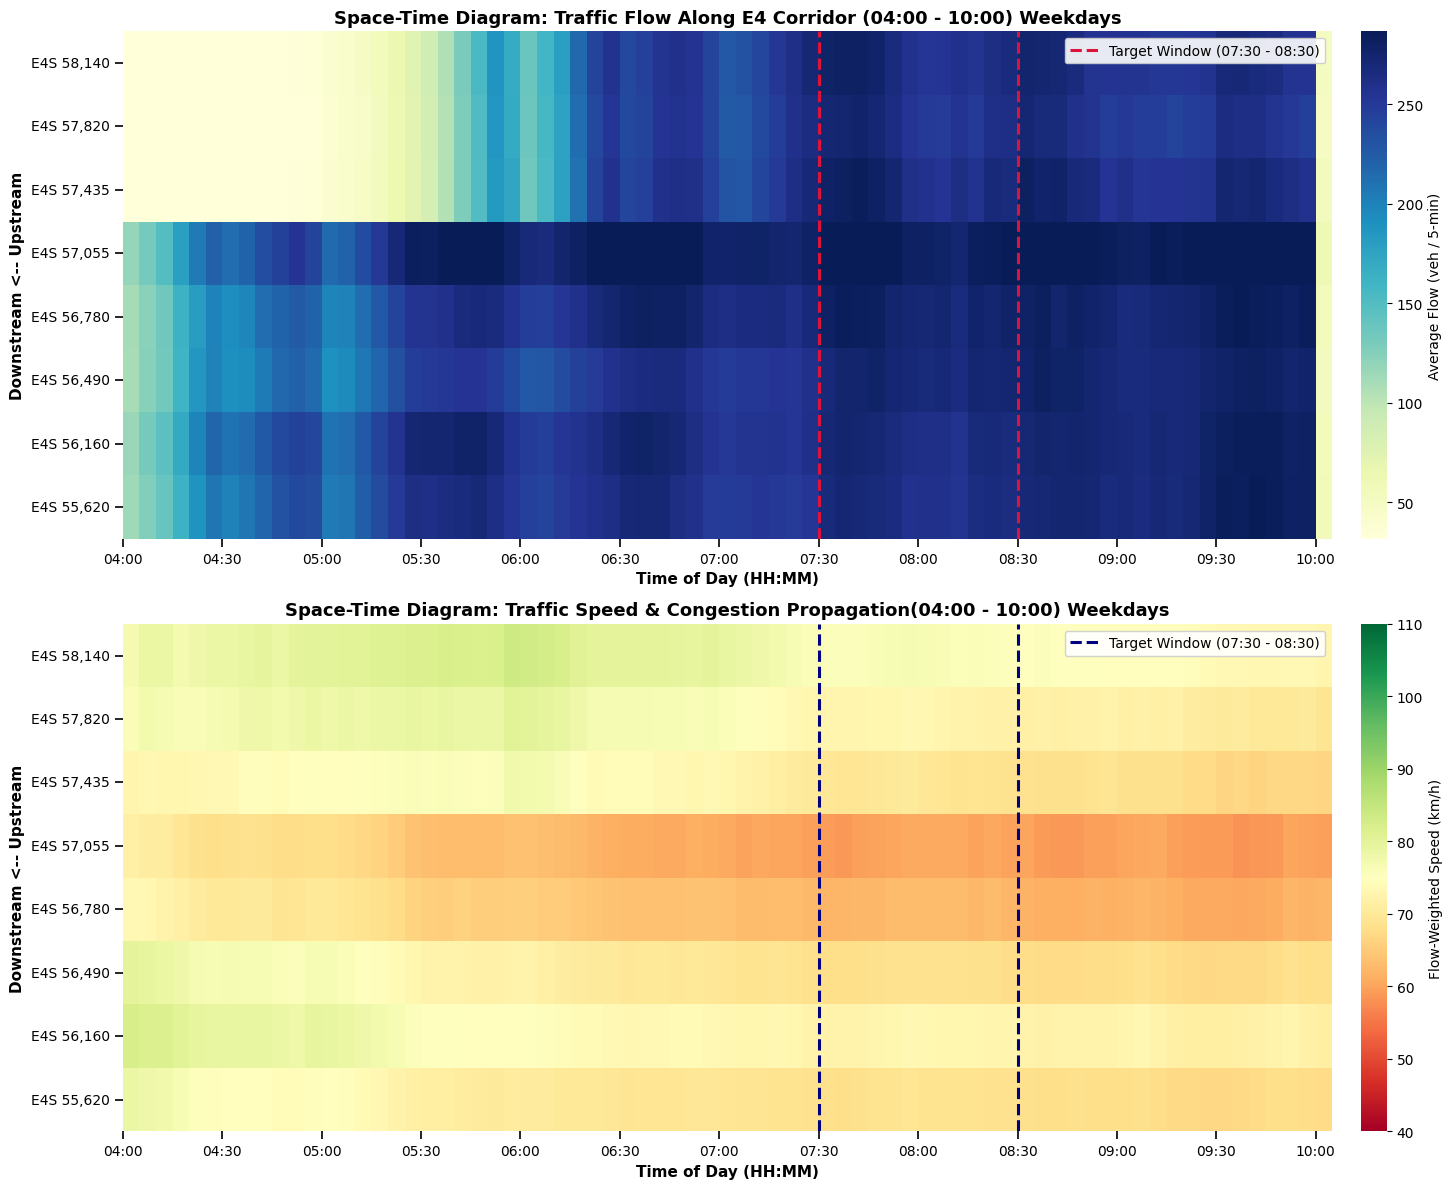

In [ ]:
# SPACE-TIME HEATMAPS FOR WEEKDAY

# Corridor portals ordered strictly upstream -> downstream
downstream_portals = CORRIDOR_PORTALS

# Ensure DayType exists in portal_5min before filtering
if 'DayType' not in portal_5min.columns:
    portal_5min['DateTime_temp'] = pd.to_datetime(portal_5min['Date'].astype(str), format='%Y%m%d')
    portal_5min['DayType'] = portal_5min['DateTime_temp'].dt.dayofweek.apply(
        lambda x: 'Weekend' if x >= 5 else 'Weekday'
    )
    portal_5min.drop(columns=['DateTime_temp'], inplace=True)

df_heat = portal_5min[portal_5min['DayType'] == 'Weekday'].copy()

spacetime_flow = df_heat.groupby(['PORTAL', 'Time_HHMM'])['FLOW'].mean().unstack(level='Time_HHMM')
spacetime_speed = df_heat.groupby(['PORTAL', 'Time_HHMM'])['SPEED_KMH_WEIGHTED'].mean().unstack(level='Time_HHMM')

spacetime_flow = spacetime_flow.reindex(index=downstream_portals)
spacetime_speed = spacetime_speed.reindex(index=downstream_portals)

# Colorbar limits
flow_vmin = np.nanpercentile(spacetime_flow.values, 5)
flow_vmax = np.nanpercentile(spacetime_flow.values, 95)
speed_vmin = 40
speed_vmax = 110

# Time indices for reference window (07:30 - 08:30)
time_cols = list(spacetime_flow.columns)
idx_start = time_cols.index('07:30') if '07:30' in time_cols else None
idx_end = time_cols.index('08:30') if '08:30' in time_cols else None

# Configure plots with independent axes
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=False)

# Subplot 1: Flow Heatmap
sns.heatmap(
    spacetime_flow,
    ax=axes[0],
    cmap='YlGnBu',
    vmin=flow_vmin,
    vmax=flow_vmax,
    cbar_kws={'label': 'Average Flow (veh / 5-min)', 'pad': 0.02}
)
axes[0].set_title('Space-Time Diagram: Traffic Flow Along E4 Corridor (04:00 - 10:00) Weekdays', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Downstream <-- Upstream', fontsize=11, fontweight='bold')

# High-contrast reference line for Flow
if idx_start is not None and idx_end is not None:
    axes[0].axvline(x=idx_start, color='crimson', linestyle='--', linewidth=2.2, label='Target Window (07:30 - 08:30)')
    axes[0].axvline(x=idx_end, color='crimson', linestyle='--', linewidth=2.2)
    axes[0].legend(loc='upper right', framealpha=0.9)

# Subplot 2: Speed Heatmap (RdYlGn palette)
sns.heatmap(
    spacetime_speed,
    ax=axes[1],
    cmap='RdYlGn',
    vmin=speed_vmin,
    vmax=speed_vmax,
    cbar_kws={'label': 'Flow-Weighted Speed (km/h)', 'pad': 0.02}
)
axes[1].set_title('Space-Time Diagram: Traffic Speed & Congestion Propagation(04:00 - 10:00) Weekdays', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Downstream <-- Upstream', fontsize=11, fontweight='bold')

# High-contrast reference line for Speed
if idx_start is not None and idx_end is not None:
    axes[1].axvline(x=idx_start, color='navy', linestyle='--', linewidth=2.2, label='Target Window (07:30 - 08:30)')
    axes[1].axvline(x=idx_end, color='navy', linestyle='--', linewidth=2.2)
    axes[1].legend(loc='upper right', framealpha=0.9)

# Restore Axis Tick Marks, Directions, and Scales on Both Subplots
time_ticks = list(range(0, len(time_cols), 6))  # Every 30 minutes
time_tick_labels = [time_cols[i] for i in time_ticks]

for ax in axes:
    # Set X-axis tick positions and labels
    ax.set_xticks(time_ticks)
    ax.set_xticklabels(time_tick_labels, rotation=0, fontsize=10)
    ax.set_xlabel('Time of Day (HH:MM)', fontsize=11, fontweight='bold')

    # Restore physical tick marks on both X and Y axes
    ax.tick_params(
        axis='both',
        which='major',
        left=True,          # Show Y-axis portal tick marks
        bottom=True,        # Show X-axis time tick marks
        length=6,           # Visible length of the mark in points
        width=1.2,          # Thickness of the tick line
        colors='black',     # Tick mark color
        direction='out'     # Point outwards from heatmap grid
    )

plt.tight_layout()
plt.show()

E4S 57,055 and 56,780 are slower than the rest of the corridor throughout the morning, even at 04:00 when traffic is light; this reflects a lower free-flow speed on this section (road layout, merging). During the peak their speed drops further, which marks this section as the place where the corridor reaches its capacity. Averaged over all weekdays this drop is moderate, because strong breakdowns do not occur every day; the 214-day heatmap below shows the individual days. Note that the colours depend on the chosen scale (here 40–110 km/h).

### Bottleneck and target portals
Based on the space-time diagram, the bottleneck is set to **E4S 56,780**. Its upstream neighbour (E4S 57,055, where the queue forms) and downstream neighbour (E4S 56,490, where traffic leaves the bottleneck) are added as target portals.

In [ ]:
BOTTLENECK_PORTAL = "E4S 56,780"                             # identified from the space-time diagram
TARGET_PORTALS = ["E4S 57,055", "E4S 56,780", "E4S 56,490"]  # bottleneck + its neighbours
print(f"Bottleneck: {BOTTLENECK_PORTAL} | Target portals: {TARGET_PORTALS}")

Bottleneck: E4S 56,780 | Target portals: ['E4S 57,055', 'E4S 56,780', 'E4S 56,490']


### 214-day speed heatmap at the bottleneck
One row per day; dark grey cells are missing data.

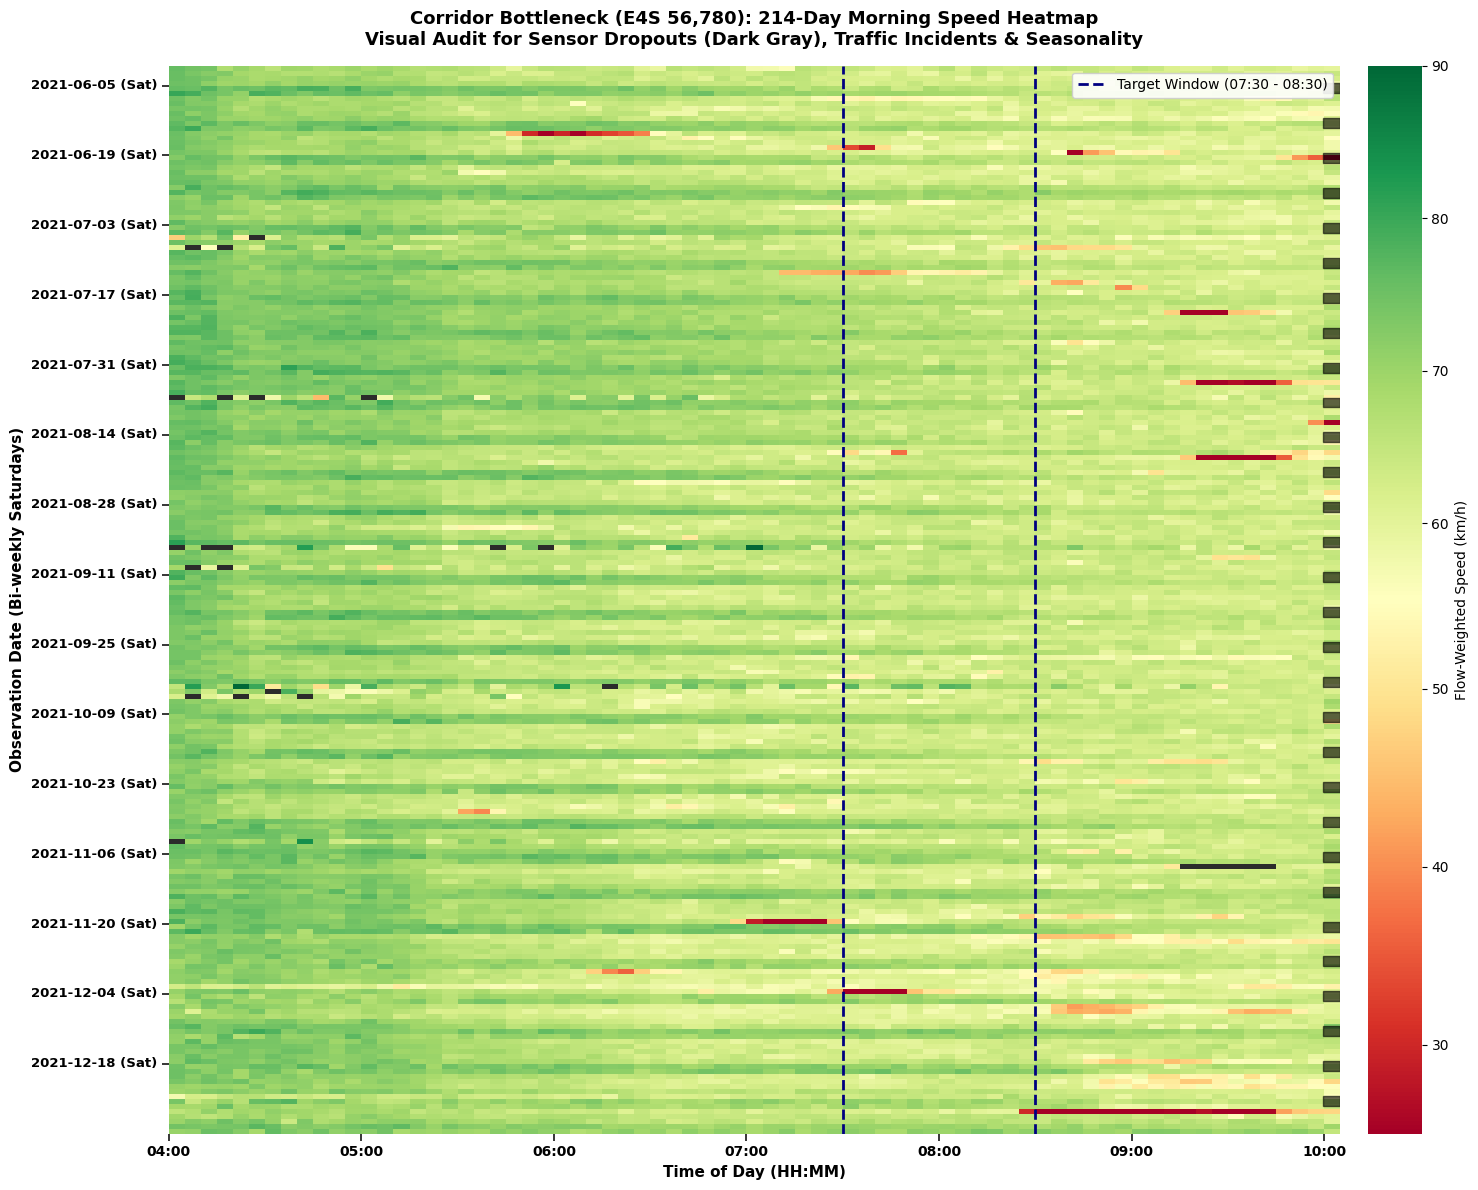

In [ ]:
# ENHANCED 214-DAY SPEED HEATMAP WITH EXPLICIT SENSOR DROPOUT & INCIDENT AUDIT

# Step 1: Filter data for the critical bottleneck portal
bottleneck_portal = BOTTLENECK_PORTAL
df_bottleneck = portal_5min[portal_5min['PORTAL'] == bottleneck_portal].copy()

# Step 2: Pivot into Day-by-Time matrix (214 days x 73 intervals)
heatmap_matrix = df_bottleneck.pivot(
    index='Date',
    columns='Time_HHMM',
    values='SPEED_KMH_WEIGHTED'
)

# Step 3: Chronological ordering and datetime conversion
heatmap_matrix.index = pd.to_datetime(heatmap_matrix.index.astype(str), format='%Y%m%d')
heatmap_matrix = heatmap_matrix.sort_index(ascending=True)

# Step 4: Configure colormap with explicit missing-value (dropout) color
base_cmap = plt.cm.RdYlGn.copy()
base_cmap.set_bad(color='#2B2B2B')  # Dark charcoal gray highlights missing data/dropouts

# Center color transition at critical speed (v_crit = 55 km/h)
norm = mcolors.TwoSlopeNorm(vmin=25, vcenter=55, vmax=90)

plt.figure(figsize=(16, 12))

# Step 5: Render heatmap
ax = sns.heatmap(
    heatmap_matrix,
    cmap=base_cmap,
    norm=norm,
    cbar_kws={'label': 'Flow-Weighted Speed (km/h)', 'pad': 0.02},
    linewidths=0.0,
    rasterized=True
)

# Step 6: Format X-axis (Hourly marks)
time_cols = list(heatmap_matrix.columns)
x_ticks = [i for i, t in enumerate(time_cols) if t.endswith(':00')]
x_labels = [time_cols[i] for i in x_ticks]
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels, rotation=0, fontsize=10, fontweight='bold')
ax.set_xlabel('Time of Day (HH:MM)', fontsize=11, fontweight='bold')

# Step 7: Format Y-axis (Every 2 weeks with Day-of-Week abbreviation)
# Locate all weekend rows (Saturday = 5, Sunday = 6)
weekend_mask = heatmap_matrix.index.dayofweek >= 5
saturday_indices = [
    i for i, dt in enumerate(heatmap_matrix.index) if dt.dayofweek == 5
]

# Place labels on every 2nd Saturday
y_ticks = saturday_indices[::2]
y_labels = [
    heatmap_matrix.index[i].strftime('%Y-%m-%d (Sat)') for i in y_ticks
]
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels, rotation=0, fontsize=9.5, fontweight='bold')
ax.set_ylabel(
    'Observation Date (Bi-weekly Saturdays)', fontsize=11, fontweight='bold'
)

# Highlight weekend blocks with subtle horizontal edge lines on the right axis
for sat_idx in saturday_indices:
    # Shade/outline the 2-day weekend interval (Saturday + Sunday)
    ax.axhspan(
        sat_idx - 0.5,
        sat_idx + 1.5,
        xmin=0.985,
        xmax=1.0,
        color='black',
        alpha=0.6,
    )

# Step 8: Clean reference boundary lines without text collision
t_start_idx = time_cols.index('07:30') if '07:30' in time_cols else None
t_end_idx = time_cols.index('08:30') if '08:30' in time_cols else None

if t_start_idx is not None and t_end_idx is not None:
    ax.axvline(x=t_start_idx, color='navy', linestyle='--', linewidth=2, label='Target Window (07:30 - 08:30)')
    ax.axvline(x=t_end_idx, color='navy', linestyle='--', linewidth=2)
    ax.legend(loc='upper right', framealpha=0.9, fontsize=10)

# Physical ticks outwards for precise reading
ax.tick_params(axis='both', which='major', left=True, bottom=True, length=5, width=1.1, direction='out')

plt.title(
    f'Corridor Bottleneck ({bottleneck_portal}): 214-Day Morning Speed Heatmap\n'
    f'Visual Audit for Sensor Dropouts (Dark Gray), Traffic Incidents & Seasonality',
    fontsize=13,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
plt.show()

## 2.4 Missing intervals in the day matrices and imputation
The dark-grey cells above are intervals where a portal has no data at all (in addition to the rows with missing flow removed in 1.3). The audit below quantifies them.

In [ ]:
# MISSING DATA AUDIT & INSPECTION IN FLOW MATRIX

# Total missing values in the flow matrix
nan_count = day_matrix_flow.isna().sum().sum()
print(f"Total NaN values in day_matrix_flow: {nan_count}")

# Check missing values per portal (split by '_' instead of '_int')
missing_per_portal = day_matrix_flow.isna().sum().groupby(lambda x: x.split('_')[0]).sum()
print("\nMissing values per portal:")
print(missing_per_portal)

# Identify days containing missing intervals
missing_records = day_matrix_flow.isna().sum(axis=1)
days_with_gaps = missing_records[missing_records > 0]

print(f"\nTotal days containing missing time intervals: {len(days_with_gaps)} out of {len(day_matrix_flow)}")
print("\nTop 10 days with the highest number of missing intervals:")
print(days_with_gaps.sort_values(ascending=False).head(10))

# Filter and display sliced table containing exclusively missing data locations
rows_with_nan = day_matrix_flow.isna().any(axis=1)
cols_with_nan = day_matrix_flow.isna().any(axis=0)

nan_inspection_table = day_matrix_flow.loc[rows_with_nan, cols_with_nan]
print(f"\nTable dimensions of missing entries FLOW MATRIX: {nan_inspection_table.shape}")
display(nan_inspection_table.head(10).round(1))

# PRE-IMPUTATION DIAGNOSTIC AUDIT
def audit_missing_values(df, matrix_name):
    total_cells = df.size
    total_nans = df.isna().sum().sum()
    pct_nans = (total_nans / total_cells) * 100
    cols_with_nans = (df.isna().sum() > 0).sum()
    rows_with_nans = (df.isna().sum(axis=1) > 0).sum()

    print(f"--- Diagnostic Audit: {matrix_name} ---")
    print(f"Matrix Dimensions           : {df.shape[0]} days x {df.shape[1]} features")
    print(f"Total Missing Cells (NaN)   : {total_nans:,} / {total_cells:,} ({pct_nans:.4f}%)")
    print(f"Affected Features (Columns) : {cols_with_nans} / {df.shape[1]}")
    print(f"Affected Days (Rows)        : {rows_with_nans} / {df.shape[0]}\n")

# Run diagnostic checks
audit_missing_values(day_matrix_flow, "day_matrix_flow")
audit_missing_values(day_matrix_speed, "day_matrix_speed")

Total NaN values in day_matrix_flow: 2250

Missing values per portal:
PORTAL_TIME
E4S 55,620    578
E4S 56,160    600
E4S 56,490     45
E4S 56,780     26
E4S 57,055    636
E4S 57,435    125
E4S 57,820    127
E4S 58,140    113
dtype: int64

Total days containing missing time intervals: 27 out of 214

Top 10 days with the highest number of missing intervals:
Date
20210905    226
20210806    225
20211003    222
20210705    214
20211103    183
20210801    156
20210707    151
20210730    141
20211004    137
20210909    123
dtype: int64

Table dimensions of missing entries FLOW MATRIX: (27, 449)


PORTAL_TIME,"E4S 58,140_04:00","E4S 58,140_04:05","E4S 58,140_04:10","E4S 58,140_04:15","E4S 58,140_04:20","E4S 58,140_04:25","E4S 58,140_04:30","E4S 58,140_04:35","E4S 58,140_04:40","E4S 58,140_04:45","E4S 58,140_04:50","E4S 58,140_04:55","E4S 58,140_05:00","E4S 58,140_05:05","E4S 58,140_05:10","E4S 58,140_05:15","E4S 58,140_05:20","E4S 58,140_05:25","E4S 58,140_05:30","E4S 58,140_05:35",...,"E4S 55,620_08:25","E4S 55,620_08:30","E4S 55,620_08:35","E4S 55,620_08:40","E4S 55,620_08:45","E4S 55,620_08:50","E4S 55,620_08:55","E4S 55,620_09:00","E4S 55,620_09:05","E4S 55,620_09:10","E4S 55,620_09:15","E4S 55,620_09:20","E4S 55,620_09:25","E4S 55,620_09:30","E4S 55,620_09:35","E4S 55,620_09:40","E4S 55,620_09:45","E4S 55,620_09:50","E4S 55,620_09:55","E4S 55,620_10:00"
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
20210605,18.0,15.0,14.0,17.0,22.0,22.0,24.0,17.0,26.0,26.0,21.0,22.0,26.0,30.0,23.0,39.0,26.0,46.0,37.0,43.0,...,262.0,280.0,290.0,314.0,260.0,298.0,311.0,310.0,295.0,292.0,310.0,293.0,290.0,292.0,333.0,343.0,332.0,315.0,314.0,65.0
20210630,17.0,19.0,23.0,31.0,30.0,34.0,38.0,27.0,22.0,30.0,27.0,30.0,37.0,45.0,38.0,47.0,57.0,52.0,70.0,96.0,...,255.0,294.0,310.0,298.0,300.0,306.0,296.0,281.0,271.0,320.0,308.0,295.0,304.0,317.0,268.0,320.0,291.0,313.0,297.0,55.0
20210705,11.0,10.0,11.0,17.0,19.0,32.0,31.0,18.0,15.0,27.0,29.0,21.0,34.0,35.0,41.0,48.0,49.0,74.0,77.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,125.0,328.0,54.0
20210707,17.0,10.0,15.0,25.0,23.0,22.0,26.0,18.0,27.0,30.0,21.0,32.0,22.0,25.0,42.0,43.0,46.0,63.0,74.0,88.0,...,325.0,310.0,314.0,318.0,311.0,311.0,301.0,314.0,281.0,284.0,303.0,280.0,292.0,281.0,282.0,293.0,269.0,293.0,296.0,65.0
20210728,2.0,2.0,NaN,1.0,NaN,NaN,6.0,1.0,5.0,2.0,4.0,NaN,43.0,29.0,27.0,24.0,34.0,37.0,44.0,50.0,...,255.0,245.0,254.0,302.0,274.0,286.0,284.0,293.0,264.0,274.0,267.0,264.0,278.0,310.0,322.0,302.0,323.0,288.0,300.0,75.0
20210730,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,278.0,289.0,313.0,281.0,278.0,283.0,281.0,283.0,294.0,319.0,286.0,309.0,305.0,290.0,303.0,294.0,299.0,305.0,269.0,68.0
20210801,NaN,30.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,268.0,243.0,299.0,255.0,236.0,242.0,257.0,263.0,242.0,250.0,233.0,257.0,266.0,254.0,236.0,240.0,270.0,273.0,263.0,41.0
20210806,22.0,19.0,24.0,12.0,26.0,27.0,22.0,21.0,31.0,35.0,19.0,19.0,23.0,25.0,28.0,33.0,43.0,43.0,44.0,47.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20210822,33.0,24.0,27.0,20.0,17.0,23.0,27.0,26.0,26.0,34.0,16.0,24.0,19.0,27.0,20.0,27.0,22.0,24.0,23.0,32.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,234.0,242.0,288.0,265.0,264.0,295.0,39.0


--- Diagnostic Audit: day_matrix_flow ---
Matrix Dimensions           : 214 days x 584 features
Total Missing Cells (NaN)   : 2,250 / 124,976 (1.8003%)
Affected Features (Columns) : 449 / 584
Affected Days (Rows)        : 27 / 214

--- Diagnostic Audit: day_matrix_speed ---
Matrix Dimensions           : 214 days x 584 features
Total Missing Cells (NaN)   : 2,250 / 124,976 (1.8003%)
Affected Features (Columns) : 449 / 584
Affected Days (Rows)        : 27 / 214



**Result.** About 1.8% of the cells are missing, concentrated on 27 of 214 days (mostly at a few portals). Dropping these days would remove 13% of the days, so we impute instead.

**Imputation for clustering:** each missing cell is replaced by the median of that portal-interval over all days. The median is robust against the occasional incident day. (This is only for the *offline* clustering; the real-time prediction pipeline uses a causal imputation, Section 3.2.)

In [ ]:
# COLUMN-WISE MEDIAN IMPUTATION

# Imputes each feature (Portal_Time) using its historical median across all days
flow_medians = day_matrix_flow.median()
speed_medians = day_matrix_speed.median()

# Apply column-wise imputation
day_matrix_flow_imputed = day_matrix_flow.fillna(flow_medians)
day_matrix_speed_imputed = day_matrix_speed.fillna(speed_medians)

# Optional: Reassign directly to maintain variable consistency downstream
day_matrix_flow = day_matrix_flow_imputed
day_matrix_speed = day_matrix_speed_imputed

# Imputation Verification
post_flow_nans = day_matrix_flow.isna().sum().sum()
post_speed_nans = day_matrix_speed.isna().sum().sum()

print("--- Post-Imputation Verification ---")
print(f"Remaining NaNs in day_matrix_flow  : {post_flow_nans}")
print(f"Remaining NaNs in day_matrix_speed : {post_speed_nans}")

if post_flow_nans == 0 and post_speed_nans == 0:
    print("\nStatus: Successfully imputed all missing values. Matrices are complete and ready for ML modeling.")
else:
    print("\nWarning: Some missing values remain unresolved.")

--- Post-Imputation Verification ---
Remaining NaNs in day_matrix_flow  : 0
Remaining NaNs in day_matrix_speed : 0

Status: Successfully imputed all missing values. Matrices are complete and ready for ML modeling.


## 2.5 Choosing the number of clusters
K-Means is run on the speed day-matrix for $K = 2 \dots 8$ and evaluated with four internal criteria (elbow/inertia, Silhouette ↑, Calinski–Harabasz ↑, Davies–Bouldin ↓). All features are speeds in km/h, so no extra scaling is needed.

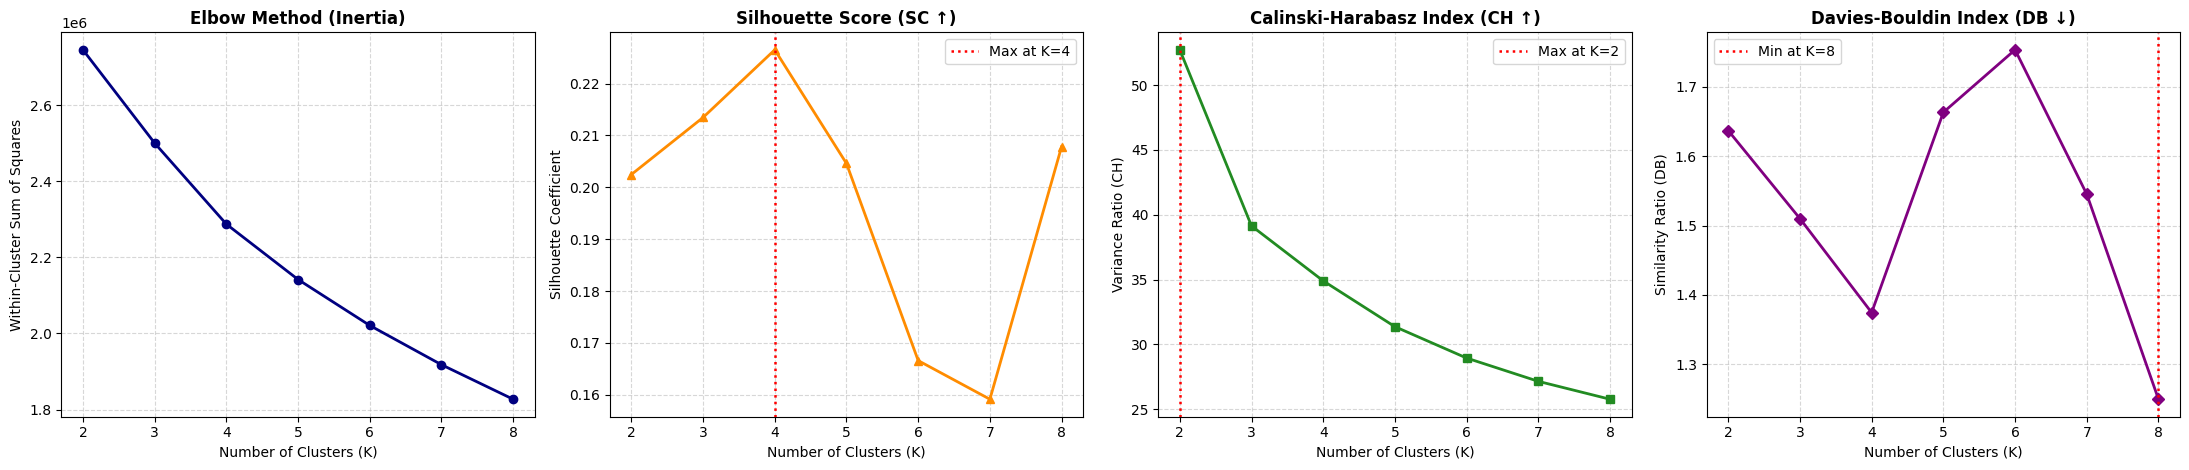

CLUSTERING VALIDATION SCORES SUMMARY (K = 2 to 8)


,K,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin
0,2,2745110.4,0.2025,52.72,1.6369
1,3,2500161.8,0.2135,39.14,1.5100
2,4,2287278.3,0.2265,34.90,1.3745
3,5,2141805.6,0.2046,31.37,1.6632
4,6,2021140.6,0.1666,28.95,1.7532
5,7,1918009.2,0.1591,27.16,1.5451
6,8,1827297.9,0.2079,25.78,1.2497


In [ ]:
# INTERNAL CLUSTERING QUALITY EVALUATION (K-MEANS: K = 2 TO 8)
# Evaluation across Inertia, Silhouette, Calinski-Harabasz, and Davies-Bouldin

# Step 1: Set input matrix
X_clustering = day_matrix_speed.copy()

# Step 2: Iterate across cluster candidates (K = 2 to 8)
k_range = range(2, 9)
inertia_list = []
silhouette_list = []
ch_list = []
db_list = []

for k in k_range:
    # Set n_init=20 to ensure stable centroid convergence across random restarts
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_clustering)

    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X_clustering, labels))
    ch_list.append(calinski_harabasz_score(X_clustering, labels))
    db_list.append(davies_bouldin_score(X_clustering, labels))

# Step 3: 4-Panel Visualization of Internal Validation Metrics
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))

# 1. Elbow Method (Inertia / WCSS - Lower is better, look for bend)
axes[0].plot(k_range, inertia_list, marker='o', color='navy', linewidth=2)
axes[0].set_title('Elbow Method (Inertia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)', fontsize=10)
axes[0].set_ylabel('Within-Cluster Sum of Squares', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Silhouette Score (SC - Higher is better / Maximum separation)
best_sil_k = k_range[np.argmax(silhouette_list)]
axes[1].plot(
    k_range, silhouette_list, marker='^', color='darkorange', linewidth=2
)
axes[1].axvline(
    x=best_sil_k,
    color='red',
    linestyle=':',
    linewidth=1.8,
    label=f'Max at K={best_sil_k}',
)
axes[1].set_title('Silhouette Score (SC ↑)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)', fontsize=10)
axes[1].set_ylabel('Silhouette Coefficient', fontsize=10)
axes[1].legend(loc='best')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Calinski-Harabasz Index (CH - Higher is better / Variance ratio)
best_ch_k = k_range[np.argmax(ch_list)]
axes[2].plot(k_range, ch_list, marker='s', color='forestgreen', linewidth=2)
axes[2].axvline(
    x=best_ch_k,
    color='red',
    linestyle=':',
    linewidth=1.8,
    label=f'Max at K={best_ch_k}',
)
axes[2].set_title(
    'Calinski-Harabasz Index (CH ↑)', fontsize=12, fontweight='bold'
)
axes[2].set_xlabel('Number of Clusters (K)', fontsize=10)
axes[2].set_ylabel('Variance Ratio (CH)', fontsize=10)
axes[2].legend(loc='best')
axes[2].grid(True, linestyle='--', alpha=0.5)

# 4. Davies-Bouldin Index (DB - Lower is better / Cluster similarity ratio)
best_db_k = k_range[np.argmin(db_list)]
axes[3].plot(k_range, db_list, marker='D', color='purple', linewidth=2)
axes[3].axvline(
    x=best_db_k,
    color='red',
    linestyle=':',
    linewidth=1.8,
    label=f'Min at K={best_db_k}',
)
axes[3].set_title('Davies-Bouldin Index (DB ↓)', fontsize=12, fontweight='bold')
axes[3].set_xlabel('Number of Clusters (K)', fontsize=10)
axes[3].set_ylabel('Similarity Ratio (DB)', fontsize=10)
axes[3].legend(loc='best')
axes[3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Step 4: Formatted Metrics Summary Table
clustering_metrics = pd.DataFrame(
    {
        'K': list(k_range),
        'Inertia': [round(val, 1) for val in inertia_list],
        'Silhouette': [round(val, 4) for val in silhouette_list],
        'Calinski_Harabasz': [round(val, 2) for val in ch_list],
        'Davies_Bouldin': [round(val, 4) for val in db_list],
    }
)

print('=' * 65)
print('CLUSTERING VALIDATION SCORES SUMMARY (K = 2 to 8)')
print('=' * 65)
display(clustering_metrics)

**Reading the scores.** The four criteria do not point to one single value:
* the **elbow** curve decreases steadily without a sharp bend, with a slightly stronger drop up to K = 4;
* the **Silhouette** score is highest at **K = 4** (0.227), followed by K = 3 (0.214), and drops clearly for K = 6–7;
* **Calinski–Harabasz** is highest at K = 2; this index tends to prefer the smallest number of groups;
* **Davies–Bouldin** is lowest at K = 8, but among the small values of K it is lowest at **K = 4** (1.37).

The low Davies–Bouldin value at K = 8 reflects many small groups (on average about 27 days each), which are hard to interpret and too small to use. All Silhouette values are low (≈ 0.2), so the days form overlapping rather than sharply separated groups. We therefore compare K = 3 and K = 4 in detail (Section 2.6) and choose based on interpretability and cluster sizes.

## 2.6 Cluster profiles: K = 3 vs. K = 4 (speed and flow)
K-Means cluster IDs are arbitrary numbers, so the cluster **names are derived from the data**: share of weekend days, share of July–August days, and the average peak speed/flow at the bottleneck. The naming rule is:
* ≥ 50% weekend days → *Weekend / low-demand days*
* < 10% of all days → *Atypical weekdays (incidents / holidays)*
* ≥ 50% July–August days → *Summer weekdays (reduced demand)*
* otherwise → *Regular weekdays (recurrent peak)*


=== Speed_K3 ===


,Days,Weekend share (%),Jul-Aug share (%),Peak speed at bottleneck (km/h),Peak flow at bottleneck (veh/5 min),Name
Cluster,,,,,,
0,120,0.8,15.8,62.2,280.8,Regular weekdays (recurrent peak) | peak 62 km/h
1,6,0.0,16.7,57.2,246.6,Atypical weekdays (incidents / holidays) | pea...
2,88,67.0,47.7,67.4,199.0,Weekend / low-demand days | peak 67 km/h



=== Speed_K4 ===


,Days,Weekend share (%),Jul-Aug share (%),Peak speed at bottleneck (km/h),Peak flow at bottleneck (veh/5 min),Name
Cluster,,,,,,
0,83,68.7,48.2,67.4,200.2,Weekend / low-demand days | peak 67 km/h
1,7,0.0,14.3,55.2,243.7,Atypical weekdays (incidents / holidays) | pea...
2,121,2.5,14.9,62.5,277.3,Regular weekdays (recurrent peak) | peak 62 km/h
3,3,0.0,100.0,64.2,268.2,Atypical weekdays (incidents / holidays) | pea...



=== Flow_K3 ===


...

DayType           Weekday  Weekend
Model    Cluster                  
Speed_K3 0            119        1
         1              6        0
         2             29       59
Speed_K4 0             26       57
         1              7        0
         2            118        3
         3              3        0
Flow_K3  0             44        0
         1              8       60
         2            102        0
Flow_K4  0              8       60
         1             74        0
         2             41        0
         3             31        0


CLUSTER COMPOSITION BY DAY OF WEEK


DayOfWeek         Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  \
Model    Cluster                                                           
Speed_K3 0            21       26         26        24      22         0   
         1             5        1          0         0       0         0   
         2             4        4          5         7       9        30   
Speed_K4 0             4        3          5         6       8        29   
         1             5        1          0         0       1         0   
         2            21       25         25        25      22         1   
         3             0        2          1         0       0         0   
Flow_K3  0             8        8          8         9      11         0   
         1             1        1          1         1       4        30   
         2            21       22         22        21      16         0   
Flow_K4  0             1        1          1         1       4        30   
         1            14       15         16        15      14         0   
         2             9        9          8         8       7         0   
         3             6        6          6         7       6         0   

DayOfWeek         Sunday  
Model    Cluster          
Speed_K3 0             1  
         1             0  
         2            29  
Speed_K4 0            28  
         1             0  
         2             2  
         3             0  
Flow_K3  0             0  
         1            30  
         2             0  
Flow_K4  0            30  
         1             0  
         2             0  
         3             0


CLUSTER COMPOSITION BY MONTH


Month             June  July  August  September  October  November  December
Model    Cluster                                                            
Speed_K3 0          20     6      13         22       20        19        20
         1           1     1       0          0        1         1         2
         2           9    24      18          8       10        10         9
Speed_K4 0           9    23      17          8        9         9         8
         1           1     1       0          0        1         1         3
         2          20     6      12         22       21        20        20
         3           0     1       2          0        0         0         0
Flow_K3  0           0    21       9          1        2         4         7
         1           9     9      10          8       10         8        14
         2          21     1      12         21       19        18        10
Flow_K4  0           9     9      10          8       10         8        14
         1          21     1      12         21       19         0         0
         2           0     0       0          1        2        22        16
         3           0    21       9          0        0         0         1

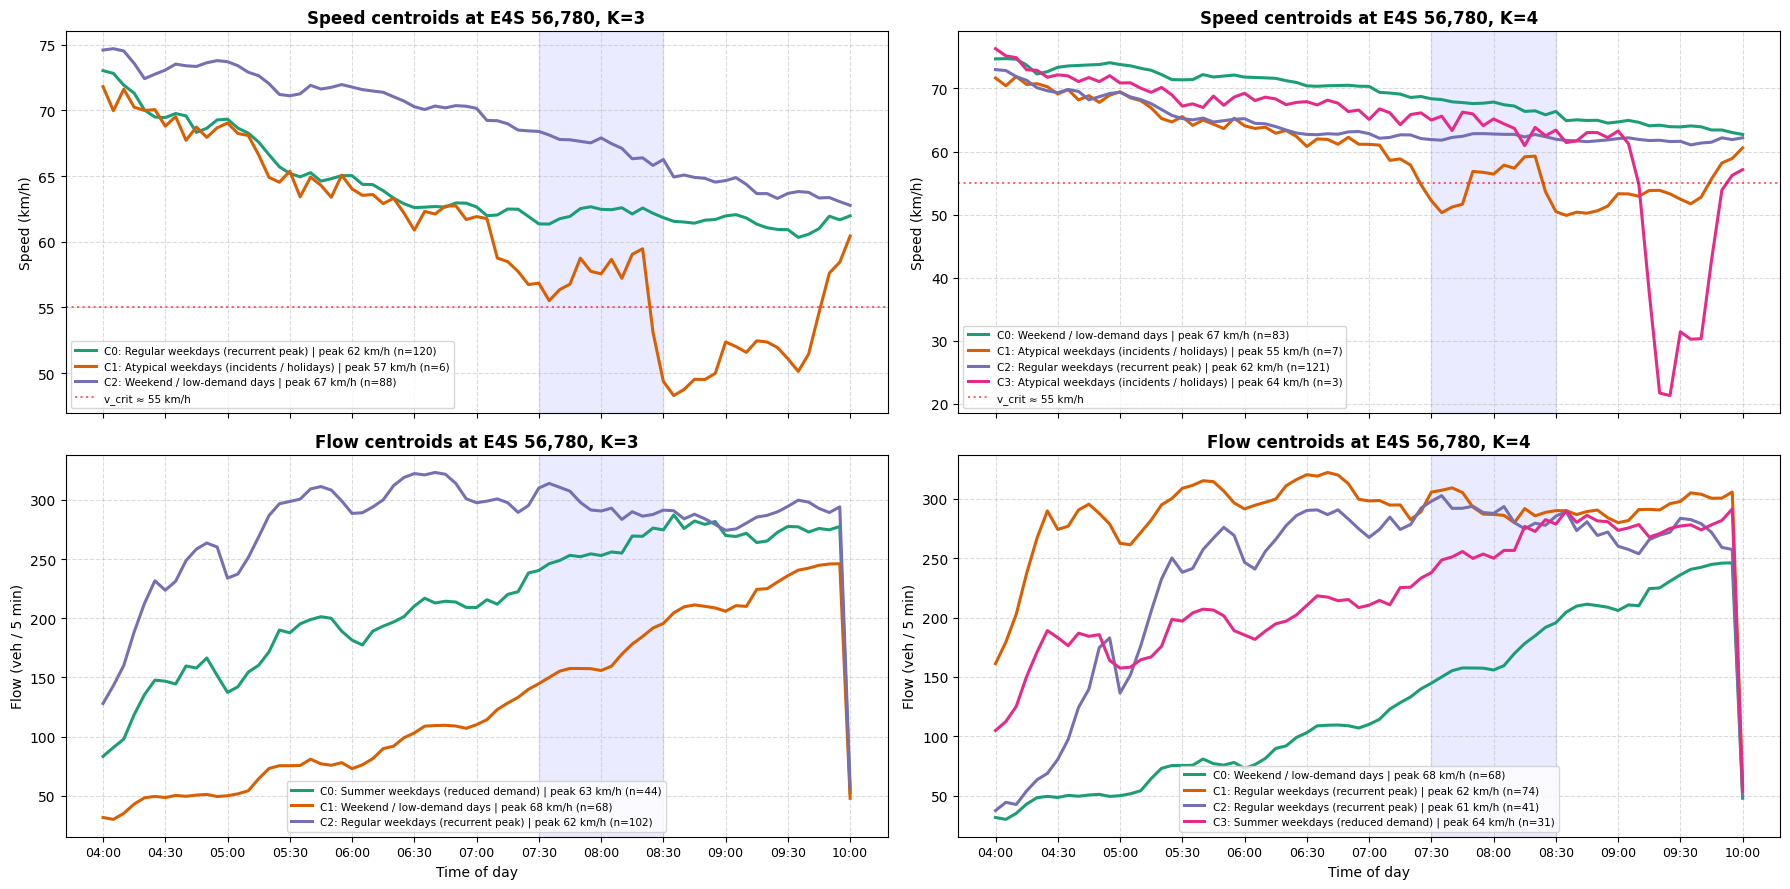

In [ ]:
sample_portal = BOTTLENECK_PORTAL
cols_sample = [c for c in day_matrix_speed.columns if c.startswith(sample_portal)]
time_strings = [c.split("_")[1] for c in cols_sample]
peak_cols = [c for c, t in zip(cols_sample, time_strings) if "07:30" <= t < "08:30"]
day_dates = pd.to_datetime(day_matrix_speed.index.astype(str), format="%Y%m%d")

# 1. Fit K-Means for speed and flow vectors, K = 3 and K = 4
models = {}
for name, data in [("Speed", day_matrix_speed), ("Flow", day_matrix_flow)]:
    for k in [3, 4]:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = km.fit_predict(data)
        models[f"{name}_K{k}"] = (km, labels, pd.DataFrame(km.cluster_centers_, columns=data.columns))


def name_clusters(labels):
    """Profile each cluster and give it a data-driven name."""
    n_days = len(labels)
    rows = []
    for c in np.unique(labels):
        m = labels == c
        rows.append({
            "Cluster": int(c),
            "Days": int(m.sum()),
            "Weekend share (%)": round(100 * (day_dates[m].dayofweek >= 5).mean(), 1),
            "Jul-Aug share (%)": round(100 * day_dates[m].month.isin([7, 8]).mean(), 1),
            "Peak speed at bottleneck (km/h)": round(float(day_matrix_speed.loc[m, peak_cols].values.mean()), 1),
            "Peak flow at bottleneck (veh/5 min)": round(float(day_matrix_flow.loc[m, peak_cols].values.mean()), 1),
        })
    prof = pd.DataFrame(rows).set_index("Cluster")
    names = {}
    for c, r in prof.iterrows():
        if r["Weekend share (%)"] >= 50:
            base = "Weekend / low-demand days"
        elif r["Days"] < 0.10 * n_days:
            base = "Atypical weekdays (incidents / holidays)"
        elif r["Jul-Aug share (%)"] >= 50:
            base = "Summer weekdays (reduced demand)"
        else:
            base = "Regular weekdays (recurrent peak)"
        names[c] = f"{base} | peak {r['Peak speed at bottleneck (km/h)']:.0f} km/h"
    prof["Name"] = pd.Series(names)
    return prof, names


cluster_names_all = {}
for key in models:
    prof, names = name_clusters(models[key][1])
    cluster_names_all[key] = names
    print(f"\n=== {key} ===")
    display(prof)

# 2. Composition tables (day type, day of week, month)
df_clusters = pd.DataFrame({"Date": day_matrix_speed.index.astype(str)})
df_clusters["DateTime"] = pd.to_datetime(df_clusters["Date"], format="%Y%m%d")
df_clusters["DayOfWeek"] = df_clusters["DateTime"].dt.day_name()
df_clusters["DayType"] = np.where(df_clusters["DateTime"].dt.dayofweek >= 5, "Weekend", "Weekday")
df_clusters["Month"] = df_clusters["DateTime"].dt.month_name()
for key in models:
    df_clusters[key] = models[key][1]

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
month_order = ["June", "July", "August", "September", "October", "November", "December"]
for title, col, order in [("DAY TYPE", "DayType", None), ("DAY OF WEEK", "DayOfWeek", day_order),
                          ("MONTH", "Month", month_order)]:
    print("\n" + "=" * 80 + f"\nCLUSTER COMPOSITION BY {title}\n" + "=" * 80)
    tab = pd.concat({key: pd.crosstab(df_clusters[key], df_clusters[col]) for key in models},
                    names=["Model", "Cluster"])
    if order:
        tab = tab.reindex(columns=order).fillna(0).astype(int)
    display(tab)

# 3. Centroid profiles at the bottleneck
fig, axes = plt.subplots(2, 2, figsize=(18, 9), sharex=True)
palette = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]
for row, (feat, ylab, ref) in enumerate([("Speed", "Speed (km/h)", 55), ("Flow", "Flow (veh / 5 min)", None)]):
    for col, k in enumerate([3, 4]):
        ax = axes[row, col]
        key = f"{feat}_K{k}"
        _, labels, centroids = models[key]
        for c in range(k):
            ax.plot(time_strings, centroids.loc[c, cols_sample], lw=2.2, color=palette[c],
                    label=f"C{c}: {cluster_names_all[key][c]} (n={(labels == c).sum()})")
        if ref:
            ax.axhline(ref, color="red", ls=":", alpha=0.6, label="v_crit ≈ 55 km/h")
        ax.axvspan("07:30", "08:30", color="blue", alpha=0.08)
        ax.set_xticks(range(0, len(time_strings), 6))
        ax.set_xticklabels(time_strings[::6], fontsize=9)
        ax.set_title(f"{feat} centroids at {sample_portal}, K={k}", fontweight="bold")
        ax.set_ylabel(ylab)
        ax.grid(True, ls="--", alpha=0.45)
        ax.legend(fontsize=7.5, loc="best")
for ax in axes[1, :]:
    ax.set_xlabel("Time of day")
plt.tight_layout(); plt.show()

**Interpretation.**
* **Speed, K = 3:** the days split into three clear groups:
  - **regular weekdays** (120 days), whose speed at the bottleneck drops gradually to about 62 km/h in the peak;
  - **weekend / low-demand days** (88 days, including most July–August weekdays), with the highest speeds all morning;
  - a small group of **atypical weekdays** (6 days), where speed collapses after about 08:30 to below 50 km/h, i.e. days with severe congestion or incidents.
* **Speed, K = 4:** the first three groups stay almost unchanged (83, 121 and 7 days). The additional group contains only **3 days**, whose speed drops to about 20 km/h between 09:15 and 09:45, after the target window. This is a handful of late incidents rather than a separate type of day.
* **Flow clusters** separate the calendar more clearly (with K = 4: weekends, summer weekdays and two kinds of regular weekdays) but say little about whether the bottleneck breaks down.

**Choice: speed-based K = 3.** K = 4 has a slightly better Silhouette and Davies–Bouldin score (Section 2.5), but only because it splits off 3 days with a late incident. Such a small group cannot be recognized from the pre-peak traffic (Section 3.1) and concerns events outside the target window. K = 3 separates the three main day types and keeps all groups large enough to use. Note that the smallest group (6 days) is still hard to recognize in real time (this is examined in Section 3.1).

*(The drop of all flow curves at 10:00 is not real: the last 5-minute interval contains only the single minute 10:00, because the data ends there.)*

In [ ]:
SELECTED_CLUSTER_MODEL = "Speed_K3"
N_CLUSTERS = 3
df_clusters["Cluster"] = df_clusters[SELECTED_CLUSTER_MODEL]
cluster_names = cluster_names_all[SELECTED_CLUSTER_MODEL]
df_clusters["Cluster_Name"] = df_clusters["Cluster"].map(cluster_names)

print(f"Selected clustering: {SELECTED_CLUSTER_MODEL}")
display(df_clusters["Cluster_Name"].value_counts().rename("Days"))
display(df_clusters[["Date", "DayOfWeek", "DayType", "Month", "Cluster", "Cluster_Name"]].head(10))

Selected clustering: Speed_K3


,Days
Cluster_Name,
Regular weekdays (recurrent peak) | peak 62 km/h,120
Weekend / low-demand days | peak 67 km/h,88
Atypical weekdays (incidents / holidays) | peak 57 km/h,6


,Date,DayOfWeek,DayType,Month,Cluster,Cluster_Name
0,20210601,Tuesday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
1,20210602,Wednesday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
2,20210603,Thursday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
3,20210604,Friday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
4,20210605,Saturday,Weekend,June,2,Weekend / low-demand days | peak 67 km/h
5,20210606,Sunday,Weekend,June,2,Weekend / low-demand days | peak 67 km/h
6,20210607,Monday,Weekday,June,1,Atypical weekdays (incidents / holidays) | pea...
7,20210608,Tuesday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
8,20210609,Wednesday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h
9,20210610,Thursday,Weekday,June,0,Regular weekdays (recurrent peak) | peak 62 km/h


# **PART 3: MODEL DEVELOPMENT (Task C)**

Overview of the modelling pipeline (all steps are causal, i.e. use only information available at the prediction origin):

1. **Regime classifier** (3.1): at 07:30 the day is assigned to one of the K = 3 regimes using only 06:00–07:29 traffic.
2. **Real-time pre-processing** (3.2): lane aggregation with lane-completeness correction, flow-weighted speed, a complete 1-minute grid, and causal imputation.
3. **Feature engineering** (3.3): temporal lags and rolling averages, neighbour and corridor states, physical features, calendar encodings, regime indicators.
4. **Baselines and metrics** (3.4).
5. **Model families:** Ridge (linear), XGBoost (gradient-boosted trees), recurrent neural network (LSTM/GRU). The NN architecture is chosen in 3.5 and Ridge/XGBoost are tuned in 3.6, all on 2021 data.
6. **Validation benchmark** (3.7) on Nov–Dec 2021, **feature-group removal test** for the 1-minute and 15-minute targets (3.8) and **final re-fit** on all of 2021 (3.9).

## 3.1 Real-time regime classifier (pre-peak, 06:00–07:29)
The clusters in Part 2 were built from the whole morning (04:00–10:00), including the peak we want to predict. At 07:30 in real time we do **not** know the rest of the morning, so the cluster cannot be used directly as a feature. Instead:

1. For every 2021 day, build the pre-peak vector: 5-minute flow per portal between 06:00 and 07:29 (8 × 18 = 144 values).
2. Compute the average pre-peak vector (centroid) of each Part-2 cluster.
3. Assign any day (training, validation or test) to the nearest centroid (Euclidean distance).

Missing pre-peak cells are filled with the training median of that portal-interval (filling with 0 would make a day look artificially empty). The training days are classified with the same rule, so the model is trained on exactly the kind of label it receives in operation. We also report how well the pre-peak assignment reproduces the full-morning clusters.

In [ ]:
def extract_prepeak_matrix(df_raw):
    """One row per day: 5-minute flow per portal for 06:00-07:29 (columns 'Portal_HH:MM')."""
    t = df_raw["Time"].astype(str)
    d = df_raw[(t >= "06:00:00") & (t < "07:30:00")].copy()
    d["Date_Str"] = d["Date"].astype(str)
    piv = d.pivot_table(index="Date_Str", columns=["PORTAL", "Interval_5"], values="FLOW", aggfunc="sum")
    piv.columns = [f"{p}_{int(i) * 5 // 60:02d}:{int(i) * 5 % 60:02d}" for p, i in piv.columns]
    return piv

# 1. Training pre-peak matrix + median fill values
prepeak_train = extract_prepeak_matrix(train_df)
feature_cols_prepeak = list(prepeak_train.columns)
prepeak_fill = prepeak_train.median()
prepeak_train = prepeak_train.fillna(prepeak_fill)

# 2. Centroids of the Part-2 clusters in pre-peak space
train_cluster_map = dict(zip(df_clusters["Date"].astype(str), df_clusters["Cluster"]))
true_cluster = prepeak_train.index.map(train_cluster_map)
valid = ~pd.isna(true_cluster)
CLUSTER_IDS = list(range(N_CLUSTERS))
centroids_prepeak = {
    k: prepeak_train[valid][np.asarray(true_cluster[valid]) == k].mean(axis=0).values for k in CLUSTER_IDS
}

def assign_realtime_clusters(df_raw):
    """Assign each day to the nearest pre-peak centroid. Returns {Date_Str: cluster}."""
    m = extract_prepeak_matrix(df_raw).reindex(columns=feature_cols_prepeak).fillna(prepeak_fill)
    dist = np.stack([np.linalg.norm(m.values - centroids_prepeak[k], axis=1) for k in CLUSTER_IDS])
    return dict(zip(m.index, np.array(CLUSTER_IDS)[dist.argmin(axis=0)]))

train_regimes = assign_realtime_clusters(train_df)
DEFAULT_REGIME = pd.Series(train_regimes).mode().iloc[0]   # used if a day has no pre-peak data

# 3. How well does the pre-peak assignment reproduce the full-morning clusters?
dates_ok = [d for d in prepeak_train.index[valid]]
y_true_c = np.array([train_cluster_map[d] for d in dates_ok])
y_pred_c = np.array([train_regimes[d] for d in dates_ok])
print(f"Agreement pre-peak assignment vs. full-morning cluster (2021, in-sample): "
      f"{accuracy_score(y_true_c, y_pred_c) * 100:.1f}%")
display(pd.DataFrame(
    confusion_matrix(y_true_c, y_pred_c, labels=CLUSTER_IDS),
    index=[f"true C{k}: {cluster_names[k].split('|')[0]}" for k in CLUSTER_IDS],
    columns=[f"assigned C{k}" for k in CLUSTER_IDS],
))

Agreement pre-peak assignment vs. full-morning cluster (2021, in-sample): 81.8%


,assigned C0,assigned C1,assigned C2
true C0: Regular weekdays (recurrent peak),100,13,7
true C1: Atypical weekdays (incidents / holidays),3,2,1
true C2: Weekend / low-demand days,1,14,73


**Interpretation.** The pre-peak assignment agrees with the full-morning clusters on about 82% of the 2021 days. Weekends/low-demand days and regular weekdays are recognized well, because the demand level is already visible at 06:00–07:30. The small "atypical/incident" cluster is hard to recognize: incidents usually happen *during* the peak and cannot be foreseen at 07:30, and with only six days the centroid is unstable (only 2 of 6 are recognized, and 13 regular weekdays are assigned to this group). The day-type feature therefore mainly carries **demand-level** information. Whether it improves the forecasts is tested in the feature-group removal test (3.8, H4).

## 3.2 Real-time pre-processing pipeline
For every dataset (2021 training, 2022 test) the same three steps are applied:

1. **Aggregate lanes → portal:** flow = sum over detectors, corrected for missing detectors (× expected/observed detectors); speed = **flow-weighted** average speed (consistent with Part 2).
2. **Regularize** onto a complete 1-minute grid (06:00–10:00) for every day and portal, so that "lag $k$" always means *k minutes ago*.
3. **Causal imputation:** a missing minute is forward-filled from the last observation (max 3 minutes). Longer gaps get the historical median for that portal, day type (weekday/weekend) and time of day, computed from the **2021 training data only**.

Linear interpolation or the median of the same day would use *later* observations, which are not available in real time.

In [ ]:
def aggregate_portal_minutes(df, expected_detectors=None):
    """Lane detectors -> portal-minute flow (lane-corrected) and flow-weighted speed."""
    expected_detectors = EXPECTED_DETECTORS if expected_detectors is None else expected_detectors
    d = df.copy()
    d["Date_Str"] = d["Date"].astype(str)
    d["DateTime"] = pd.to_datetime(d["Date_Str"] + " " + d["Time"].astype(str),
                                   format="%Y%m%d %H:%M:%S", errors="coerce")
    d = d.dropna(subset=["DateTime"])
    d["FxV"] = d["FLOW"] * d["SPEED_KMH"]
    d["FLOW_WITH_SPEED"] = d["FLOW"].where(d["SPEED_KMH"].notna())
    g = d.groupby(["Date_Str", "DateTime", "PORTAL"]).agg(
        FLOW=("FLOW", "sum"), FxV=("FxV", "sum"), FV=("FLOW_WITH_SPEED", "sum"), N_DET=("DP_ID", "nunique"),
    ).reset_index()
    g["SPEED_KMH"] = np.where(g["FV"] > 0, g["FxV"] / g["FV"].replace(0, np.nan), np.nan)
    expected = g["PORTAL"].map(expected_detectors).astype(float)
    g["LANE_CORRECTED"] = g["N_DET"] < expected
    g["FLOW"] = g["FLOW"] * expected / g["N_DET"]
    return g[["Date_Str", "DateTime", "PORTAL", "FLOW", "SPEED_KMH", "LANE_CORRECTED"]]


def regularize_grid(df_min, start=HISTORY_START, end=GRID_END, portals=CORRIDOR_PORTALS):
    """Complete Date x minute x portal grid; minutes without data become NaN."""
    dates = sorted(df_min["Date_Str"].unique())
    tod = pd.timedelta_range(start=start, end=end, freq="1min")
    grid = pd.MultiIndex.from_product([dates, tod, portals], names=["Date_Str", "TOD", "PORTAL"]).to_frame(index=False)
    grid["DateTime"] = pd.to_datetime(grid["Date_Str"], format="%Y%m%d") + grid["TOD"]
    grid = grid.drop(columns="TOD").merge(
        df_min[["DateTime", "PORTAL", "FLOW", "SPEED_KMH"]], on=["DateTime", "PORTAL"], how="left"
    )
    grid["IS_MISSING"] = grid["FLOW"].isna()
    return grid


def build_tod_profile(grid_train):
    """Historical median per portal, day type (0 weekday / 1 weekend) and time of day."""
    g = grid_train.copy()
    g["DAYTYPE"] = (g["DateTime"].dt.dayofweek >= 5).astype(int)
    g["TOD"] = g["DateTime"].dt.strftime("%H:%M")
    return g.groupby(["PORTAL", "DAYTYPE", "TOD"])[["FLOW", "SPEED_KMH"]].median()


def impute_causal(grid, tod_profile, ffill_limit=3):
    """Forward-fill short gaps, then historical profile, then portal median (all causal)."""
    g = grid.sort_values(["PORTAL", "DateTime"]).copy()
    for col in ["FLOW", "SPEED_KMH"]:
        g[col] = g.groupby(["PORTAL", "Date_Str"])[col].ffill(limit=ffill_limit)
    g["DAYTYPE"] = (g["DateTime"].dt.dayofweek >= 5).astype(int)
    g["TOD"] = g["DateTime"].dt.strftime("%H:%M")
    hist = tod_profile.add_suffix("_HIST").reset_index()
    g = g.merge(hist, on=["PORTAL", "DAYTYPE", "TOD"], how="left")
    portal_median = tod_profile.groupby(level="PORTAL").median()
    for col in ["FLOW", "SPEED_KMH"]:
        g[col] = g[col].fillna(g[f"{col}_HIST"]).fillna(g["PORTAL"].map(portal_median[col]))
    g = g.drop(columns=["DAYTYPE", "TOD", "FLOW_HIST", "SPEED_KMH_HIST"])
    return g.sort_values(["PORTAL", "DateTime"]).reset_index(drop=True)


def missing_report(grid_raw, df_min_agg, name):
    t = grid_raw["DateTime"].dt.strftime("%H:%M")
    peak = (t >= "07:15") & (t <= "08:45")
    return {"Dataset": name,
            "Days": grid_raw["Date_Str"].nunique(),
            "Missing portal-minutes, all (%)": round(grid_raw["IS_MISSING"].mean() * 100, 2),
            "Missing portal-minutes, 07:15-08:45 (%)": round(grid_raw.loc[peak, "IS_MISSING"].mean() * 100, 2),
            "Lane-corrected portal-minutes (%)": round(df_min_agg["LANE_CORRECTED"].mean() * 100, 2)}

# --- 2021 training data: the historical profile is computed here and reused everywhere
train_agg = aggregate_portal_minutes(train_df)
train_grid = regularize_grid(train_agg)
TOD_PROFILE = build_tod_profile(train_grid)
train_min = impute_causal(train_grid, TOD_PROFILE)

# --- 2022 final test set
test_agg = aggregate_portal_minutes(final_eval_df)
test_grid = regularize_grid(test_agg)
final_eval_min = impute_causal(test_grid, TOD_PROFILE)

reports = [missing_report(train_grid, train_agg, "Training 2021"),
           missing_report(test_grid, test_agg, "Final evaluation 2022")]

# --- extra independent days from evaluation_dataset (only if it has days not in the final file)
eval_only_df = eval_df[eval_df["Date"].astype(str).isin(EVAL_ONLY_DATES)]
if len(eval_only_df):
    eo_agg = aggregate_portal_minutes(eval_only_df)
    eo_grid = regularize_grid(eo_agg)
    eval_only_min = impute_causal(eo_grid, TOD_PROFILE)
    reports.append(missing_report(eo_grid, eo_agg, "Evaluation-only days 2022"))
else:
    eval_only_min = None

display(pd.DataFrame(reports).set_index("Dataset"))

# --- regime assignment (pre-peak only) for the 2022 data
test_regimes = assign_realtime_clusters(final_eval_df)
eval_only_regimes = assign_realtime_clusters(eval_only_df) if len(eval_only_df) else {}
print("Assigned regimes in the 2022 test set:")
display(pd.Series(test_regimes).map(lambda c: cluster_names[c]).value_counts().rename("Days"))

,Days,"Missing portal-minutes, all (%)","Missing portal-minutes, 07:15-08:45 (%)",Lane-corrected portal-minutes (%)
Dataset,,,,
Training 2021,214,1.79,1.72,29.86
Final evaluation 2022,91,4.57,4.88,27.35
Evaluation-only days 2022,90,3.45,3.38,27.92


Assigned regimes in the 2022 test set:


,Days
Regular weekdays (recurrent peak) | peak 62 km/h,51
Weekend / low-demand days | peak 67 km/h,28
Atypical weekdays (incidents / holidays) | peak 57 km/h,12


## 3.3 Feature engineering and sample extraction
For each target portal and each minute we build (all from information at time $\le t$):

| Group | Features | Hypothesis |
|---|---|---|
| Own history | `FLOW_LAG_k`, `SPEED_LAG_k` for $k \in \{0,1,2,3,5,10,15\}$; rolling averages of the previous 5 and 15 minutes | H1 |
| Physical | density proxy $k = q / v$ (lags 0, 1) | H3 |
| Spatial | upstream & downstream flow and speed at $t$, speed gradient (downstream − upstream), flow at all other corridor portals at $t$ | H2 |
| Calendar | sin/cos of minute-of-day and day-of-week, weekend flag | H4 |
| Regime | one-hot pre-peak regime (`CLUSTER_0..2`) | H4 |

**Targets:** $q_{t+1}, \dots, q_{t+15}$ (1-minute forecast) and their average (15-minute target).
**Samples:** one per day and origin between 07:30 and 08:30. The tabular models (Ridge, XGBoost) use the feature vector at $t$. The recurrent networks use the sequence of the last 15 feature vectors $(t-14, \dots, t)$.

The corridor flow of the *target* portal itself is not used (it would duplicate `FLOW_LAG_0`), and days without pre-peak data get the most frequent day type.

In [ ]:
def get_corridor_neighbors(portals):
    """Upstream and downstream neighbour of each portal along the corridor."""
    return {p: {"upstream": portals[i - 1] if i > 0 else None,
                "downstream": portals[i + 1] if i < len(portals) - 1 else None}
            for i, p in enumerate(portals)}

PORTAL_NEIGHBORS = get_corridor_neighbors(CORRIDOR_PORTALS)
LAGS = [0, 1, 2, 3, 5, 10, 15]
NON_FEATURES = {"Date_Str", "DateTime", "PORTAL", "FLOW", "SPEED_KMH", "TimeOnly",
                "Assigned_Cluster", "IS_MISSING", "LANE_CORRECTED"}
META_COLS = ["Date_Str", "DateTime", "TimeOnly", "FLOW", "SPEED_KMH",
             "FLOW_MA15_INCL", "SPEED_KMH_MA15_INCL", "Assigned_Cluster"]


def build_feature_table(df_clean, target_portal, day_clusters, target_var="FLOW"):
    """Causal features + targets (t+1..t+15 and their average) for one portal."""
    target_df = df_clean[df_clean["PORTAL"] == target_portal].sort_values("DateTime").copy()
    target_df["TimeOnly"] = target_df["DateTime"].dt.strftime("%H:%M")

    # Own history: lags (lag 0 = latest complete minute t)
    for lag in LAGS:
        target_df[f"FLOW_LAG_{lag}"] = target_df.groupby("Date_Str")["FLOW"].shift(lag)
        target_df[f"SPEED_LAG_{lag}"] = target_df.groupby("Date_Str")["SPEED_KMH"].shift(lag)

    # Rolling averages of the previous 5 / 15 minutes (shifted: exclude minute t)
    for var, short in [("FLOW", "FLOW"), ("SPEED_KMH", "SPEED")]:
        for w in [5, 15]:
            target_df[f"{short}_ROLL_{w}"] = target_df.groupby("Date_Str")[var].transform(
                lambda x, w=w: x.shift(1).rolling(w).mean())
        # Average of t-14..t (used only by the moving-average baseline, not as a feature)
        target_df[f"{var}_MA15_INCL"] = target_df.groupby("Date_Str")[var].transform(
            lambda x: x.rolling(15).mean())

    # Upstream / downstream neighbour state at t
    for p, prefix in [(PORTAL_NEIGHBORS[target_portal]["upstream"], "UPSTREAM"),
                      (PORTAL_NEIGHBORS[target_portal]["downstream"], "DOWNSTREAM")]:
        if p is not None:
            p_slice = df_clean[df_clean["PORTAL"] == p][["DateTime", "FLOW", "SPEED_KMH"]].rename(
                columns={"FLOW": f"{prefix}_FLOW", "SPEED_KMH": f"{prefix}_SPEED"})
            target_df = target_df.merge(p_slice, on="DateTime", how="left")

    # Physical features: density proxy k = q / v and spatial speed gradient
    target_df["DENSITY_LAG_0"] = target_df["FLOW_LAG_0"] / (target_df["SPEED_LAG_0"] + 1e-3)
    target_df["DENSITY_LAG_1"] = target_df["FLOW_LAG_1"] / (target_df["SPEED_LAG_1"] + 1e-3)
    if {"DOWNSTREAM_SPEED", "UPSTREAM_SPEED"} <= set(target_df.columns):
        target_df["SPATIAL_SPEED_GRADIENT"] = target_df["DOWNSTREAM_SPEED"] - target_df["UPSTREAM_SPEED"]
    else:
        target_df["SPATIAL_SPEED_GRADIENT"] = 0.0

    # Corridor-wide flow at t (other portals only)
    corridor = df_clean.pivot_table(index="DateTime", columns="PORTAL", values="FLOW", aggfunc="mean")
    corridor = corridor.drop(columns=[target_portal], errors="ignore")
    corridor.columns = [f"CORRIDOR_FLOW_{c}" for c in corridor.columns]
    target_df = target_df.merge(corridor.reset_index(), on="DateTime", how="left")

    # Calendar encodings
    minutes = target_df["DateTime"].dt.hour * 60 + target_df["DateTime"].dt.minute
    target_df["TIME_SIN"] = np.sin(2 * np.pi * minutes / 1440)
    target_df["TIME_COS"] = np.cos(2 * np.pi * minutes / 1440)
    dow = target_df["DateTime"].dt.dayofweek
    target_df["DAY_SIN"] = np.sin(2 * np.pi * dow / 7)
    target_df["DAY_COS"] = np.cos(2 * np.pi * dow / 7)
    target_df["IS_WEEKEND"] = (dow >= 5).astype(int)

    # Regime (pre-peak assignment)
    target_df["Assigned_Cluster"] = target_df["Date_Str"].map(day_clusters).fillna(DEFAULT_REGIME).astype(int)
    for c in CLUSTER_IDS:
        target_df[f"CLUSTER_{c}"] = (target_df["Assigned_Cluster"] == c).astype(int)

    # Targets
    target_cols_1min = []
    for h in range(1, HORIZON + 1):
        col = f"TARGET_{target_var}_T_PLUS_{h}"
        target_df[col] = target_df.groupby("Date_Str")[target_var].shift(-h)
        target_cols_1min.append(col)
    target_col_15 = f"TARGET_{target_var}_15MIN_AVG"
    target_df[target_col_15] = target_df[target_cols_1min].mean(axis=1, skipna=False)
    return target_df.reset_index(drop=True), target_cols_1min, target_col_15


def get_feature_cols(df_features):
    return [c for c in df_features.columns
            if c not in NON_FEATURES and not c.startswith("TARGET_") and not c.endswith("_MA15_INCL")]


def extract_peak_arrays(df_features, feature_cols, target_cols, peak_start=PEAK_START, peak_end=PEAK_END):
    """One sample per day and origin in [peak_start, peak_end]: flat X, sequence X, targets, metadata."""
    X_flat, X_seq, Y, metas = [], [], [], []
    for _, day in df_features.groupby("Date_Str", sort=True):
        day = day.sort_values("DateTime").reset_index(drop=True)
        F = day[feature_cols].to_numpy(dtype=np.float32)
        T = day[target_cols].to_numpy(dtype=np.float32)
        tod = day["TimeOnly"].to_numpy()
        idx = np.where((tod >= peak_start) & (tod <= peak_end))[0]
        keep = []
        for i in idx[idx >= SEQUENCE_LEN - 1]:
            window = F[i - SEQUENCE_LEN + 1: i + 1]
            if np.isnan(window).any() or np.isnan(T[i]).any():
                continue
            X_flat.append(window[-1]); X_seq.append(window); Y.append(T[i]); keep.append(i)
        metas.append(day.loc[keep, META_COLS])
    meta = pd.concat(metas, ignore_index=True) if metas else pd.DataFrame(columns=META_COLS)
    n_f, n_t = len(feature_cols), len(target_cols)
    return (np.array(X_flat, dtype=np.float32).reshape(-1, n_f),
            np.array(X_seq, dtype=np.float32).reshape(-1, SEQUENCE_LEN, n_f),
            np.array(Y, dtype=np.float32).reshape(-1, n_t),
            meta)


def make_dataset(df_min, portal, regimes, target_var="FLOW", feature_cols=None):
    """Feature table -> arrays for one portal. Pass the training feature_cols for test data."""
    df_feat, t1, t15 = build_feature_table(df_min, portal, regimes, target_var)
    fcols = get_feature_cols(df_feat) if feature_cols is None else feature_cols
    Xf, Xs, Y, meta = extract_peak_arrays(df_feat, fcols, t1 + [t15])
    return {"portal": portal, "target_var": target_var, "feature_cols": fcols,
            "X_flat": Xf, "X_seq": Xs, "y1": Y[:, :HORIZON], "y15": Y[:, HORIZON], "meta": meta}


def subset_ds(ds, rows):
    out = {k: (v[rows] if isinstance(v, np.ndarray) else v) for k, v in ds.items()}
    out["meta"] = ds["meta"].iloc[rows].reset_index(drop=True)
    return out


def split_rows(ds):
    """2021 chronological split: train = before VAL_START, validation = from VAL_START."""
    is_val = (ds["meta"]["Date_Str"].astype(str) >= VAL_START).to_numpy()
    return np.where(~is_val)[0], np.where(is_val)[0]


def feature_groups(cols):
    return {
        "Speed & density (H3)": [c for c in cols if "SPEED" in c or "DENSITY" in c],
        "Spatial: neighbours & corridor (H2)": [c for c in cols if c.startswith(("UPSTREAM", "DOWNSTREAM", "CORRIDOR", "SPATIAL"))],
        "Regime clusters (H4)": [c for c in cols if c.startswith("CLUSTER_")],
        "Calendar / time of day (H4)": [c for c in cols if c.startswith(("TIME_", "DAY_", "IS_WEEKEND"))],
    }


# ---------------------------------------------------------------- build all datasets
DATA = {"train": {}, "test": {}, "eval_only": {}}
for portal in TARGET_PORTALS:
    DATA["train"][portal] = make_dataset(train_min, portal, train_regimes)
    fcols = DATA["train"][portal]["feature_cols"]
    DATA["test"][portal] = make_dataset(final_eval_min, portal, test_regimes, feature_cols=fcols)
    if eval_only_min is not None:
        DATA["eval_only"][portal] = make_dataset(eval_only_min, portal, eval_only_regimes, feature_cols=fcols)

rows = []
for portal in TARGET_PORTALS:
    tr, va = split_rows(DATA["train"][portal])
    rows.append({"Portal": portal, "Features": len(DATA["train"][portal]["feature_cols"]),
                 "2021 train samples (Jun-Oct)": len(tr), "2021 validation samples (Nov-Dec)": len(va),
                 "2022 test samples": len(DATA["test"][portal]["y1"]),
                 "Extra eval-only samples": len(DATA["eval_only"][portal]["y1"]) if DATA["eval_only"] else 0})
display(pd.DataFrame(rows).set_index("Portal"))

FEATURE_COLS = DATA["train"][BOTTLENECK_PORTAL]["feature_cols"]
print("\nFeature groups:")
for g, cols in feature_groups(FEATURE_COLS).items():
    print(f"  {g:40s}: {len(cols):2d} features")
print("\nAll features:", FEATURE_COLS)

,Features,2021 train samples (Jun-Oct),2021 validation samples (Nov-Dec),2022 test samples,Extra eval-only samples
Portal,,,,,
"E4S 57,055",40,9333,3721,5551,5490
"E4S 56,780",40,9333,3721,5551,5490
"E4S 56,490",40,9333,3721,5551,5490



Feature groups:
  Speed & density (H3)                    : 14 features
  Spatial: neighbours & corridor (H2)     : 12 features
  Regime clusters (H4)                    :  3 features
  Calendar / time of day (H4)             :  5 features

All features: ['FLOW_LAG_0', 'SPEED_LAG_0', 'FLOW_LAG_1', 'SPEED_LAG_1', 'FLOW_LAG_2', 'SPEED_LAG_2', 'FLOW_LAG_3', 'SPEED_LAG_3', 'FLOW_LAG_5', 'SPEED_LAG_5', 'FLOW_LAG_10', 'SPEED_LAG_10', 'FLOW_LAG_15', 'SPEED_LAG_15', 'FLOW_ROLL_5', 'FLOW_ROLL_15', 'SPEED_ROLL_5', 'SPEED_ROLL_15', 'UPSTREAM_FLOW', 'UPSTREAM_SPEED', 'DOWNSTREAM_FLOW', 'DOWNSTREAM_SPEED', 'DENSITY_LAG_0', 'DENSITY_LAG_1', 'SPATIAL_SPEED_GRADIENT', 'CORRIDOR_FLOW_E4S 55,620', 'CORRIDOR_FLOW_E4S 56,160', 'CORRIDOR_FLOW_E4S 56,490', 'CORRIDOR_FLOW_E4S 57,055', 'CORRIDOR_FLOW_E4S 57,435', 'CORRIDOR_FLOW_E4S 57,820', 'CORRIDOR_FLOW_E4S 58,140', 'TIME_SIN', 'TIME_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'CLUSTER_0', 'CLUSTER_1', 'CLUSTER_2']


## 3.4 Metrics and baselines
**Metrics** (computed over all samples and horizons):
* MAE = average |y − ŷ| (veh/min) — main criterion, easy to interpret;
* RMSE — penalizes large errors (e.g. missed breakdowns);
* MAPE (%) — relative error per sample; unstable when flows are small;
* WAPE (%) = Σ|y − ŷ| / Σy — a relative error that is stable with low flows and comparable between targets of different scale.

**Baselines** (a model is only useful if it beats these):
* **Persistence:** the flow at $t$ is repeated for all horizons.
* **15-min moving average:** the average of $t-14 \dots t$ is repeated.
* **Historical profile:** the 2021 median for the portal, day type and **target** time $t+h$.

At the 15-minute level the baselines are the average of their 15 one-minute values.

In [ ]:
def metric_row(y_true, y_pred):
    yt, yp = np.ravel(y_true).astype(float), np.ravel(y_pred).astype(float)
    nz = yt > 0
    return {"MAE": mean_absolute_error(yt, yp),
            "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
            "MAPE (%)": float(np.mean(np.abs((yt[nz] - yp[nz]) / yt[nz])) * 100) if nz.any() else np.nan,
            "WAPE (%)": float(np.sum(np.abs(yt - yp)) / np.sum(yt) * 100)}


def results_rows(y_true, preds, portal):
    return [{"Portal": portal, "Model": name, **metric_row(y_true, p)} for name, p in preds.items()]


def horizon_rows(y_true, preds, portal):
    return [{"Portal": portal, "Model": name, "Horizon": h + 1,
             "MAE": mean_absolute_error(y_true[:, h], p[:, h])}
            for name, p in preds.items() for h in range(HORIZON)]


def baseline_predictions(ds, var="FLOW"):
    """Persistence, 15-min moving average and historical profile at the target time."""
    meta = ds["meta"]
    n = len(meta)
    pers = np.tile(meta[var].to_numpy(dtype=float)[:, None], (1, HORIZON))
    ma = np.tile(meta[f"{var}_MA15_INCL"].to_numpy(dtype=float)[:, None], (1, HORIZON))
    lookup = TOD_PROFILE[var].xs(ds["portal"], level="PORTAL").to_dict()
    fallback = float(np.nanmedian(list(lookup.values())))
    daytype = (meta["DateTime"].dt.dayofweek >= 5).astype(int).to_numpy()
    hist = np.empty((n, HORIZON))
    for h in range(1, HORIZON + 1):
        tods = (meta["DateTime"] + pd.Timedelta(minutes=h)).dt.strftime("%H:%M").to_numpy()
        hist[:, h - 1] = [lookup.get((dt, tt), fallback) for dt, tt in zip(daytype, tods)]
    hist = np.where(np.isnan(hist), fallback, hist)
    return {"Persistence": pers, "15-min moving avg": ma, "Historical profile": hist}

BASELINES = ["Persistence", "15-min moving avg", "Historical profile"]
print("Metric and baseline functions ready.")

Metric and baseline functions ready.


## 3.5 Recurrent neural network: architecture selection
Four recurrent candidates are trained on the bottleneck portal (Jun–Oct 2021) and compared on Nov–Dec 2021 with early stopping:

| Candidate | Layers | Loss | Learning rate | Dropout |
|---|---|---|---|---|
| LSTM_MSE | LSTM 32 → LSTM 16 → Dense 16 | MSE | 2e-4 | 0.25 |
| LSTM_Huber | same | Huber (δ = 8 veh/min) | 2e-4 | 0.25 |
| GRU_Compact | GRU 24 → GRU 12 → Dense 16 | MSE | 2e-4 | 0.25 |
| LSTM_MAE | same as LSTM_MSE | MAE | 2e-4 | 0.25 |

**Why these settings.** In the first version every network reached its best validation loss after only 1–2 epochs and then overfitted: the training loss kept falling while the validation loss rose. At 1-minute resolution most of the target variation is random arrival noise, so once the network has learned the level and shape of the peak, it can only improve on the training data by memorising that noise. We therefore:
* use smaller layers, more dropout and a lower learning rate, so learning is slower and the best epoch is better defined;
* feed the network only the *current-state* features at each time step (flow, speed, density, neighbours, corridor, calendar, regime). The sequence of 15 steps already contains the recent history, so the lag and rolling-average features (kept for Ridge/XGBoost) would be redundant and only add parameters;
* report the validation error on both the 1-minute values and the 15-minute flow, and **select on the 15-minute flow**, which is the operational target;
* train the final models for exactly the validated best number of epochs (no minimum).

All candidates end with a fixed `Rescaling` layer that maps the network output back to veh/min (target scaling), so the saved `.keras` model outputs veh/min directly.

*Note:* the candidates are compared on a single split with a single random seed, so differences of a few hundredths of a veh/min are not meaningful.

RNN sequence input: 23 of 40 features per time step
['FLOW_LAG_0', 'SPEED_LAG_0', 'UPSTREAM_FLOW', 'UPSTREAM_SPEED', 'DOWNSTREAM_FLOW', 'DOWNSTREAM_SPEED', 'DENSITY_LAG_0', 'SPATIAL_SPEED_GRADIENT', 'CORRIDOR_FLOW_E4S 55,620', 'CORRIDOR_FLOW_E4S 56,160', 'CORRIDOR_FLOW_E4S 56,490', 'CORRIDOR_FLOW_E4S 57,055', 'CORRIDOR_FLOW_E4S 57,435', 'CORRIDOR_FLOW_E4S 57,820', 'CORRIDOR_FLOW_E4S 58,140', 'TIME_SIN', 'TIME_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'CLUSTER_0', 'CLUSTER_1', 'CLUSTER_2']
LSTM_MSE     best epoch  9/17 | val MAE 1-min 8.15 | val MAE 15-min 4.86
LSTM_Huber   best epoch  6/14 | val MAE 1-min 8.12 | val MAE 15-min 4.85
GRU_Compact  best epoch  6/14 | val MAE 1-min 7.78 | val MAE 15-min 4.24
LSTM_MAE     best epoch  6/14 | val MAE 1-min 8.11 | val MAE 15-min 4.85


,Architecture,Loss,Best epoch,Epochs run,MAE 1-min,WAPE 1-min (%),MAE 15-min,WAPE 15-min (%)
0,GRU_Compact,mse,6,14,7.78,16.480000,4.24,8.98
1,LSTM_MAE,mae,6,14,8.11,17.200001,4.85,10.28
2,LSTM_Huber,huber,6,14,8.12,17.209999,4.85,10.28
3,LSTM_MSE,mse,9,17,8.15,17.270000,4.86,10.31



Selected: GRU_Compact (by MAE 15-min), final models trained for 6 epochs.
Spread of MAE 15-min between candidates: 0.62 veh/min (single split, single seed: small differences are not significant).


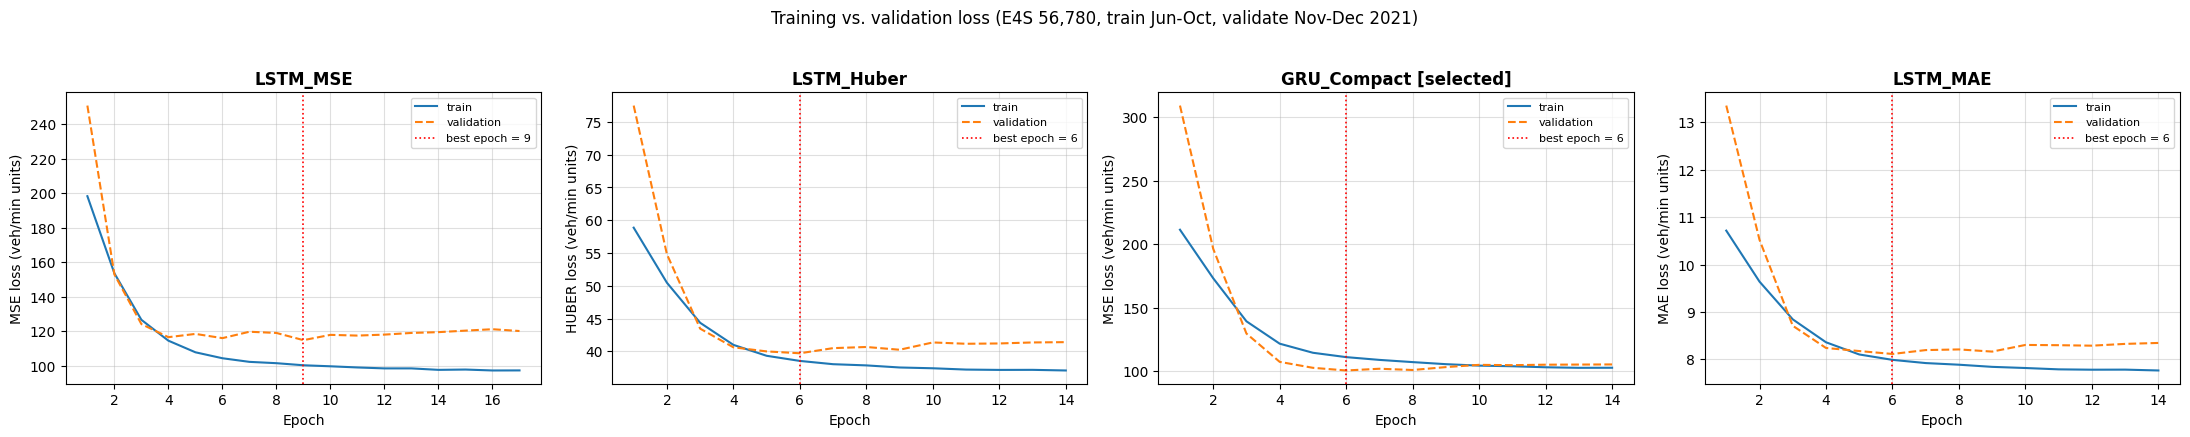

In [ ]:
# ==============================================================================
# 3.5 RECURRENT NEURAL NETWORK: ARCHITECTURE SELECTION (revised)
# ==============================================================================
# Changes vs. previous version:
#  1. No minimum number of epochs: the final models use the validated best epoch.
#  2. Slower, more regularized training (lower learning rate, more dropout,
#     smaller layers) so the validation optimum is not reached after 1-2 epochs.
#  3. Leaner sequence input: the sequence itself covers t-14..t, so lag and
#     rolling-average features are removed from the RNN input (Ridge/XGBoost keep them).
#  4. Candidates are compared on the 1-min MAE AND on the 15-min flow MAE
#     (average of the 15 predictions); selection uses the 15-min flow (main target).
#  5. Loss curves numbered from epoch 1, with the best epoch marked.
# ==============================================================================
import re

# ---------------------------------------------------------------- 3. lean sequence input
def is_sequence_feature(col):
    """Keep current-state features; drop lags > 0, rolling averages and lagged density."""
    if re.fullmatch(r"(FLOW|SPEED)_LAG_([1-9]\d*)", col):
        return False
    if "_ROLL_" in col or col == "DENSITY_LAG_1":
        return False
    return True

SEQ_IDX = [i for i, c in enumerate(FEATURE_COLS) if is_sequence_feature(c)]
SEQ_FEATURES = [FEATURE_COLS[i] for i in SEQ_IDX]

# The same positions must be valid for every portal (corridor column names differ per portal)
for p in TARGET_PORTALS:
    cols_p = DATA["train"][p]["feature_cols"]
    assert len(cols_p) == len(FEATURE_COLS) and all(
        is_sequence_feature(cols_p[i]) for i in SEQ_IDX), f"feature order differs for {p}"
print(f"RNN sequence input: {len(SEQ_FEATURES)} of {len(FEATURE_COLS)} features per time step")
print(SEQ_FEATURES)


def scale_seq(scaler, X_seq):
    """Scale with the (tabular) scaler, then keep only the sequence features."""
    n, t, f = X_seq.shape
    Xs = scaler.transform(X_seq.reshape(-1, f)).reshape(n, t, f).astype(np.float32)
    return Xs[:, :, SEQ_IDX]


def build_recurrent(cfg, input_shape, horizon, y_mean, y_std):
    """Two-layer LSTM/GRU with output rescaling to veh/min (target scaling)."""
    input_shape = (input_shape[0], len(SEQ_IDX))      # sequence features only
    cell = GRU if cfg["cell"] == "GRU" else LSTM
    model = Sequential([
        Input(shape=input_shape),
        cell(cfg["units1"], return_sequences=True),
        Dropout(cfg["dropout"]),
        cell(cfg["units2"]),
        Dropout(cfg["dropout"]),
        Dense(16, activation="relu"),
        Dense(horizon),
        Rescaling(scale=float(y_std), offset=float(y_mean)),   # standardized -> veh/min
    ])
    loss = {"mse": "mse", "mae": "mae",
            "huber": tf.keras.losses.Huber(delta=cfg.get("delta", 1.0))}[cfg["loss"]]
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=cfg["lr"]), loss=loss, metrics=["mae"])
    return model


# ---------------------------------------------------------------- 2. regularized candidates
NN_CANDIDATES = {
    "LSTM_MSE":    dict(cell="LSTM", units1=32, units2=16, dropout=0.25, loss="mse", lr=2e-4),
    "LSTM_Huber":  dict(cell="LSTM", units1=32, units2=16, dropout=0.25, loss="huber", delta=8.0, lr=2e-4),
    "GRU_Compact": dict(cell="GRU",  units1=24, units2=12, dropout=0.25, loss="mse", lr=2e-4),
    "LSTM_MAE":    dict(cell="LSTM", units1=32, units2=16, dropout=0.25, loss="mae", lr=2e-4),
}
MAX_EPOCHS = 60
NN_SELECTION_METRIC = "MAE 15-min"      # main target (Trafikverket); alternative: "MAE 1-min"

ds_b = DATA["train"][BOTTLENECK_PORTAL]
tr_b, va_b = split_rows(ds_b)
scaler_b = StandardScaler().fit(ds_b["X_flat"][tr_b])
Xs_tr, Xs_va = scale_seq(scaler_b, ds_b["X_seq"][tr_b]), scale_seq(scaler_b, ds_b["X_seq"][va_b])
y_tr, y_va = ds_b["y1"][tr_b], ds_b["y1"][va_b]

histories, nn_rows = {}, []
for name, cfg in NN_CANDIDATES.items():
    tf.keras.utils.set_random_seed(SEED)
    model = build_recurrent(cfg, Xs_tr.shape[1:], HORIZON, y_tr.mean(), y_tr.std())
    hist = model.fit(
        Xs_tr, y_tr, validation_data=(Xs_va, y_va), epochs=MAX_EPOCHS, batch_size=48, verbose=0,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                   ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)],
    )
    pred = model.predict(Xs_va, verbose=0)
    histories[name] = hist.history
    nn_rows.append({
        "Architecture": name, "Loss": cfg["loss"],
        "Best epoch": int(np.argmin(hist.history["val_loss"]) + 1),
        "Epochs run": len(hist.history["loss"]),
        "MAE 1-min": mean_absolute_error(y_va, pred),
        "WAPE 1-min (%)": np.abs(y_va - pred).sum() / y_va.sum() * 100,
        "MAE 15-min": mean_absolute_error(y_va.mean(axis=1), pred.mean(axis=1)),
        "WAPE 15-min (%)": np.abs(y_va.mean(axis=1) - pred.mean(axis=1)).sum() / y_va.mean(axis=1).sum() * 100,
    })
    r = nn_rows[-1]
    print(f"{name:12s} best epoch {r['Best epoch']:2d}/{r['Epochs run']:2d} | "
          f"val MAE 1-min {r['MAE 1-min']:.2f} | val MAE 15-min {r['MAE 15-min']:.2f}")

df_nn = pd.DataFrame(nn_rows).sort_values(NN_SELECTION_METRIC).reset_index(drop=True)
display(df_nn.round(2))

# ---------------------------------------------------------------- 1. use the validated epoch
NN_NAME = df_nn.loc[0, "Architecture"]
NN_CFG = NN_CANDIDATES[NN_NAME]
NN_EPOCHS = max(int(df_nn.loc[0, "Best epoch"]), 1)
NN_LABEL = f"RNN ({NN_NAME})"
spread = df_nn[NN_SELECTION_METRIC].max() - df_nn[NN_SELECTION_METRIC].min()
print(f"\nSelected: {NN_NAME} (by {NN_SELECTION_METRIC}), final models trained for {NN_EPOCHS} epochs.")
print(f"Spread of {NN_SELECTION_METRIC} between candidates: {spread:.2f} veh/min "
      f"(single split, single seed: small differences are not significant).")

# ---------------------------------------------------------------- 5. loss curves
fig, axes = plt.subplots(1, len(histories), figsize=(5.5 * len(histories), 4.2))
for ax, (name, h) in zip(np.atleast_1d(axes), histories.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"]) + 1)
    ax.plot(ep, h["loss"], label="train")
    ax.plot(ep, h["val_loss"], "--", label="validation")
    ax.axvline(best, color="red", ls=":", lw=1.2, label=f"best epoch = {best}")
    ax.set_title(name + (" [selected]" if name == NN_NAME else ""), fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel(f"{NN_CANDIDATES[name]['loss'].upper()} loss (veh/min units)")
    ax.grid(alpha=0.4); ax.legend(fontsize=8)
plt.suptitle(f"Training vs. validation loss ({BOTTLENECK_PORTAL}, train Jun-Oct, validate Nov-Dec 2021)", y=1.03)
plt.tight_layout(); plt.show()


**Reading the curves.** A validation loss that flattens while the training loss keeps falling indicates over-fitting; early stopping returns the weights of the best epoch. The losses differ in units (MSE vs. MAE vs. Huber), so compare architectures with the validation **MAE** column, not the loss values.

## 3.6 Hyper-parameter tuning: Ridge and XGBoost
Tuning is done on the bottleneck portal using only the 2021 training months (Jun–Oct), with a 5-fold **expanding-window** `TimeSeriesSplit`: each fold validates on later days than it trains on.
* **Ridge:** grid over the L2 penalty α. A `Pipeline` re-fits the scaler inside every fold, so there is no information leak between folds.
* **XGBoost:** randomized search (15 combinations) over tree depth, learning rate, number of trees, row/column subsampling and L2 regularisation, with an absolute-error objective (robust against the many noisy minutes).

The selected hyper-parameters are then used for all portals.

In [ ]:
X_tune, y_tune = ds_b["X_flat"][tr_b], ds_b["y1"][tr_b]
tscv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())]),
    {"ridge__alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 20.0, 50.0]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1,
).fit(X_tune, y_tune)

xgb_search = RandomizedSearchCV(
    xgb.XGBRegressor(objective="reg:absoluteerror", tree_method="hist", random_state=SEED, n_jobs=-1),
    {"n_estimators": [100, 150, 200], "max_depth": [3, 4, 5], "learning_rate": [0.03, 0.05, 0.08],
     "min_child_weight": [2, 5, 10], "subsample": [0.75, 0.85], "colsample_bytree": [0.75, 0.85],
     "reg_lambda": [1.0, 5.0, 10.0]},
    n_iter=15, cv=tscv, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1,
).fit(X_tune, y_tune)

BEST_ALPHA = ridge_search.best_params_["ridge__alpha"]
BEST_XGB_PARAMS = xgb_search.best_params_

def make_xgb(params=None):
    return xgb.XGBRegressor(objective="reg:absoluteerror", tree_method="hist",
                            random_state=SEED, n_jobs=-1, **(params or BEST_XGB_PARAMS))

print(f"Ridge   best alpha = {BEST_ALPHA} | CV MAE = {-ridge_search.best_score_:.2f} veh/min")
print(f"XGBoost best params = {BEST_XGB_PARAMS}")
print(f"XGBoost CV MAE = {-xgb_search.best_score_:.2f} veh/min")
display(pd.DataFrame(ridge_search.cv_results_)[["param_ridge__alpha", "mean_test_score"]]
        .assign(CV_MAE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(3))

Ridge   best alpha = 0.05 | CV MAE = 8.16 veh/min
XGBoost best params = {'subsample': 0.85, 'reg_lambda': 1.0, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.85}
XGBoost CV MAE = 8.13 veh/min


,param_ridge__alpha,CV_MAE
0,0.01,8.160
1,0.05,8.160
2,0.10,8.160
3,0.50,8.161
4,1.00,8.161
5,5.00,8.166
6,10.00,8.171
7,20.00,8.178
8,50.00,8.189


**Interpretation.** Ridge's CV error is flat over a wide range of α: the features are strongly collinear (lags, rolling averages), and the penalty mainly stabilizes the coefficients. For XGBoost, compare the selected depth and learning rate with the grid: shallow trees with strong regularisation mean that much of the one-minute variation is noise that cannot be learned (see H5 and the noise floor in 4.2).

## 3.7 Validation benchmark on Nov–Dec 2021 (model selection)
For each target portal, all model families are fitted on Jun–Oct 2021 and evaluated on Nov–Dec 2021:
* **1-minute forecast (15 outputs):** Ridge, XGBoost, Hybrid (50% Ridge + 50% XGBoost) and the selected RNN, plus the three baselines.
* **15-minute flow:** Method 1 = average of the 1-minute forecasts; Method 2 = a separate model trained on the 15-minute average (Ridge, XGBoost, RNN with one output), plus baselines.

The best model is chosen separately for each target: `BEST_15` has the lowest validation MAE for the **15-minute flow** (main target, used for the recommendation in Part 5), and `BEST_1` has the lowest validation MAE for the 1-minute forecast (used for the horizon analysis). Both choices are fixed **before** looking at the 2022 test data.

In [ ]:
def fit_family(ds, rows, target="1min", nn_epochs=None):
    """Fit scaler, Ridge, XGBoost and the selected RNN on the given rows."""
    Xf, Xs = ds["X_flat"][rows], ds["X_seq"][rows]
    y = ds["y1"][rows] if target == "1min" else ds["y15"][rows]
    scaler = StandardScaler().fit(Xf)
    fam = {"scaler": scaler, "target": target, "feature_cols": ds["feature_cols"]}
    fam["Ridge"] = Ridge(alpha=BEST_ALPHA).fit(scaler.transform(Xf), y)
    fam["XGBoost"] = make_xgb().fit(Xf, y)
    y_nn = y if y.ndim == 2 else y.reshape(-1, 1)
    tf.keras.utils.set_random_seed(SEED)
    nn = build_recurrent(NN_CFG, Xs.shape[1:], y_nn.shape[1], y.mean(), y.std())
    nn.fit(scale_seq(scaler, Xs), y_nn, epochs=nn_epochs or NN_EPOCHS, batch_size=48, verbose=0)
    fam["NN"] = nn
    return fam

def predict_family(fam, ds):
    sc = fam["scaler"]
    p = {"Ridge": fam["Ridge"].predict(sc.transform(ds["X_flat"])),
         "XGBoost": fam["XGBoost"].predict(ds["X_flat"]),
         NN_LABEL: fam["NN"].predict(scale_seq(sc, ds["X_seq"]), batch_size=1024, verbose=0)}
    if fam["target"] == "15min":
        p = {k: np.asarray(v).reshape(-1) for k, v in p.items()}
    p["Hybrid"] = 0.5 * p["Ridge"] + 0.5 * p["XGBoost"]
    return p

def run_all_predictions(fam1, fam15, ds, var="FLOW"):
    """Returns (1-minute predictions, 15-minute predictions) incl. baselines."""
    base = baseline_predictions(ds, var)
    p1 = {**base, **predict_family(fam1, ds)}
    p15 = {name: base[name].mean(axis=1) for name in BASELINES}
    for name in ML_MODELS:
        p15[f"{name} | M1 post-hoc"] = p1[name].mean(axis=1)
    if fam15 is not None:
        p2 = predict_family(fam15, ds)
        for name in ML_MODELS:
            p15[f"{name} | M2 native"] = p2[name]
    return p1, p15

ML_MODELS = ["Ridge", "XGBoost", "Hybrid", NN_LABEL]
VAL = {}
val_rows_1, val_rows_15 = [], []
for portal in TARGET_PORTALS:
    print(f"Fitting on Jun-Oct 2021 and validating on Nov-Dec 2021: {portal} ...")
    ds = DATA["train"][portal]
    tr, va = split_rows(ds)
    fam1, fam15 = fit_family(ds, tr, "1min"), fit_family(ds, tr, "15min")
    ds_va = subset_ds(ds, va)
    p1, p15 = run_all_predictions(fam1, fam15, ds_va)
    VAL[portal] = {"ds": ds_va, "p1": p1, "p15": p15}
    val_rows_1 += results_rows(ds_va["y1"], p1, portal)
    val_rows_15 += results_rows(ds_va["y15"], p15, portal)

df_val_1, df_val_15 = pd.DataFrame(val_rows_1), pd.DataFrame(val_rows_15)
METRICS = ["MAE", "RMSE", "MAPE (%)", "WAPE (%)"]

print("\n" + "=" * 90 + "\nVALIDATION (Nov-Dec 2021) - 1-MINUTE FORECAST, average over the three target portals\n" + "=" * 90)
display(df_val_1.groupby("Model")[METRICS].mean().sort_values("MAE").round(2))
print("\n" + "=" * 90 + "\nVALIDATION (Nov-Dec 2021) - 15-MINUTE FLOW, average over the three target portals\n" + "=" * 90)
display(df_val_15.groupby("Model")[METRICS].mean().sort_values("MAE").round(2))
print("\nPer portal (1-minute forecast, MAE):")
display(df_val_1.pivot_table(index="Model", columns="Portal", values="MAE").round(2))

ml_val = df_val_1[df_val_1["Model"].isin(ML_MODELS)].groupby("Model")["MAE"].mean()
BEST_1 = ml_val.idxmin()
ml15 = df_val_15[df_val_15["Model"].str.contains(r"\| M")].groupby("Model")["MAE"].mean()
BEST_15 = ml15.idxmin()
best_base = df_val_1[df_val_1["Model"].isin(BASELINES)].groupby("Model")["MAE"].mean()
print(f"\nBest model, 1-minute forecast (BEST_1): {BEST_1}  (val MAE {ml_val.min():.2f} vs best baseline "
      f"'{best_base.idxmin()}' {best_base.min():.2f})")
print(f"Best model, 15-minute flow (BEST_15, main target): {BEST_15}  (val MAE {ml15.min():.2f})")

Fitting on Jun-Oct 2021 and validating on Nov-Dec 2021: E4S 57,055 ...
Fitting on Jun-Oct 2021 and validating on Nov-Dec 2021: E4S 56,780 ...
Fitting on Jun-Oct 2021 and validating on Nov-Dec 2021: E4S 56,490 ...

VALIDATION (Nov-Dec 2021) - 1-MINUTE FORECAST, average over the three target portals


,MAE,RMSE,MAPE (%),WAPE (%)
Model,,,,
15-min moving avg,7.70,10.40,19.02,15.39
Hybrid,7.78,10.21,21.37,15.53
Ridge,7.87,10.28,22.86,15.74
XGBoost,8.17,10.82,21.05,16.24
RNN (GRU_Compact),8.83,11.44,25.61,17.59
Persistence,9.65,12.67,23.83,19.27
Historical profile,13.22,17.00,45.16,26.39



VALIDATION (Nov-Dec 2021) - 15-MINUTE FLOW, average over the three target portals


,MAE,RMSE,MAPE (%),WAPE (%)
Model,,,,
Hybrid | M1 post-hoc,4.05,5.62,10.00,8.08
15-min moving avg,4.08,5.94,8.81,8.13
Hybrid | M2 native,4.08,5.68,9.95,8.14
Ridge | M1 post-hoc,4.12,5.63,11.33,8.28
Ridge | M2 native,4.12,5.63,11.33,8.28
XGBoost | M1 post-hoc,4.67,6.61,10.40,9.22
XGBoost | M2 native,4.77,6.78,10.48,9.43
RNN (GRU_Compact) | M2 native,5.56,7.43,14.32,11.03
RNN (GRU_Compact) | M1 post-hoc,5.59,7.54,14.98,11.10



Per portal (1-minute forecast, MAE):


Portal,"E4S 56,490","E4S 56,780","E4S 57,055"
Model,,,
15-min moving avg,8.71,7.48,6.93
Historical profile,15.07,12.65,11.95
Hybrid,8.90,7.37,7.08
Persistence,10.96,9.48,8.51
RNN (GRU_Compact),10.33,7.78,8.38
Ridge,8.68,7.56,7.38
XGBoost,9.91,7.59,7.00



Best model, 1-minute forecast (BEST): Hybrid  (val MAE 7.78 vs best baseline '15-min moving avg' 7.70)
Best model, 15-minute flow (BEST_15, main target): Hybrid | M1 post-hoc  (val MAE 4.05)


**Interpretation (validation, Nov–Dec 2021).**
* **ML vs. baselines:** the "last 15 minutes" baseline is hard to beat in the validation months. The Hybrid model is only slightly better for the 15-minute flow (MAE 4.05 vs. 4.08 veh/min), and XGBoost alone is worse. A likely reason is that November–December (Christmas period, winter) differs from the training months June–October (including the summer holidays), while the "last 15 minutes" rule adapts immediately to such changes. The comparison on the 2022 test sets (Part 4) is therefore important.
* **Ridge vs. XGBoost vs. RNN (H6):** Ridge and the Hybrid are the most accurate here; the RNN is clearly worse, because the tabular features already contain the recent history and the network has few days to learn from.
* **Method 1 vs. Method 2:** both give almost identical errors, so averaging the 1-minute forecasts is as good as training a dedicated 15-minute model.

## 3.8 Feature-group removal test (ablation; tests H2, H3, H4)
XGBoost (tuned settings) is re-trained on Jun–Oct 2021 **without** one feature group at a time and evaluated on Nov–Dec 2021. This is done for **both targets**: the 1-minute forecast, where random arrival noise dominates and may hide small effects, and the **15-minute flow**, the main target. A positive ΔMAE means the removed group was useful; differences below about 1% are within the noise of a single train/validation split.

In [ ]:
# ==============================================================================
# 3.8 FEATURE-GROUP REMOVAL TEST (ABLATION) — 1-MINUTE AND 15-MINUTE TARGETS
# ==============================================================================
# XGBoost (tuned settings) is re-trained on Jun-Oct 2021 without one feature group
# at a time and evaluated on Nov-Dec 2021, for both targets:
#   1-min  : the 15 one-minute flows (random arrival noise dominates)
#   15-min : the average flow over the next 15 minutes (main target)
# A positive ΔMAE means the removed group was useful.
# ==============================================================================
abl_rows = []
for portal in TARGET_PORTALS:
    ds = DATA["train"][portal]
    tr, va = split_rows(ds)
    cols = ds["feature_cols"]
    configs = {"All features": []}
    configs.update({f"without {g}": c for g, c in feature_groups(cols).items()})
    for target, y_tr_t, y_va_t in [("1-min", ds["y1"][tr], ds["y1"][va]),
                                   ("15-min", ds["y15"][tr], ds["y15"][va])]:
        for cfg_name, removed in configs.items():
            keep = [i for i, c in enumerate(cols) if c not in set(removed)]
            model = make_xgb().fit(ds["X_flat"][tr][:, keep], y_tr_t)
            mae = mean_absolute_error(y_va_t, model.predict(ds["X_flat"][va][:, keep]))
            abl_rows.append({"Target": target, "Portal": portal, "Configuration": cfg_name,
                             "Removed features": len(removed), "MAE": mae})

df_ablation = pd.DataFrame(abl_rows)
ref = (df_ablation[df_ablation["Configuration"] == "All features"]
       .set_index(["Target", "Portal"])["MAE"].rename("MAE_ALL").reset_index())
df_ablation = df_ablation.merge(ref, on=["Target", "Portal"])
df_ablation["ΔMAE vs all (%)"] = (df_ablation["MAE"] / df_ablation["MAE_ALL"] - 1) * 100
df_ablation = df_ablation.drop(columns="MAE_ALL")

def ablation_summary(target):
    d = df_ablation[df_ablation["Target"] == target]
    return (d.groupby("Configuration")[["MAE", "ΔMAE vs all (%)"]].mean()
            .round(3).sort_values("ΔMAE vs all (%)"))

abl_summary_1min = ablation_summary("1-min")
abl_summary = ablation_summary("15-min")        # main target, used in the hypothesis check (4.8)

print("Change in validation MAE when a feature group is removed (%), average over the three portals")
display(df_ablation.pivot_table(index="Configuration", columns="Target",
                                values="ΔMAE vs all (%)", aggfunc="mean").round(2))
print("15-minute target: MAE and change per configuration")
display(abl_summary)
print("15-minute target: change in MAE (%) per portal")
display(df_ablation[df_ablation["Target"] == "15-min"]
        .pivot_table(index="Configuration", columns="Portal", values="ΔMAE vs all (%)").round(2))

Change in validation MAE when a feature group is removed (%), average over the three portals


Target,1-min,15-min
Configuration,,
All features,0.00,0.00
without Calendar / time of day (H4),-0.22,-1.22
without Regime clusters (H4),-0.08,-0.02
without Spatial: neighbours & corridor (H2),-0.02,-0.28
without Speed & density (H3),-0.89,-2.26


15-minute target: MAE and change per configuration


,MAE,ΔMAE vs all (%)
Configuration,,
without Speed & density (H3),4.673,-2.262
without Calendar / time of day (H4),4.715,-1.221
without Spatial: neighbours & corridor (H2),4.756,-0.279
without Regime clusters (H4),4.769,-0.023
All features,4.770,0.000


15-minute target: change in MAE (%) per portal


Portal,"E4S 56,490","E4S 56,780","E4S 57,055"
Configuration,,,
All features,0.00,0.00,0.00
without Calendar / time of day (H4),-1.09,0.08,-2.66
without Regime clusters (H4),-0.18,0.88,-0.77
without Spatial: neighbours & corridor (H2),-0.39,-0.26,-0.19
without Speed & density (H3),-1.00,-2.20,-3.59


**Interpretation.** In the first run (1-minute target only), no feature group improved the forecast: removing speed even reduced the error slightly (−0.9%), and removing the spatial, calendar or day-type features changed it by less than 0.3%. Compare this with the 15-minute target above:
* if a group now shows a clear positive ΔMAE (> 1%), its information was hidden by the one-minute noise and is useful for the main target;
* if all values stay close to zero, the forecast relies mainly on the portal's own recent flow, which within 15 minutes already reflects what happens at the neighbouring portals; speed adds little because congestion is rare (1.8% of weekday minutes below 50 km/h).

The hypothesis check in Section 4.8 uses the 15-minute results.

## 3.9 Final models: re-fit on all 2021 data, feature importance
With the architecture, hyper-parameters and epochs fixed, every model family is re-fitted on the complete 2021 period (Jun–Dec) for each target portal and both target types. These models are evaluated once on 2022 (Part 4) and saved (Part 5).

Final models fitted on all 2021 data: E4S 57,055
Final models fitted on all 2021 data: E4S 56,780
Final models fitted on all 2021 data: E4S 56,490


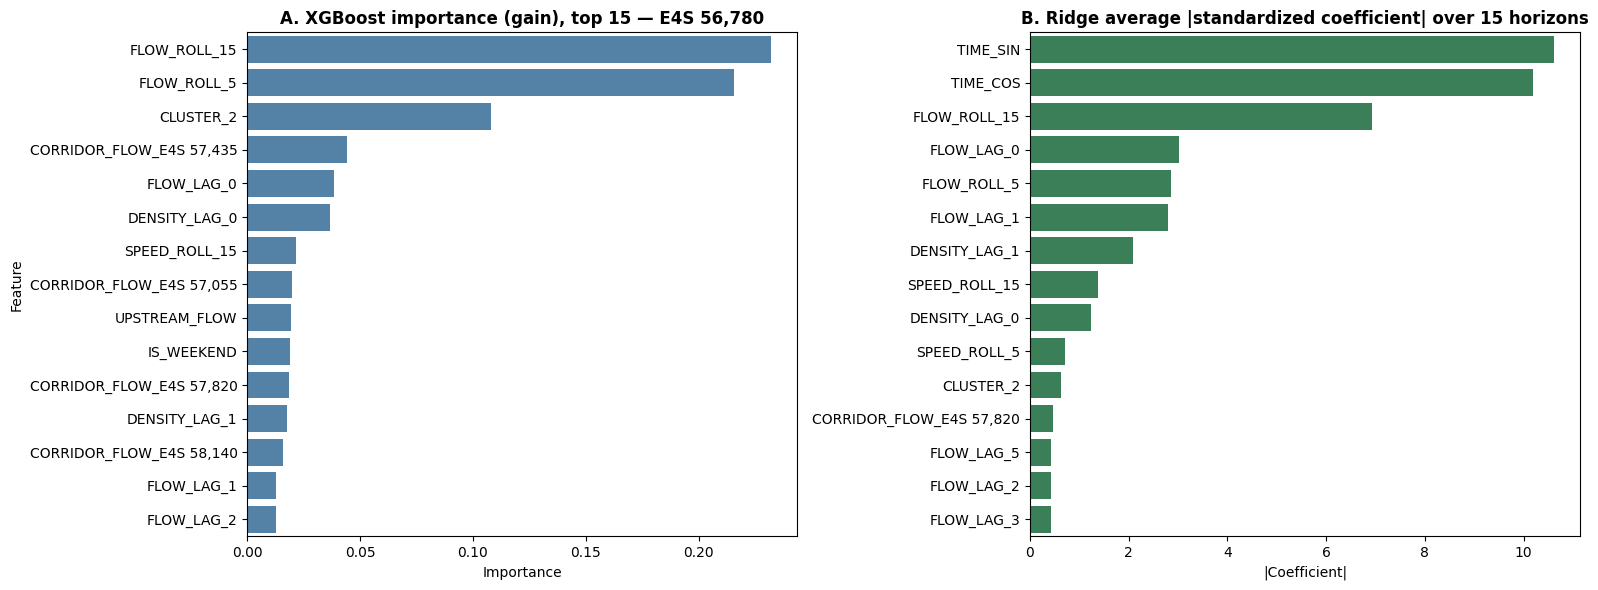

Share of total |Ridge coefficient| per feature group and horizon (H1):


,Own flow lags/rolling,Spatial,Calendar & regime
t+1,0.327,0.177,0.362
t+5,0.315,0.054,0.524
t+10,0.333,0.068,0.467
t+15,0.359,0.072,0.355


In [ ]:
FINAL = {}
for portal in TARGET_PORTALS:
    ds = DATA["train"][portal]
    all_rows = np.arange(len(ds["y1"]))
    FINAL[portal] = {"1min": fit_family(ds, all_rows, "1min"), "15min": fit_family(ds, all_rows, "15min")}
    print(f"Final models fitted on all 2021 data: {portal}")

# ---------------------------------------------------------------- feature importance
inspect_portal = BOTTLENECK_PORTAL
fam = FINAL[inspect_portal]["1min"]
feat_names = fam["feature_cols"]
imp_xgb = pd.DataFrame({"Feature": feat_names, "Importance": fam["XGBoost"].feature_importances_}) \
    .sort_values("Importance", ascending=False).head(15)
imp_ridge = pd.DataFrame({"Feature": feat_names, "|Coefficient|": np.abs(fam["Ridge"].coef_).mean(axis=0)}) \
    .sort_values("|Coefficient|", ascending=False).head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=imp_xgb, x="Importance", y="Feature", ax=ax1, color="steelblue")
ax1.set_title(f"A. XGBoost importance (gain), top 15 — {inspect_portal}", fontweight="bold")
sns.barplot(data=imp_ridge, x="|Coefficient|", y="Feature", ax=ax2, color="seagreen")
ax2.set_title("B. Ridge average |standardized coefficient| over 15 horizons", fontweight="bold")
ax2.set_ylabel("")
plt.tight_layout(); plt.show()

# Importance per horizon for Ridge: own recent flow vs. other groups (H1)
coef = np.abs(fam["Ridge"].coef_)                     # (15 horizons, n_features)
groups = {"Own flow lags/rolling": [i for i, c in enumerate(feat_names) if c.startswith("FLOW_")],
          "Spatial": [i for i, c in enumerate(feat_names) if c.startswith(("UPSTREAM", "DOWNSTREAM", "CORRIDOR", "SPATIAL"))],
          "Calendar & regime": [i for i, c in enumerate(feat_names) if c.startswith(("TIME_", "DAY_", "IS_WEEKEND", "CLUSTER_"))]}
share = pd.DataFrame({g: coef[:, idx].sum(axis=1) / coef.sum(axis=1) for g, idx in groups.items()},
                     index=[f"t+{h}" for h in range(1, HORIZON + 1)])
print("Share of total |Ridge coefficient| per feature group and horizon (H1):")
display(share.iloc[[0, 4, 9, 14]].round(3))

**Interpretation.** The XGBoost ranking shows which features drive the splits; the Ridge table shows the share of the coefficients per feature group and horizon. In our run, calendar and day-type features take the largest share (36–52%), followed by the own recent flow (32–36%); the spatial features are small except one minute ahead (18% at t+1, 5–7% later). Ridge coefficients of strongly related features (e.g. different lags) share the effect between them, so read them per group rather than per feature.

# **PART 4: FINAL EVALUATION & MODEL DIAGNOSTICS (Task D)**

All results in this part use the **final 2022 test set** (`final_evaluation_dataset.csv`) and the models fitted on 2021. Nothing in this part is used to change the models. If `evaluation_dataset.csv` contains days that are not in the final file, these are reported separately as an extra independent check.

### Helper: predicted vs. actual scatter plots

In [ ]:
MODEL_COLORS = {"Ridge": "#1f77b4", "XGBoost": "#2ca02c", "Hybrid": "#8e44ad"}

def plot_dispersion_scatters(y_true, preds_dict, title, horizon_idx=None, unit="veh/min"):
    """Predicted vs. actual for several models with the y = x line and MAE, WAPE, R, R²."""
    n = len(preds_dict)
    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 5), sharex=True, sharey=True, squeeze=False)
    if y_true.ndim > 1:
        h = 0 if horizon_idx is None else horizon_idx
        actual, tag = y_true[:, h], f"horizon t+{h + 1}"
    else:
        actual, tag = y_true.ravel(), "15-minute average"
    preds = {m: (p[:, horizon_idx or 0] if np.ndim(p) > 1 else np.ravel(p)) for m, p in preds_dict.items()}
    lo, hi = np.percentile(np.concatenate([actual] + list(preds.values())), [0.5, 99.5])
    pad = 0.05 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    for ax, (m, pred) in zip(axes[0], preds.items()):
        ax.scatter(actual, pred, s=12, alpha=0.25, color=MODEL_COLORS.get(m, "#d62728"))
        ax.plot([lo, hi], [lo, hi], "k--", lw=1.4, label="y = x")
        txt = (f"MAE : {mean_absolute_error(actual, pred):.2f} {unit}\n"
               f"WAPE: {np.abs(actual - pred).sum() / actual.sum() * 100:.1f}%\n"
               f"R   : {np.corrcoef(actual, pred)[0, 1]:.3f}\nR²  : {r2_score(actual, pred):.3f}")
        ax.text(0.04, 0.96, txt, transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="gray"))
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_title(f"{m} ({tag})", fontweight="bold"); ax.set_xlabel(f"Actual ({unit})")
        ax.grid(alpha=0.4); ax.legend(loc="lower right", fontsize=8)
    axes[0][0].set_ylabel(f"Predicted ({unit})")
    plt.suptitle(title, fontweight="bold", y=1.02)
    plt.tight_layout(); plt.show()

## 4.1 Test performance (final 2022 test set)

In [ ]:
TEST_SETS = {"Final test (final_evaluation_dataset)": DATA["test"]}
if DATA["eval_only"]:
    TEST_SETS["Extra: evaluation-only days"] = DATA["eval_only"]

TEST = {}
test_rows_1, test_rows_15, test_rows_h = [], [], []
for set_name, dsets in TEST_SETS.items():
    for portal in TARGET_PORTALS:
        ds = dsets[portal]
        if len(ds["y1"]) == 0:
            continue
        p1, p15 = run_all_predictions(FINAL[portal]["1min"], FINAL[portal]["15min"], ds)
        test_rows_1 += [{"Set": set_name, **r} for r in results_rows(ds["y1"], p1, portal)]
        test_rows_15 += [{"Set": set_name, **r} for r in results_rows(ds["y15"], p15, portal)]
        if set_name.startswith("Final"):
            TEST[portal] = {"ds": ds, "p1": p1, "p15": p15}
            test_rows_h += horizon_rows(ds["y1"], p1, portal)

df_test_1, df_test_15, df_test_h = pd.DataFrame(test_rows_1), pd.DataFrame(test_rows_15), pd.DataFrame(test_rows_h)

for set_name in TEST_SETS:
    print("\n" + "=" * 95 + f"\n{set_name.upper()} - 1-MINUTE FORECAST (t+1..t+15), average over portals\n" + "=" * 95)
    display(df_test_1[df_test_1["Set"] == set_name].groupby("Model")[METRICS].mean().sort_values("MAE").round(2))
    print("\n" + "=" * 95 + f"\n{set_name.upper()} - 15-MINUTE FLOW, average over portals\n" + "=" * 95)
    display(df_test_15[df_test_15["Set"] == set_name].groupby("Model")[METRICS].mean().sort_values("MAE").round(2))

final = "Final test (final_evaluation_dataset)"
print("\nPer portal, 1-minute forecast, MAE (veh/min):")
display(df_test_1[df_test_1["Set"] == final].pivot_table(index="Model", columns="Portal", values="MAE").round(2))
print("Per portal, 15-minute flow, MAE (veh/min):")
display(df_test_15[df_test_15["Set"] == final].pivot_table(index="Model", columns="Portal", values="MAE").round(2))

# Validation vs. test for the ML models (generalisation from 2021 to 2022)
gen = pd.concat({
    "Validation Nov-Dec 2021": df_val_1[df_val_1["Model"].isin(ML_MODELS + BASELINES)].groupby("Model")["MAE"].mean(),
    "Test 2022": df_test_1[(df_test_1["Set"] == final)].groupby("Model")["MAE"].mean(),
}, axis=1)
gen["Δ (test - val)"] = gen["Test 2022"] - gen["Validation Nov-Dec 2021"]
print("1-minute forecast MAE: 2021 validation vs. 2022 test")
display(gen.sort_values("Test 2022").round(2))


FINAL TEST (FINAL_EVALUATION_DATASET) - 1-MINUTE FORECAST (t+1..t+15), average over portals


,MAE,RMSE,MAPE (%),WAPE (%)
Model,,,,
Hybrid,7.52,9.80,19.68,14.73
XGBoost,7.54,9.83,19.69,14.75
Ridge,7.62,9.90,19.93,14.91
RNN (GRU_Compact),7.69,10.03,19.85,15.05
15-min moving avg,7.79,10.14,19.35,15.24
Persistence,10.10,13.07,24.42,19.77
Historical profile,10.29,13.45,32.51,20.15



FINAL TEST (FINAL_EVALUATION_DATASET) - 15-MINUTE FLOW, average over portals


,MAE,RMSE,MAPE (%),WAPE (%)
Model,,,,
Hybrid | M2 native,3.08,4.25,6.73,6.03
XGBoost | M2 native,3.10,4.29,6.76,6.06
XGBoost | M1 post-hoc,3.11,4.33,6.77,6.09
Hybrid | M1 post-hoc,3.11,4.30,6.78,6.09
Ridge | M2 native,3.31,4.50,7.24,6.47
Ridge | M1 post-hoc,3.31,4.50,7.24,6.47
RNN (GRU_Compact) | M1 post-hoc,3.35,4.73,7.19,6.55
RNN (GRU_Compact) | M2 native,3.36,4.71,7.23,6.57
15-min moving avg,3.73,4.98,7.97,7.29



EXTRA: EVALUATION-ONLY DAYS - 1-MINUTE FORECAST (t+1..t+15), average over portals


...

Portal,"E4S 56,490","E4S 56,780","E4S 57,055"
Model,,,
15-min moving avg,7.91,8.10,7.34
Historical profile,10.47,10.92,9.48
Hybrid,7.72,7.91,6.94
Persistence,10.32,10.57,9.41
RNN (GRU_Compact),7.93,8.07,7.07
Ridge,7.80,7.99,7.07
XGBoost,7.73,7.95,6.93


Per portal, 15-minute flow, MAE (veh/min):


Portal,"E4S 56,490","E4S 56,780","E4S 57,055"
Model,,,
15-min moving avg,3.73,3.80,3.64
Historical profile,7.57,7.60,6.42
Hybrid | M1 post-hoc,3.24,3.27,2.83
Hybrid | M2 native,3.19,3.25,2.81
Persistence,7.65,7.85,6.96
RNN (GRU_Compact) | M1 post-hoc,3.49,3.54,3.02
RNN (GRU_Compact) | M2 native,3.47,3.58,3.02
Ridge | M1 post-hoc,3.39,3.48,3.05
Ridge | M2 native,3.39,3.48,3.05


1-minute forecast MAE: 2021 validation vs. 2022 test


,Validation Nov-Dec 2021,Test 2022,Δ (test - val)
Model,,,
Hybrid,7.78,7.52,-0.26
XGBoost,8.17,7.54,-0.63
Ridge,7.87,7.62,-0.26
RNN (GRU_Compact),8.83,7.69,-1.14
15-min moving avg,7.70,7.79,0.08
Persistence,9.65,10.10,0.45
Historical profile,13.22,10.29,-2.93


**Notes for interpretation.**
* The validation models were trained on Jun–Oct only, while the test models use all of 2021, and the periods differ (Nov–Dec 2021 includes the Christmas holidays, 2022 includes winter and spring). A difference between validation and test therefore reflects **both** seasonality and the extra training data. It is *not* a leakage test.
* All ML models perform better on both 2022 test sets than on the 2021 validation months, and the gap to the "last 15 minutes" baseline is much larger in 2022 (about 16% for the 15-minute flow) than in Nov–Dec 2021 (under 1%). The final models were trained on more data, including Nov–Dec, and January–June is more regular than the Christmas period.
* If the best model chosen on validation (printed in 3.7) is also best on test, the selection generalizes. If not, report it honestly; differences of a few hundredths of a veh/min are not meaningful.

## 4.2 Error vs. forecast horizon and the noise floor (H1, H5)
If vehicle arrivals within a minute were Poisson-distributed with an average of $\lambda$ vehicles per minute, even a *perfect* predictor of the expected flow would have an MAE of about $\sqrt{2\lambda/\pi}$ per minute (normal approximation). For the 15-minute mean the floor shrinks to about $\sqrt{2\lambda/(15\pi)}$. Comparing the model errors with this floor shows how much of the remaining error is reducible.

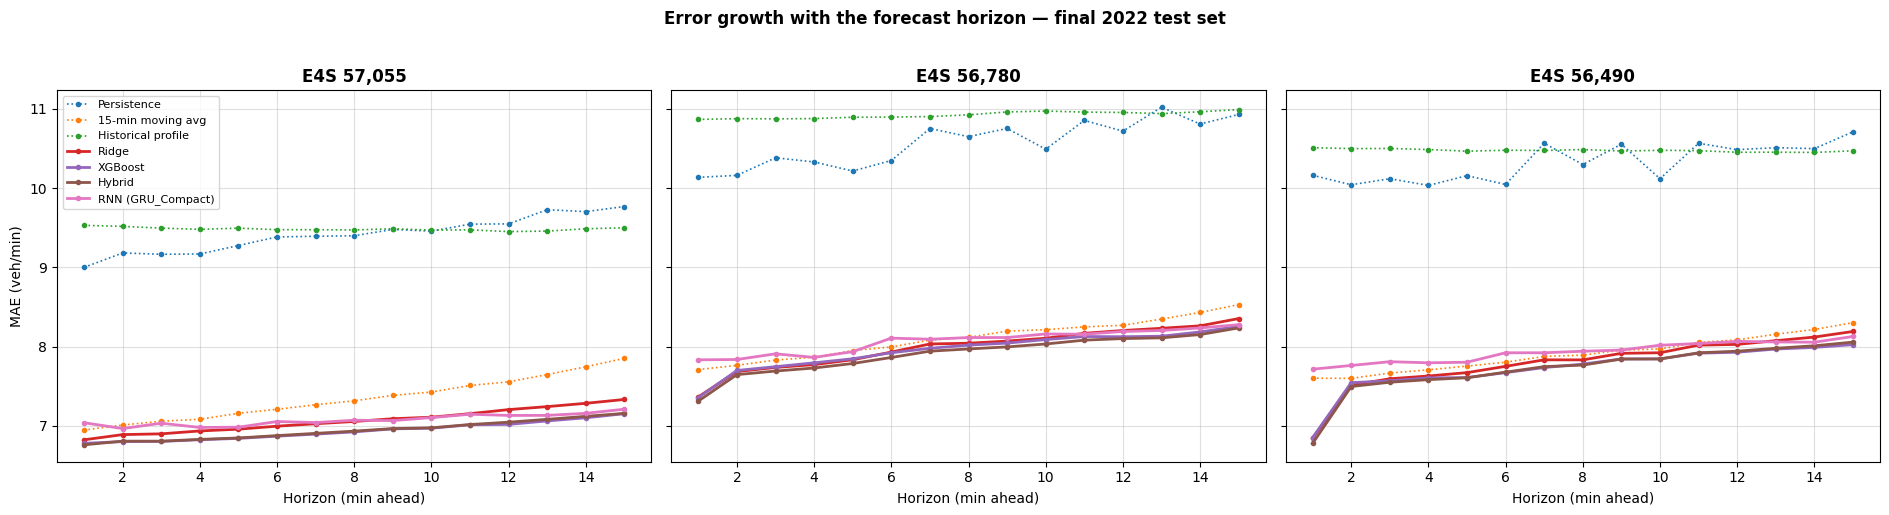

,Average flow (veh/min),Poisson floor 1-min MAE,Best model 1-min MAE,Poisson floor 15-min MAE,Best model 15-min MAE
Portal,,,,,
"E4S 57,055",50.090000,5.58,6.93,1.44,2.81
"E4S 56,780",50.259998,5.59,7.91,1.44,3.25
"E4S 56,490",52.939999,5.74,7.72,1.48,3.17


In [ ]:
fig, axes = plt.subplots(1, len(TARGET_PORTALS), figsize=(19, 5), sharey=True)
show = BASELINES + ML_MODELS
for ax, portal in zip(axes, TARGET_PORTALS):
    d = df_test_h[df_test_h["Portal"] == portal]
    for m in show:
        dm = d[d["Model"] == m]
        ax.plot(dm["Horizon"], dm["MAE"], marker="o", ms=3, lw=2 if m in ML_MODELS else 1.2,
                ls="-" if m in ML_MODELS else ":", label=m)
    ax.set_title(portal, fontweight="bold"); ax.set_xlabel("Horizon (min ahead)"); ax.grid(alpha=0.4)
axes[0].set_ylabel("MAE (veh/min)"); axes[0].legend(fontsize=8)
plt.suptitle("Error growth with the forecast horizon — final 2022 test set", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

floor_rows = []
for portal in TARGET_PORTALS:
    ds = TEST[portal]["ds"]
    lam = np.clip(ds["y1"].mean(axis=1), 0, None)
    floor_1 = np.mean(np.sqrt(2 * lam / np.pi))
    floor_15 = np.mean(np.sqrt(2 * lam / (15 * np.pi)))
    best_1 = df_test_1[(df_test_1["Set"] == final) & (df_test_1["Portal"] == portal) & df_test_1["Model"].isin(ML_MODELS)]["MAE"].min()
    best_15 = df_test_15[(df_test_15["Set"] == final) & (df_test_15["Portal"] == portal) & df_test_15["Model"].str.contains(r"\| M")]["MAE"].min()
    floor_rows.append({"Portal": portal, "Average flow (veh/min)": lam.mean(),
                       "Poisson floor 1-min MAE": floor_1, "Best model 1-min MAE": best_1,
                       "Poisson floor 15-min MAE": floor_15, "Best model 15-min MAE": best_15})
display(pd.DataFrame(floor_rows).set_index("Portal").round(2))

**Interpretation.**
* **H1:** the MAE grows with the horizon for every model. The persistence baseline degrades fastest, and the ML models keep their advantage most clearly at the longer horizons.
* **H5:** at one-minute resolution the best model (about 7–8 veh/min) is close to the Poisson floor (about 5.6 veh/min), so most of the remaining error is random arrival noise that no model can predict. At the 15-minute level the error is about 2.4 times smaller in relative (WAPE) terms. It is still about twice the 15-minute floor, so after averaging a predictable part of the error remains; this is where the models add value. The forecast is informative mainly at the aggregated level, which also matches operational use (see Part 5). The Poisson assumption is an approximation: real counts can be under- or over-dispersed.

## 4.2b One-minute vs. 15-minute forecasts: same models, two resolutions
This is the key comparison for the report. Trafikverket's benchmark asks for the flow over the **next 15 minutes** because one-minute counts fluctuate strongly: drivers arrive at the detector more or less randomly, so the number of vehicles in a single minute varies a lot even when the traffic state is stable. Aggregating over 15 minutes averages these random fluctuations out.

The figure shows, for every model:
* **A.** the relative error (WAPE) of the 1-minute forecasts and of the 15-minute flow, together with the **Poisson noise floor** at both resolutions: the error a *perfect* model would still have if arrivals were random;
* **B.** how much each ML model improves on the best baseline at each resolution.

1-minute vs. 15-minute performance — final test, average over the target portals


,MAE 1-min,MAE 15-min (M2),WAPE 1-min (%),WAPE 15-min M1 (%),WAPE 15-min M2 (%),Error reduction 1 -> 15 min (x),Gain vs best baseline 1-min (%),Gain vs best baseline 15-min (%)
Model,,,,,,,,
Persistence,10.10,7.49,19.77,14.66,14.66,1.35,-29.75,-101.02
15-min moving avg,7.79,3.73,15.24,7.29,7.29,2.09,0.00,0.00
Historical profile,10.29,7.20,20.15,14.08,14.08,1.43,-32.22,-93.23
Ridge,7.62,3.31,14.91,6.47,6.47,2.30,2.17,11.21
XGBoost,7.54,3.10,14.75,6.09,6.06,2.43,3.18,16.83
Hybrid,7.52,3.08,14.73,6.09,6.03,2.44,3.36,17.23
RNN (GRU_Compact),7.69,3.36,15.05,6.55,6.57,2.29,1.20,9.89


Poisson noise floor (WAPE): 11.0% at 1 min, 2.8% at 15 min


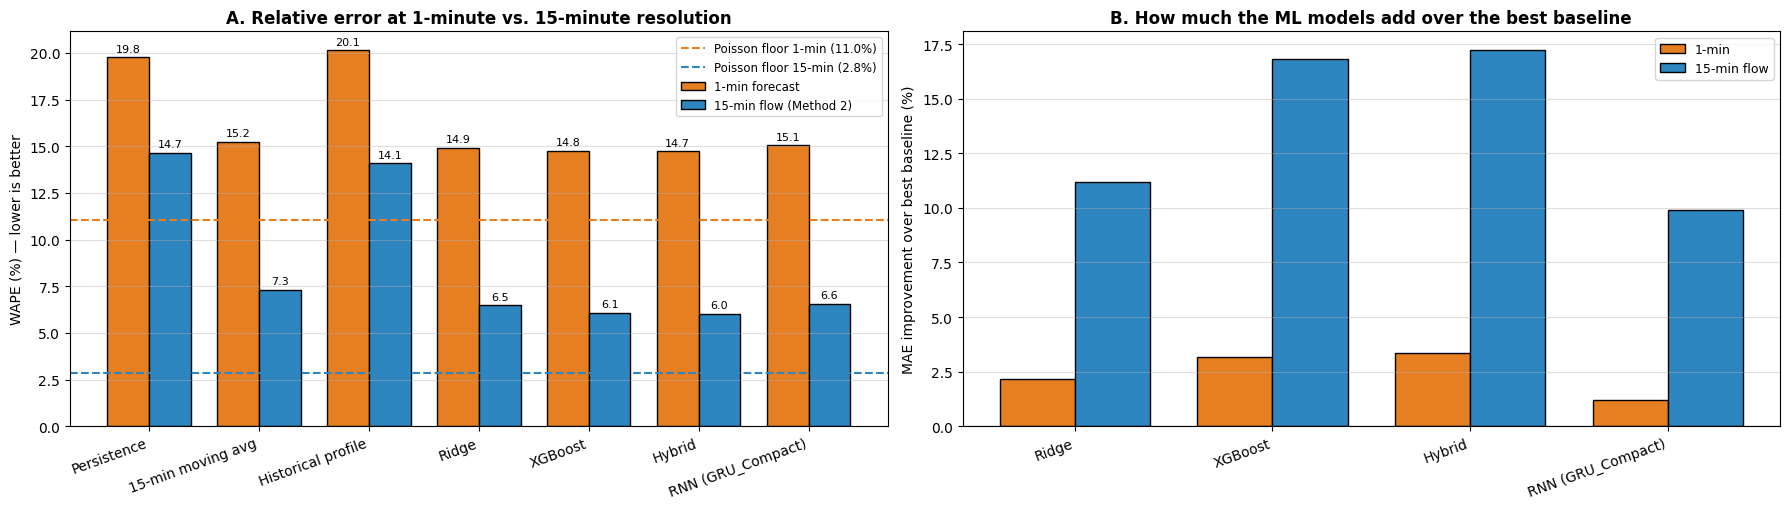

In [ ]:
# ==============================================================================
# 4.2b  1-MINUTE vs 15-MINUTE: SAME MODELS, TWO RESOLUTIONS (final 2022 test)
# ==============================================================================
# WAPE (relative error) is used because MAE values at the two resolutions are on
# different scales of variability. The dashed lines show the Poisson noise floor:
# the error even a perfect model would have if vehicles arrive randomly.
# ==============================================================================
lt1 = df_test_1[df_test_1["Set"] == final]
lt15 = df_test_15[df_test_15["Set"] == final]

def mean_metric(df, model, metric):
    return df.loc[df["Model"] == model, metric].mean()

res_rows = []
for m in BASELINES + ML_MODELS:
    m1 = m if m in BASELINES else f"{m} | M1 post-hoc"
    m2 = m if m in BASELINES else f"{m} | M2 native"
    res_rows.append({
        "Model": m,
        "MAE 1-min": mean_metric(lt1, m, "MAE"),
        "MAE 15-min (M2)": mean_metric(lt15, m2, "MAE"),
        "WAPE 1-min (%)": mean_metric(lt1, m, "WAPE (%)"),
        "WAPE 15-min M1 (%)": mean_metric(lt15, m1, "WAPE (%)"),
        "WAPE 15-min M2 (%)": mean_metric(lt15, m2, "WAPE (%)"),
    })
df_res = pd.DataFrame(res_rows).set_index("Model")
df_res["Error reduction 1 -> 15 min (x)"] = df_res["WAPE 1-min (%)"] / df_res["WAPE 15-min M2 (%)"]

# Improvement of each ML model over the best baseline, at each resolution
best_b1 = df_res.loc[BASELINES, "MAE 1-min"].min()
best_b15 = df_res.loc[BASELINES, "MAE 15-min (M2)"].min()
df_res["Gain vs best baseline 1-min (%)"] = (1 - df_res["MAE 1-min"] / best_b1) * 100
df_res["Gain vs best baseline 15-min (%)"] = (1 - df_res["MAE 15-min (M2)"] / best_b15) * 100

# Poisson noise floor expressed as WAPE (floor MAE / average flow), averaged over portals
df_floor = pd.DataFrame(floor_rows)
floor_wape_1 = (df_floor["Poisson floor 1-min MAE"] / df_floor["Average flow (veh/min)"]).mean() * 100
floor_wape_15 = (df_floor["Poisson floor 15-min MAE"] / df_floor["Average flow (veh/min)"]).mean() * 100

print("1-minute vs. 15-minute performance — final test, average over the target portals")
display(df_res.round(2))
print(f"Poisson noise floor (WAPE): {floor_wape_1:.1f}% at 1 min, {floor_wape_15:.1f}% at 15 min")

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2))
x = np.arange(len(df_res))
w = 0.38
ax = axes[0]
ax.bar(x - w / 2, df_res["WAPE 1-min (%)"], w, label="1-min forecast", color="#e67e22", edgecolor="black")
ax.bar(x + w / 2, df_res["WAPE 15-min M2 (%)"], w, label="15-min flow (Method 2)", color="#2e86c1", edgecolor="black")
ax.axhline(floor_wape_1, color="#e67e22", ls="--", lw=1.5, label=f"Poisson floor 1-min ({floor_wape_1:.1f}%)")
ax.axhline(floor_wape_15, color="#2e86c1", ls="--", lw=1.5, label=f"Poisson floor 15-min ({floor_wape_15:.1f}%)")
for i, (a, b) in enumerate(zip(df_res["WAPE 1-min (%)"], df_res["WAPE 15-min M2 (%)"])):
    ax.text(i - w / 2, a + 0.3, f"{a:.1f}", ha="center", fontsize=8)
    ax.text(i + w / 2, b + 0.3, f"{b:.1f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(df_res.index, rotation=20, ha="right")
ax.set_ylabel("WAPE (%) — lower is better")
ax.set_title("A. Relative error at 1-minute vs. 15-minute resolution", fontweight="bold")
ax.legend(fontsize=8.5); ax.grid(axis="y", alpha=0.4)

ax = axes[1]
ml = df_res.loc[ML_MODELS]
xm = np.arange(len(ml))
ax.bar(xm - w / 2, ml["Gain vs best baseline 1-min (%)"], w, label="1-min", color="#e67e22", edgecolor="black")
ax.bar(xm + w / 2, ml["Gain vs best baseline 15-min (%)"], w, label="15-min flow", color="#2e86c1", edgecolor="black")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xm); ax.set_xticklabels(ml.index, rotation=20, ha="right")
ax.set_ylabel("MAE improvement over best baseline (%)")
ax.set_title("B. How much the ML models add over the best baseline", fontweight="bold")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.4)
plt.tight_layout(); plt.show()


**How to read it (write this up in the report).**
* **Why the models "fail" at 1 minute:** the 1-minute WAPE of the best models lies close to the 1-minute noise floor. Most of the remaining error is therefore random arrival noise that no point-forecast model can predict. The models do learn the *expected* flow; they cannot know whether 9 or 14 vehicles will happen to pass in a particular minute.
* **What aggregation does:** the same models reach a much lower relative error on the 15-minute flow (the reduction factor is in the table). The noise floor shrinks roughly with $1/\sqrt{W}$ for a window of $W$ minutes, so at 15 minutes the signal dominates.
* **Added value of ML (panel B):** at 1 minute the ML models are only slightly better than the best baseline; at 15 minutes the gain is larger, because there is less noise hiding the patterns the models learn.
* **Could any model handle 1-minute data?** Not as a single-number forecast: the best possible point forecast of a random count is its expected value, which the models already approximate. A model can only "handle" it by forecasting the **distribution** of the count (expected value plus spread), e.g. a Poisson or negative-binomial model, or prediction intervals. For that it needs to know the arrival process: the expected arrival rate and how much counts vary around it (dispersion). Detector data with individual vehicle passages or headways would allow this to be modelled directly; MCS only provides counts per minute.
* **Speed** is much less affected, because the average speed in a minute is similar whether 4 or 20 vehicles pass (optional comparison in Part 6).

## 4.2c Aggregation-window sweep (H5)
How does the predictability change as the window grows? The 15-minute horizon $t+1 \dots t+15$ is split into blocks of $W$ = 1, 3, 5 and 15 minutes, and forecasts and observations are averaged within each block. All windows cover the **same** 15-minute horizon, so only the aggregation changes ($W = 1$ is the 1-minute forecast, $W = 15$ is the 15-minute flow). The 1-minute forecasts of the final models are aggregated (Method 1); Section 3.7 showed this is as accurate as a dedicated model, so no new training is needed. The black dashed line is the Poisson noise floor for each window.

MAE (veh/min) by aggregation window — final test, average over portals


Window (min),1,3,5,15
Model,,,,
Poisson noise floor,5.64,3.25,2.52,1.46
Persistence,10.10,8.40,7.98,7.49
15-min moving avg,7.79,5.34,4.63,3.73
Historical profile,10.29,8.36,7.86,7.20
Ridge,7.62,5.05,4.30,3.31
XGBoost,7.54,4.93,4.15,3.11
Hybrid,7.52,4.92,4.14,3.11
RNN (GRU_Compact),7.69,5.12,4.37,3.35


WAPE (%) by aggregation window


Window (min),1,3,5,15
Model,,,,
Poisson noise floor,11.03,6.37,4.93,2.85
Persistence,19.77,16.44,15.61,14.66
15-min moving avg,15.24,10.46,9.07,7.29
Historical profile,20.15,16.37,15.38,14.08
Ridge,14.91,9.89,8.41,6.47
XGBoost,14.75,9.65,8.11,6.09
Hybrid,14.73,9.64,8.10,6.09
RNN (GRU_Compact),15.05,10.02,8.55,6.55


MAE improvement of the ML models over the best baseline (%) per window


Window (min),1,3,5,15
Model,,,,
Ridge,2.2,5.4,7.2,11.2
XGBoost,3.2,7.7,10.5,16.4
Hybrid,3.4,7.8,10.6,16.4
RNN (GRU_Compact),1.2,4.1,5.7,10.1


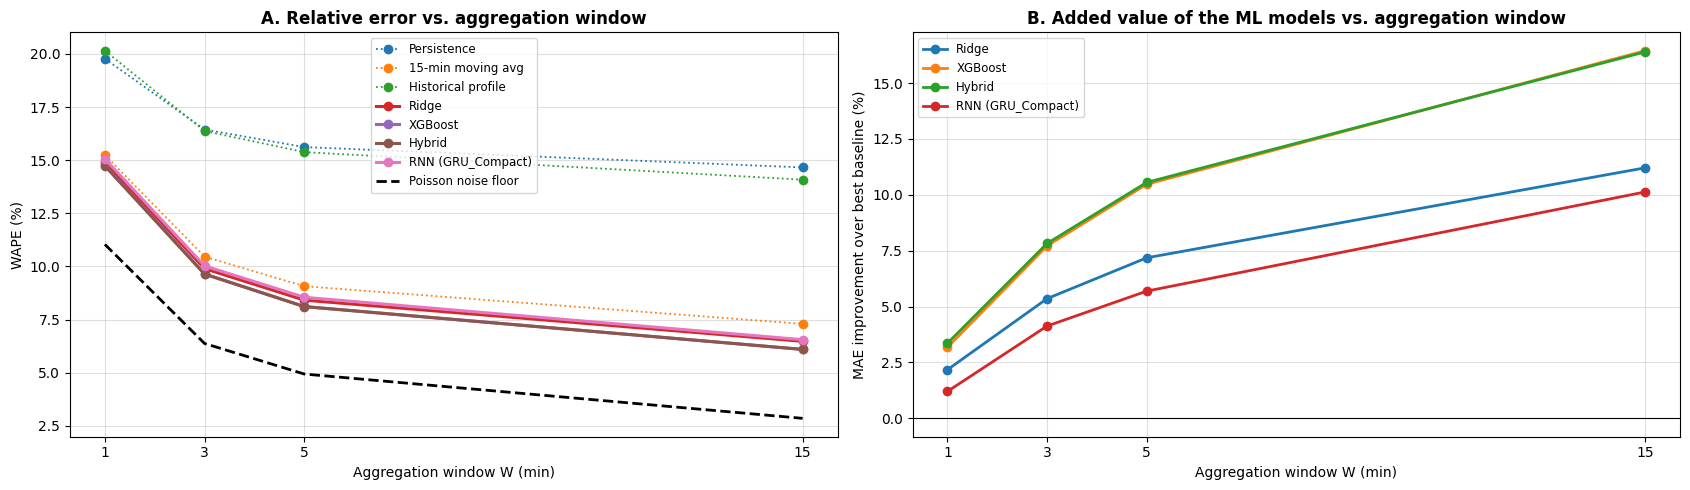

In [ ]:
# ==============================================================================
# 4.2c  AGGREGATION-WINDOW SWEEP (H5): HOW PREDICTABLE IS THE NEXT W MINUTES?
# ==============================================================================
# The 15-minute horizon (t+1 ... t+15) is cut into blocks of W minutes and the
# forecast and the observation are averaged within each block:
#   W = 1  -> 15 blocks of 1 min  (= 1-minute forecast)
#   W = 3  ->  5 blocks of 3 min
#   W = 5  ->  3 blocks of 5 min
#   W = 15 ->  1 block of 15 min  (= 15-minute flow, Method 1)
# All windows cover the same 15-minute horizon, so only the aggregation changes.
# No new models are trained: the 1-minute forecasts of the final models are
# aggregated (Method 1), which the validation showed is as good as a native model.
# ==============================================================================
WINDOWS = [w for w in [1, 3, 5, 15] if HORIZON % w == 0]

def to_blocks(a, W):
    a = np.asarray(a, dtype=float)
    return a.reshape(len(a), HORIZON // W, W).mean(axis=2)

sweep_rows = []
for portal in TARGET_PORTALS:
    ds, p1 = TEST[portal]["ds"], TEST[portal]["p1"]
    lam = np.clip(ds["y1"].mean(axis=1), 0, None)            # expected flow per minute
    for W in WINDOWS:
        yb = to_blocks(ds["y1"], W)
        for m in BASELINES + ML_MODELS:
            sweep_rows.append({"Portal": portal, "Window (min)": W, "Model": m,
                               **metric_row(yb, to_blocks(p1[m], W))})
        floor_mae = np.sqrt(2 * lam / (np.pi * W)).mean()
        sweep_rows.append({"Portal": portal, "Window (min)": W, "Model": "Poisson noise floor",
                           "MAE": floor_mae, "WAPE (%)": floor_mae / ds["y1"].mean() * 100})

df_sweep = pd.DataFrame(sweep_rows)
sweep_mae = df_sweep.pivot_table(index="Model", columns="Window (min)", values="MAE")
sweep_wape = df_sweep.pivot_table(index="Model", columns="Window (min)", values="WAPE (%)")
order = ["Poisson noise floor"] + BASELINES + ML_MODELS
print("MAE (veh/min) by aggregation window — final test, average over portals")
display(sweep_mae.reindex(order).round(2))
print("WAPE (%) by aggregation window")
display(sweep_wape.reindex(order).round(2))

best_base_w = sweep_mae.loc[BASELINES].min()
gain_w = (1 - sweep_mae.loc[ML_MODELS] / best_base_w) * 100
print("MAE improvement of the ML models over the best baseline (%) per window")
display(gain_w.round(1))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
ax = axes[0]
for m in BASELINES + ML_MODELS:
    ax.plot(WINDOWS, sweep_wape.loc[m, WINDOWS], marker="o",
            ls=":" if m in BASELINES else "-", lw=1.3 if m in BASELINES else 2.2, label=m)
ax.plot(WINDOWS, sweep_wape.loc["Poisson noise floor", WINDOWS], "k--", lw=2, label="Poisson noise floor")
ax.set_xticks(WINDOWS); ax.set_xlabel("Aggregation window W (min)")
ax.set_ylabel("WAPE (%)"); ax.grid(alpha=0.4); ax.legend(fontsize=8.5)
ax.set_title("A. Relative error vs. aggregation window", fontweight="bold")

ax = axes[1]
for m in ML_MODELS:
    ax.plot(WINDOWS, gain_w.loc[m, WINDOWS], marker="o", lw=2, label=m)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(WINDOWS); ax.set_xlabel("Aggregation window W (min)")
ax.set_ylabel("MAE improvement over best baseline (%)"); ax.grid(alpha=0.4); ax.legend(fontsize=8.5)
ax.set_title("B. Added value of the ML models vs. aggregation window", fontweight="bold")
plt.tight_layout(); plt.show()


**Interpretation.** The error falls steeply between 1 and 5 minutes and then more slowly, following the noise floor ($\propto 1/\sqrt{W}$). The gap between the models and the floor is the part of the error that is in principle reducible. Panel B shows from which window onward the ML models add clear value over the baselines. Together, these curves justify Trafikverket's choice of a 15-minute target and answer the revised research question about the aggregation window.

## 4.3 Example day: forecasts during the peak

Representative test weekday (median peak flow): 20220422 (Friday)
Model shown in row 3   : Hybrid (Ridge + XGBoost), averaged 1-min forecasts
Baseline used in boxes : 15-min moving avg (last 15 min)


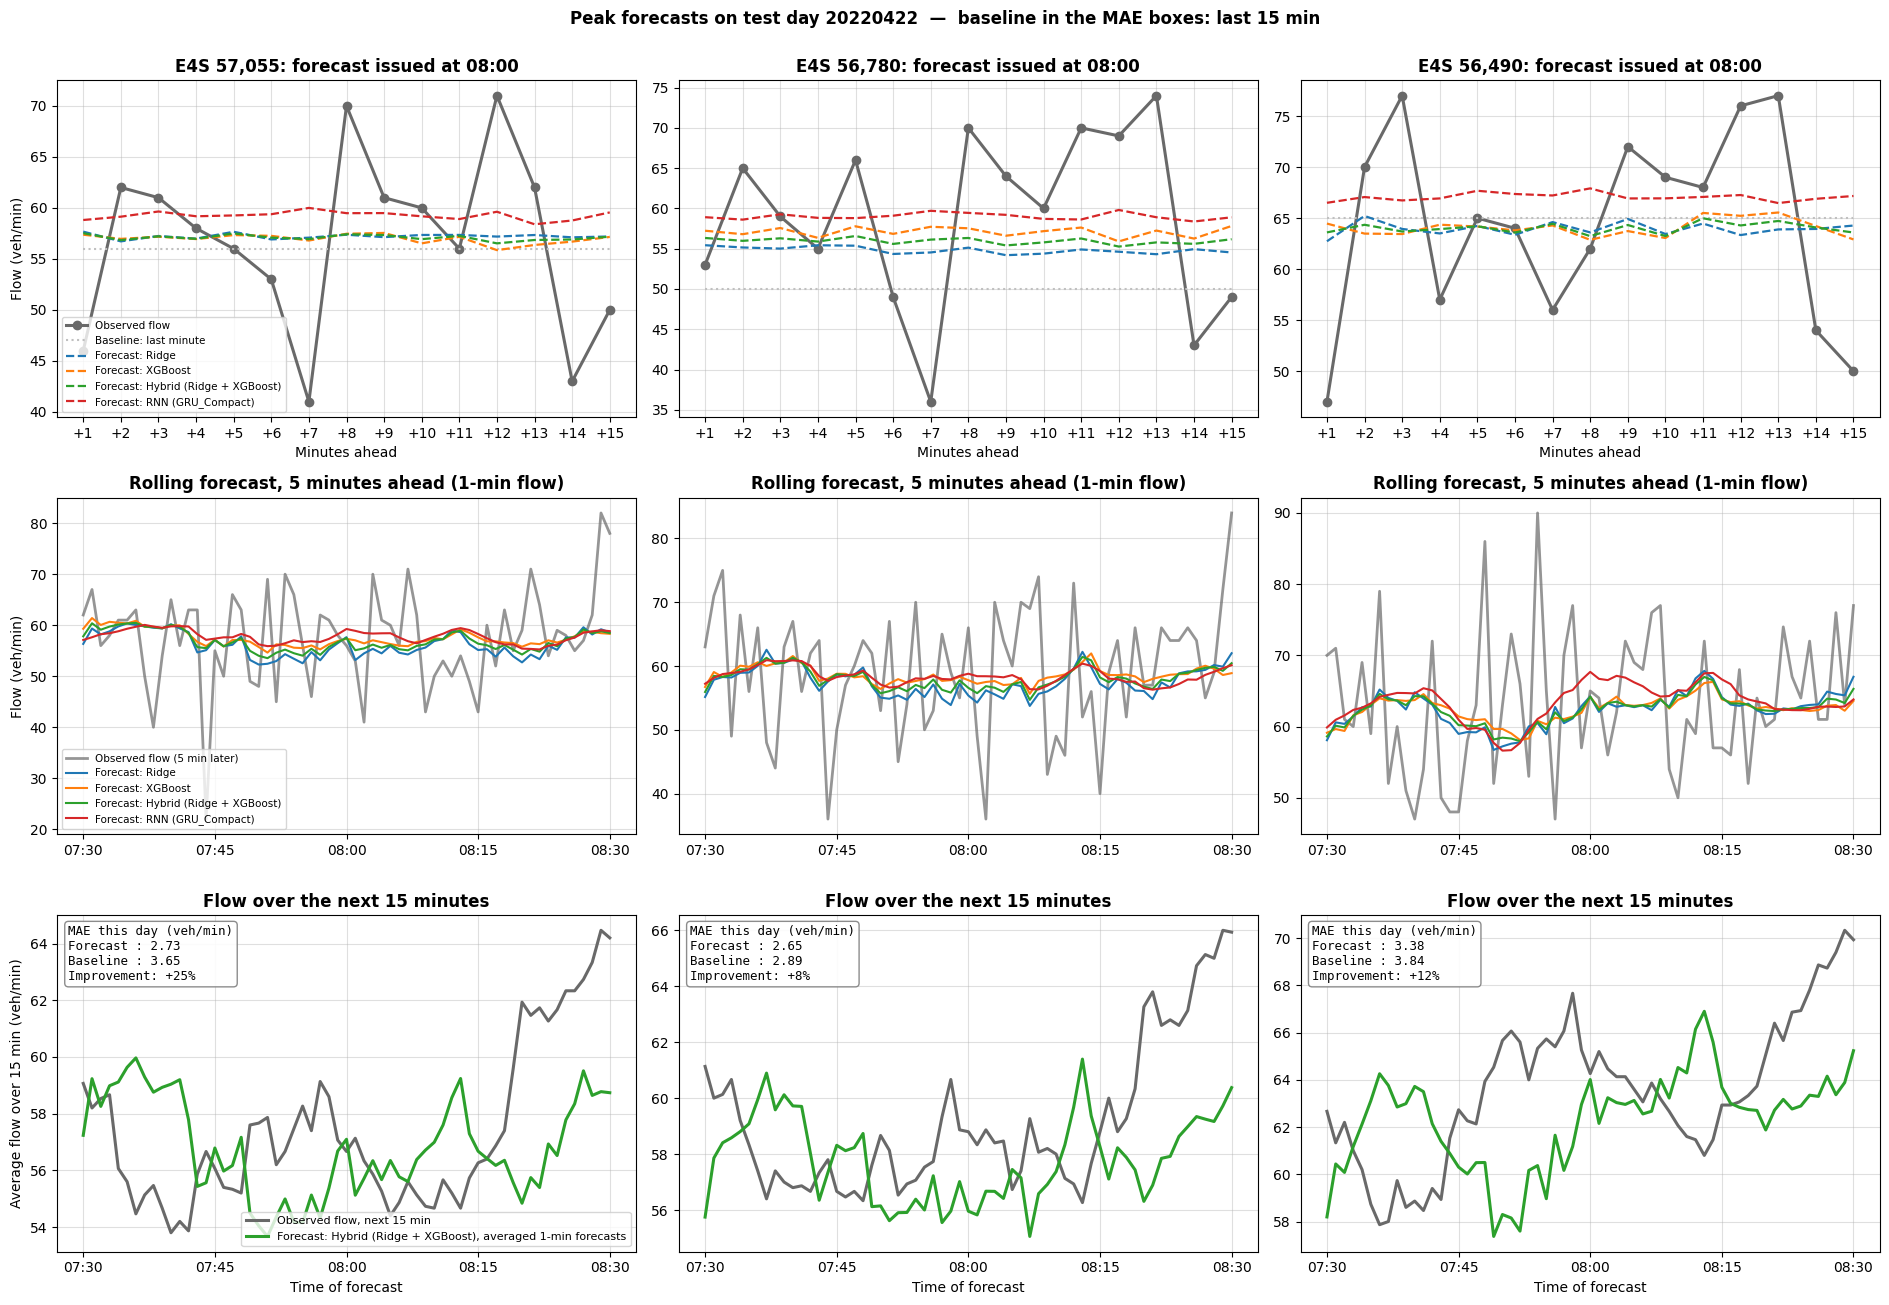

In [ ]:
# ==============================================================================
# 4.3  EXAMPLE DAY: FORECASTS DURING THE PEAK
# ==============================================================================
# Row 1: one forecast issued at 08:00 for the next 15 one-minute flows
# Row 2: rolling 1-minute forecasts, lead t+5
# Row 3: 15-minute flow — observed vs. best model only (baseline removed for
#        readability); the box gives that day's MAE of the model and of the
#        best 15-min baseline, so the comparison is still visible.
# ==============================================================================
meta_b = TEST[BOTTLENECK_PORTAL]["ds"]["meta"]
weekday_meta = meta_b[meta_b["DateTime"].dt.dayofweek < 5]
day_means = weekday_meta.groupby("Date_Str")["FLOW"].mean()
rep_date = (day_means - day_means.median()).abs().idxmin()     # a "typical" weekday
print(f"Representative test weekday (median peak flow): {rep_date} "
      f"({pd.to_datetime(rep_date, format='%Y%m%d').day_name()})")

# Best 15-min baseline over the WHOLE final test (fixed choice, not picked per day)
lt15 = df_test_15[(df_test_15["Set"] == final) & df_test_15["Model"].isin(BASELINES)]
BEST_BASE_15 = lt15.groupby("Model")["MAE"].mean().idxmin()


def pretty_name(key):
    """'Hybrid | M1 post-hoc' -> 'Hybrid (Ridge + XGBoost), averaged 1-min forecasts'."""
    model, _, method = key.partition(" | ")
    model = {"Hybrid": "Hybrid (Ridge + XGBoost)"}.get(model, model)
    method = {"M1 post-hoc": "averaged 1-min forecasts", "M2 native": "15-min model"}.get(method, method)
    return f"{model}, {method}" if method else model


BASELINE_LABELS = {
    "Persistence": "last minute",
    "15-min moving avg": "last 15 min",
    "Historical profile": "typical flow for this time and day type",
}
print(f"Model shown in row 3   : {pretty_name(BEST_15)}")
print(f"Baseline used in boxes : {BEST_BASE_15} ({BASELINE_LABELS.get(BEST_BASE_15, '')})")

fig, axes = plt.subplots(3, len(TARGET_PORTALS), figsize=(19, 13))
for j, portal in enumerate(TARGET_PORTALS):
    ds, p1, p15 = TEST[portal]["ds"], TEST[portal]["p1"], TEST[portal]["p15"]
    day = (ds["meta"]["Date_Str"] == rep_date).to_numpy()
    times = ds["meta"].loc[day, "TimeOnly"].to_numpy()

    # ---------------- Row 1: one multi-step forecast issued at 08:00
    ax = axes[0, j]
    i08 = np.where(day & (ds["meta"]["TimeOnly"] == "08:00").to_numpy())[0]
    if len(i08):
        i = i08[0]
        steps = [f"+{h}" for h in range(1, HORIZON + 1)]
        ax.plot(steps, ds["y1"][i], "o-", color="dimgray", lw=2.2, label="Observed flow")
        ax.plot(steps, p1["Persistence"][i], ":", color="silver", label="Baseline: last minute")
        for m in ML_MODELS:
            ax.plot(steps, p1[m][i], "--", lw=1.6, label=f"Forecast: {pretty_name(m)}")
    ax.set_title(f"{portal}: forecast issued at 08:00", fontweight="bold")
    ax.set_xlabel("Minutes ahead"); ax.grid(alpha=0.4)

    # ---------------- Row 2: rolling 1-minute forecasts, lead t+5
    ax = axes[1, j]
    ax.plot(times, ds["y1"][day, 4], color="dimgray", lw=2, alpha=0.7, label="Observed flow (5 min later)")
    for m in ML_MODELS:
        ax.plot(times, p1[m][day, 4], lw=1.5, label=f"Forecast: {pretty_name(m)}")
    ax.set_title("Rolling forecast, 5 minutes ahead (1-min flow)", fontweight="bold")
    ax.set_xticks(range(0, len(times), 15)); ax.grid(alpha=0.4)

    # ---------------- Row 3: 15-minute flow, observed vs. forecast + MAE box
    ax = axes[2, j]
    y_obs = ds["y15"][day]
    y_mod = np.asarray(p15[BEST_15])[day]
    y_base = np.asarray(p15[BEST_BASE_15])[day]
    ax.plot(times, y_obs, color="dimgray", lw=2.2, label="Observed flow, next 15 min")
    ax.plot(times, y_mod, color="#2ca02c", lw=2.2, label=f"Forecast: {pretty_name(BEST_15)}")

    mae_mod = mean_absolute_error(y_obs, y_mod)
    mae_base = mean_absolute_error(y_obs, y_base)
    gain = (1 - mae_mod / mae_base) * 100
    ax.text(0.02, 0.97,
            f"MAE this day (veh/min)\n"
            f"Forecast : {mae_mod:.2f}\n"
            f"Baseline : {mae_base:.2f}\n"
            f"Improvement: {gain:+.0f}%",
            transform=ax.transAxes, va="top", fontsize=9, family="monospace",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="gray"))
    ax.set_title("Flow over the next 15 minutes", fontweight="bold")
    ax.set_xlabel("Time of forecast"); ax.set_xticks(range(0, len(times), 15)); ax.grid(alpha=0.4)

axes[0, 0].set_ylabel("Flow (veh/min)")
axes[1, 0].set_ylabel("Flow (veh/min)")
axes[2, 0].set_ylabel("Average flow over 15 min (veh/min)")
axes[0, 0].legend(fontsize=7.5, loc="lower left")
axes[1, 0].legend(fontsize=7.5, loc="lower left")
axes[2, 0].legend(fontsize=8, loc="lower right")
plt.suptitle(f"Peak forecasts on test day {rep_date}  —  baseline in the MAE boxes: "
             f"{BASELINE_LABELS.get(BEST_BASE_15, BEST_BASE_15)}", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

The one-minute forecasts change only slowly, while the observed one-minute flow jumps up and down from minute to minute. The models predict the expected flow; the random minute-to-minute jumps, caused by how vehicles happen to arrive at the detector, cannot be predicted (H5). For the 15-minute flow, the observed values change much more gradually and the forecast follows their general level, but it reacts to changes with some delay; on this day it underestimated the rise in flow after 08:15. The box in each bottom panel compares the forecast with the best simple baseline on this day; the comparison over all test days is given in Section 4.2b.

## 4.4 Predicted vs. actual (bottleneck)

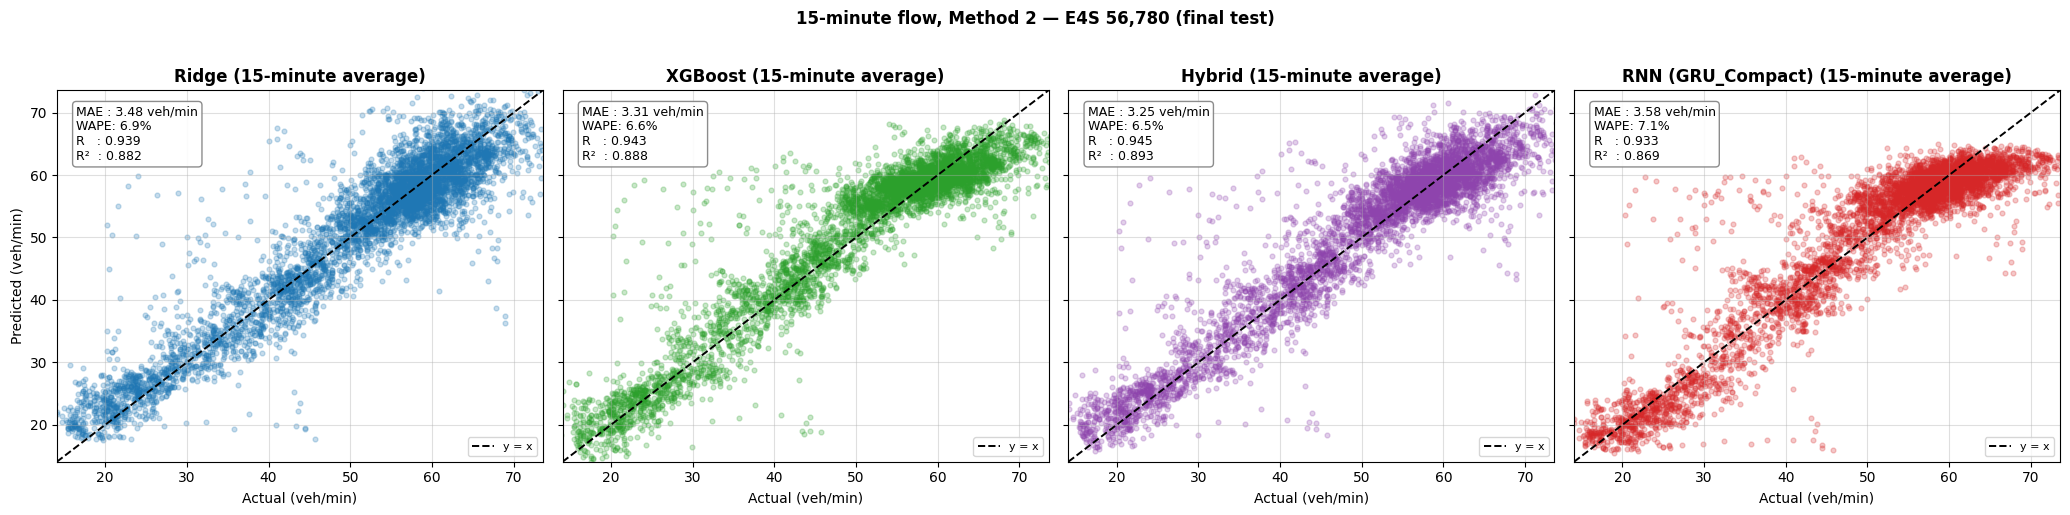

In [ ]:
t_b = TEST[BOTTLENECK_PORTAL]
# plot_dispersion_scatters(t_b["ds"]["y1"], {m: t_b["p1"][m] for m in ML_MODELS},
#                          f"1-minute forecast at t+5 — {BOTTLENECK_PORTAL} (final test)", horizon_idx=4)
plot_dispersion_scatters(t_b["ds"]["y15"], {m: t_b["p15"][f"{m} | M2 native"] for m in ML_MODELS},
                         f"15-minute flow, Method 2 — {BOTTLENECK_PORTAL} (final test)")

**Interpretation.** All models reproduce the 15-minute flow well (WAPE 6.5–7.1% at the bottleneck), with the Hybrid model performing best. The high R² values are partly due to the clear separation between weekend and weekday traffic levels; within the weekday peak the scatter is larger. All models underestimate the highest flows (above about 65 veh/min), the recurrent network most strongly, and a small number of days with incidents or unusual demand produce large errors.

## 4.5 When and where does the model fail? (H3, H4, H6)
The test errors are split by
* **traffic state at the origin** (speed at $t$): congested ≤ 50 km/h, transition 50–65 km/h, free flow > 65 km/h;
* **day type** (weekday/weekend) and **assigned regime**;
* **month** (generalisation over time);
* **portal**.

Each analysis is done for the **1-minute** forecast and the **15-minute flow** (Method 2), so you can see whether a weakness is caused by the random 1-minute fluctuations or remains after aggregation.


MAE (veh/min) by traffic state — 1-min forecast, final test, average over portals


Model,Samples (all portals),Persistence,15-min moving avg,Historical profile,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Group,,,,,,,,
1 Congested (<=50 km/h),300,15.98,13.35,15.31,13.84,13.83,13.68,14.96
2 Transition (50-65),3988,11.21,8.33,11.18,8.16,8.13,8.08,8.25
3 Free flow (>65),12365,9.71,7.53,10.15,7.34,7.26,7.25,7.38



MAE (veh/min) by traffic state — 15-min forecast, final test, average over portals


Model,Samples (all portals),Persistence,15-min moving avg,Historical profile,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Group,,,,,,,,
1 Congested (<=50 km/h),300,12.66,9.30,12.36,9.42,9.62,9.31,11.32
2 Transition (50-65),3988,8.75,4.14,8.33,3.80,3.66,3.60,3.75
3 Free flow (>65),12365,7.07,3.49,7.05,3.03,2.78,2.79,3.03



MAE (veh/min) by day type — 1-min forecast, final test, average over portals


...

Model,Samples (all portals),Persistence,15-min moving avg,Historical profile,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Group,,,,,,,,
C0: Regular weekdays (recurrent peak),9333,7.80,3.88,4.71,3.56,3.32,3.33,3.65
C1: Atypical weekdays (incidents / holidays),2196,8.15,3.92,10.46,3.68,3.88,3.65,3.92
C2: Weekend / low-demand days,5124,6.63,3.36,10.32,2.68,2.35,2.40,2.58



MAE (veh/min) by month — 1-min forecast, final test, average over portals


Model,Samples (all portals),Persistence,15-min moving avg,Historical profile,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Group,,,,,,,,
01 January,2013,9.20,6.99,18.19,7.18,7.09,7.04,7.24
02 February,3111,9.17,7.15,10.38,6.96,6.98,6.92,7.18
03 March,2562,9.52,7.43,8.77,7.08,7.02,7.00,7.14
04 April,2928,10.73,8.15,8.70,7.97,7.77,7.83,7.85
05 May,2745,10.89,8.43,9.08,8.27,8.20,8.19,8.38
06 June,3294,10.76,8.28,9.00,8.07,7.98,7.98,8.16



MAE (veh/min) by month — 15-min forecast, final test, average over portals


Model,Samples (all portals),Persistence,15-min moving avg,Historical profile,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Group,,,,,,,,
01 January,2013,6.84,2.97,17.61,3.19,3.21,3.04,3.49
02 February,3111,6.75,3.55,8.24,3.07,3.20,3.01,3.47
03 March,2562,7.10,3.67,5.69,3.00,2.94,2.85,3.16
04 April,2928,8.00,3.85,4.50,3.36,2.83,2.97,3.02
05 May,2745,8.05,4.26,5.00,3.77,3.43,3.51,3.60
06 June,3294,7.96,3.84,5.26,3.41,3.02,3.11,3.42


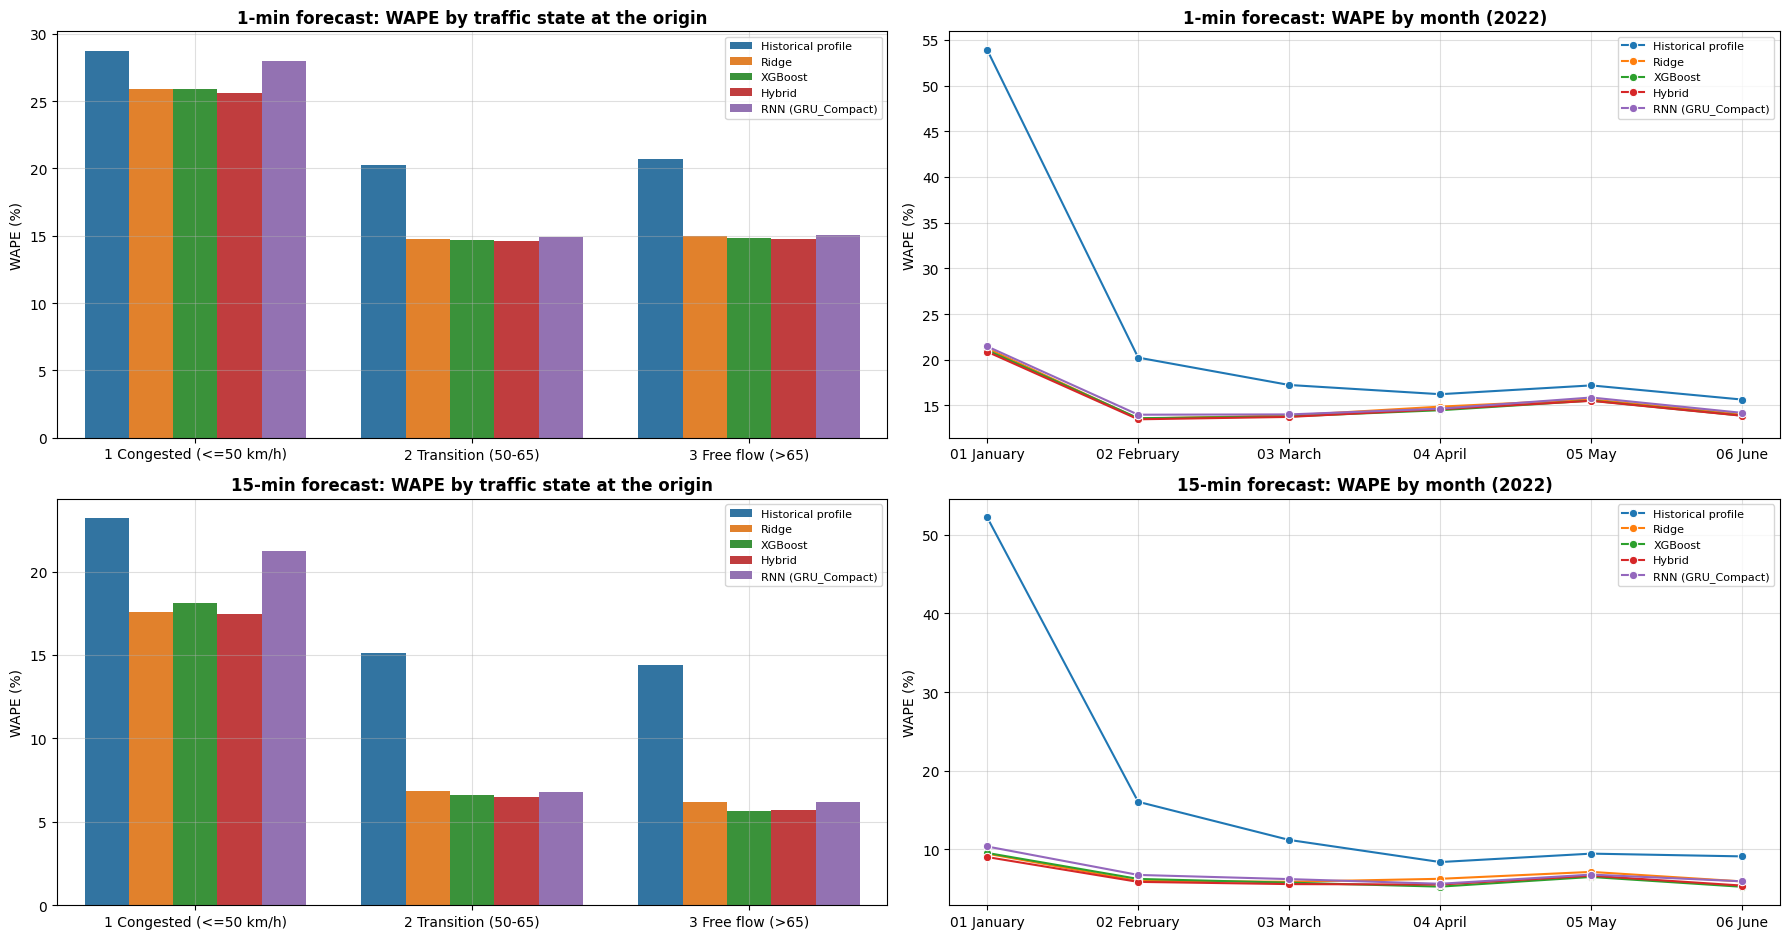

In [ ]:
# ==============================================================================
# 4.5  WHEN AND WHERE DOES THE MODEL FAIL? — 1-MINUTE AND 15-MINUTE FORECASTS
# ==============================================================================
# Errors are grouped by traffic state at the origin, day type, regime and month.
# 1-min  : mean absolute error over the 15 one-minute horizons
# 15-min : absolute error of the 15-minute flow (Method 2 for the ML models)
# WAPE per group = sum of errors / sum of flows, so both resolutions are comparable.
# ==============================================================================
diag_rows = []
for portal in TARGET_PORTALS:
    ds, p1, p15 = TEST[portal]["ds"], TEST[portal]["p1"], TEST[portal]["p15"]
    meta = ds["meta"]
    v = meta["SPEED_KMH"].to_numpy()
    groups = {
        "Traffic state": np.where(v <= 50, "1 Congested (<=50 km/h)",
                                  np.where(v <= 65, "2 Transition (50-65)", "3 Free flow (>65)")),
        "Day type": np.where(meta["DateTime"].dt.dayofweek >= 5, "Weekend", "Weekday"),
        "Month": meta["DateTime"].dt.strftime("%m %B").to_numpy(),
        "Regime": meta["Assigned_Cluster"].map(
            lambda c: f"C{c}: " + cluster_names[c].split("|")[0].strip()).to_numpy(),
    }
    for m in ["Persistence", "15-min moving avg", "Historical profile"] + ML_MODELS:
        key15 = m if m in BASELINES else f"{m} | M2 native"
        per_res = {
            "1-min": (np.abs(ds["y1"] - p1[m]).mean(axis=1), ds["y1"].mean(axis=1)),
            "15-min": (np.abs(ds["y15"] - p15[key15]), ds["y15"]),
        }
        for res, (err, level) in per_res.items():
            for dim, lab in groups.items():
                for g in np.unique(lab):
                    sel = lab == g
                    diag_rows.append({"Portal": portal, "Resolution": res, "Model": m, "Dimension": dim,
                                      "Group": g, "Samples": int(sel.sum()), "MAE": err[sel].mean(),
                                      "WAPE (%)": err[sel].sum() / level[sel].sum() * 100})

df_diag_all = pd.DataFrame(diag_rows)
df_diag = df_diag_all[df_diag_all["Resolution"] == "1-min"]   # used by the hypothesis check (4.8)

show_models = ["Persistence", "15-min moving avg", "Historical profile"] + ML_MODELS
for dim in ["Traffic state", "Day type", "Regime", "Month"]:
    for res in ["1-min", "15-min"]:
        d = df_diag_all[(df_diag_all["Dimension"] == dim) & (df_diag_all["Resolution"] == res)]
        tab = d.pivot_table(index="Group", columns="Model", values="MAE", aggfunc="mean")[show_models]
        tab.insert(0, "Samples (all portals)", d[d["Model"] == ML_MODELS[0]].groupby("Group")["Samples"].sum())
        print(f"\nMAE (veh/min) by {dim.lower()} — {res} forecast, final test, average over portals")
        display(tab.round(2))

fig, axes = plt.subplots(2, 2, figsize=(18, 9.5))
for r, res in enumerate(["1-min", "15-min"]):
    d = df_diag_all[(df_diag_all["Resolution"] == res) & df_diag_all["Model"].isin(ML_MODELS + ["Historical profile"])]
    sns.barplot(data=d[d["Dimension"] == "Traffic state"], x="Group", y="WAPE (%)", hue="Model",
                ax=axes[r, 0], errorbar=None)
    axes[r, 0].set_title(f"{res} forecast: WAPE by traffic state at the origin", fontweight="bold")
    axes[r, 0].set_xlabel("")
    sns.lineplot(data=d[d["Dimension"] == "Month"], x="Group", y="WAPE (%)", hue="Model", marker="o",
                 ax=axes[r, 1], errorbar=None)
    axes[r, 1].set_title(f"{res} forecast: WAPE by month (2022)", fontweight="bold")
    axes[r, 1].set_xlabel("")
    for ax in axes[r]:
        ax.grid(alpha=0.4); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Interpretation.**
* **Traffic state (H3, H6):** for the 15-minute flow, the ML models are clearly better than the "last 15 minutes" baseline in free flow and in transitions, but **not in congestion** (Hybrid 9.31 vs. 9.30 veh/min). Congested minutes are rare (300 of 16,653 forecasts) and their errors are about three times larger, because flow drops sharply at breakdown and the models have few such cases to learn from. XGBoost does not beat Ridge in congestion either.
* **Day type / regime (H4):** errors are lower at weekends than on weekdays, mainly because flows are lower.
* **Month:** the 15-minute error is stable from January to June 2022 (about 2.9–3.5 veh/min), so the 2021-trained model generalizes over the half year. The one-minute error rises in April–June together with the flow level, for all models and baselines alike.
* **1-minute vs. 15-minute:** congestion is difficult at both resolutions, so the problem there is real traffic dynamics (breakdown timing), not only arrival noise.

## 4.6 Robustness to missing and noisy data in real time
Failures are injected into the **raw 1-minute test data** (before imputation), and the data then passes through exactly the same pipeline as in operation: causal imputation → features → models. Errors are always computed against the **true** (uncorrupted) future flows.

| Scenario | What is corrupted |
|---|---|
| Nominal | nothing |
| Random dropouts 10% | 10% of all portal-minutes missing |
| Target detector outage 07:45–08:15 | the target portal itself is missing for 30 minutes in the peak |
| Upstream / downstream neighbour outage | that neighbour is missing all morning |
| Sensor noise ±20% | multiplicative Gaussian noise (σ = 20%) on all flows and speeds |

Only sensor measurements (flow and speed) are corrupted; clock and calendar features are never noisy in reality.


MAE (veh/min) under sensor failures — 1-min forecast, final test, average over portals


Model,Persistence,15-min moving avg,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Scenario,,,,,,
Nominal,10.10,7.79,7.62,7.54,7.52,7.69
Random dropouts 10%,10.09,7.84,7.67,7.58,7.57,7.73
Target detector outage 07:45-08:15,10.20,8.64,8.60,8.59,8.55,8.49
Upstream neighbour outage,10.10,7.79,7.63,7.56,7.54,7.80
Downstream neighbour outage,10.10,7.79,7.61,7.54,7.52,7.69
Sensor noise ±20%,13.13,8.09,8.37,7.79,7.90,8.17


Relative change vs. nominal (%) — 1-min forecast


Model,Persistence,15-min moving avg,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Scenario,,,,,,
Nominal,0.0,0.0,0.0,0.0,0.0,0.0
Random dropouts 10%,-0.1,0.8,0.7,0.5,0.6,0.4
Target detector outage 07:45-08:15,1.0,11.0,12.9,13.9,13.7,10.4
Upstream neighbour outage,0.0,0.0,0.2,0.3,0.2,1.4
Downstream neighbour outage,0.0,0.0,-0.1,-0.0,-0.1,-0.0
Sensor noise ±20%,30.0,3.9,9.9,3.3,5.0,6.2



MAE (veh/min) under sensor failures — 15-min forecast, final test, average over portals


Model,Persistence,15-min moving avg,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Scenario,,,,,,
Nominal,7.49,3.73,3.31,3.10,3.08,3.36
Random dropouts 10%,7.46,3.83,3.41,3.19,3.18,3.43
Target detector outage 07:45-08:15,7.43,5.02,4.88,4.81,4.76,4.54
Upstream neighbour outage,7.49,3.73,3.30,3.13,3.09,3.52
Downstream neighbour outage,7.49,3.73,3.29,3.10,3.07,3.35
Sensor noise ±20%,11.21,4.37,4.53,3.53,3.77,4.52


Relative change vs. nominal (%) — 15-min forecast


Model,Persistence,15-min moving avg,Ridge,XGBoost,Hybrid,RNN (GRU_Compact)
Scenario,,,,,,
Nominal,0.0,0.0,0.0,0.0,0.0,0.0
Random dropouts 10%,-0.3,2.7,3.1,2.8,3.2,2.1
Target detector outage 07:45-08:15,-0.8,34.8,47.6,55.1,54.4,35.3
Upstream neighbour outage,0.0,0.0,-0.3,1.0,0.2,5.0
Downstream neighbour outage,0.0,0.0,-0.5,-0.0,-0.4,-0.1
Sensor noise ±20%,49.7,17.4,37.0,13.9,22.3,34.6


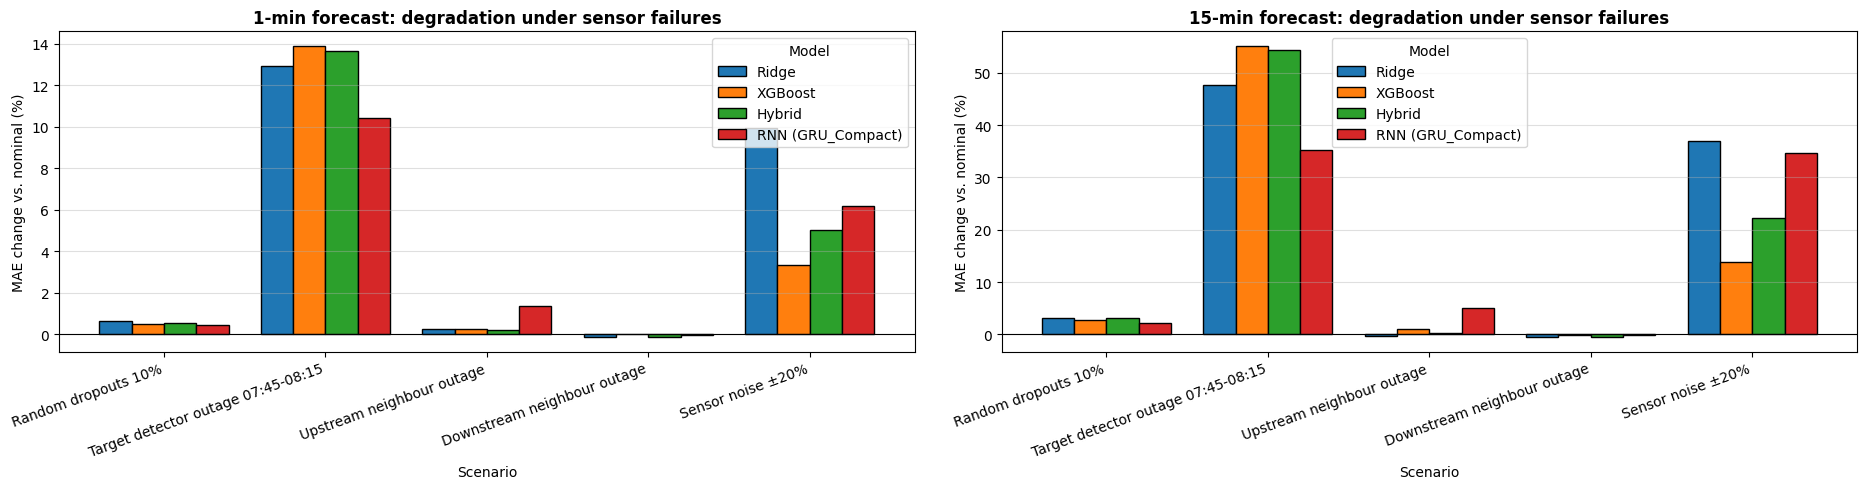

In [ ]:
# ==============================================================================
# 4.6  ROBUSTNESS TO MISSING AND NOISY SENSOR DATA — 1-MIN AND 15-MIN FORECASTS
# ==============================================================================
rng = np.random.default_rng(SEED)

def corrupt(grid_raw, scenario, portal):
    g = grid_raw.copy()
    t = g["DateTime"].dt.strftime("%H:%M")
    if scenario == "Random dropouts 10%":
        g.loc[rng.random(len(g)) < 0.10, ["FLOW", "SPEED_KMH"]] = np.nan
    elif scenario == "Target detector outage 07:45-08:15":
        g.loc[(g["PORTAL"] == portal) & (t >= "07:45") & (t < "08:15"), ["FLOW", "SPEED_KMH"]] = np.nan
    elif scenario == "Upstream neighbour outage":
        g.loc[g["PORTAL"] == PORTAL_NEIGHBORS[portal]["upstream"], ["FLOW", "SPEED_KMH"]] = np.nan
    elif scenario == "Downstream neighbour outage":
        g.loc[g["PORTAL"] == PORTAL_NEIGHBORS[portal]["downstream"], ["FLOW", "SPEED_KMH"]] = np.nan
    elif scenario == "Sensor noise ±20%":
        for col in ["FLOW", "SPEED_KMH"]:
            g[col] = (g[col] * (1 + rng.normal(0, 0.20, len(g)))).clip(lower=0)
    return g

SCENARIOS = ["Nominal", "Random dropouts 10%", "Target detector outage 07:45-08:15",
             "Upstream neighbour outage", "Downstream neighbour outage", "Sensor noise ±20%"]
stress_rows = []
for portal in TARGET_PORTALS:
    ds_clean = TEST[portal]["ds"]
    key_clean = ds_clean["meta"]["Date_Str"].astype(str) + "|" + ds_clean["meta"]["TimeOnly"]
    for sc in SCENARIOS:
        df_min_c = impute_causal(corrupt(test_grid, sc, portal), TOD_PROFILE)
        ds_c = make_dataset(df_min_c, portal, test_regimes, feature_cols=ds_clean["feature_cols"])
        key_c = ds_c["meta"]["Date_Str"].astype(str) + "|" + ds_c["meta"]["TimeOnly"]
        pos = pd.Index(key_c).get_indexer(key_clean)          # align with the clean samples
        ok = pos >= 0
        ds_c = subset_ds(ds_c, pos[ok])
        p1, p15 = run_all_predictions(FINAL[portal]["1min"], FINAL[portal]["15min"], ds_c)
        for m in ["Persistence", "15-min moving avg"] + ML_MODELS:
            key15 = m if m in BASELINES else f"{m} | M2 native"
            # errors are always computed against the TRUE (uncorrupted) future flows
            stress_rows.append({"Portal": portal, "Scenario": sc, "Model": m, "Resolution": "1-min",
                                "MAE": mean_absolute_error(ds_clean["y1"][ok], p1[m])})
            stress_rows.append({"Portal": portal, "Scenario": sc, "Model": m, "Resolution": "15-min",
                                "MAE": mean_absolute_error(ds_clean["y15"][ok], p15[key15])})

df_stress = pd.DataFrame(stress_rows)
stress_cols = ["Persistence", "15-min moving avg"] + ML_MODELS
stress_tabs = {}
for res in ["1-min", "15-min"]:
    tab = df_stress[df_stress["Resolution"] == res].pivot_table(
        index="Scenario", columns="Model", values="MAE").reindex(SCENARIOS)[stress_cols]
    stress_tabs[res] = tab
    print(f"\nMAE (veh/min) under sensor failures — {res} forecast, final test, average over portals")
    display(tab.round(2))
    print(f"Relative change vs. nominal (%) — {res} forecast")
    display(((tab / tab.loc["Nominal"] - 1) * 100).round(1))
stress_tab = stress_tabs["1-min"]          # name kept for compatibility

fig, axes = plt.subplots(1, 2, figsize=(19, 5))
for ax, res in zip(axes, ["1-min", "15-min"]):
    rel = (stress_tabs[res][ML_MODELS] / stress_tabs[res].loc["Nominal", ML_MODELS] - 1) * 100
    rel.drop(index="Nominal").plot(kind="bar", ax=ax, width=0.8, edgecolor="black")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("MAE change vs. nominal (%)")
    ax.set_title(f"{res} forecast: degradation under sensor failures", fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right"); ax.grid(axis="y", alpha=0.4)
plt.tight_layout(); plt.show()


**Interpretation.**
* **Random dropouts (10%)** have little effect (+3% for the 15-minute flow): forward-fill and the historical profile bridge short gaps.
* An **outage of the target detector** hurts most (+54% for the Hybrid's 15-minute error), because the models then rely on imputed (historical) values instead of the current state. In operation, a data-quality flag must accompany the forecast.
* **Neighbour outages** have almost no effect, which confirms that the forecast does not depend on the spatial features (H2).
* **Random errors of ±20%** increase the 15-minute error by about 14–35% for the ML models, but persistence suffers most (+50%), because it copies the latest, possibly wrong, value. Compare absolute changes too: the nominal 15-minute error is small, so the same absolute degradation looks large in percent.

## 4.7 Real-time feasibility: inference latency
The forecast has to be updated once per minute. We time a single prediction (one origin) per model. For the RNN we call a compiled `tf.function` of the model: `model.predict()` has a large fixed overhead per call that is irrelevant in a streaming service.

In [ ]:
fam = FINAL[BOTTLENECK_PORTAL]["1min"]
ds = TEST[BOTTLENECK_PORTAL]["ds"]
x_flat = ds["X_flat"][:1]
x_scaled = fam["scaler"].transform(x_flat)
x_seq = tf.constant(scale_seq(fam["scaler"], ds["X_seq"][:1]))
nn_step = tf.function(lambda x: fam["NN"](x, training=False))   # compiled graph, as in a streaming service
n_trials = 300

def time_ms(fn):
    fn()                                                    # warm-up
    t0 = time.perf_counter()
    for _ in range(n_trials):
        fn()
    return (time.perf_counter() - t0) / n_trials * 1000

lat = pd.DataFrame({
    "Model": ["Ridge (incl. scaling)", "XGBoost", NN_LABEL],
    "Latency per prediction (ms)": [
        time_ms(lambda: fam["Ridge"].predict(fam["scaler"].transform(x_flat))),
        time_ms(lambda: fam["XGBoost"].predict(x_flat)),
        time_ms(lambda: nn_step(x_seq)),
    ],
})
lat["Portals per 1-min cycle (single CPU core)"] = (60000 / lat["Latency per prediction (ms)"]).astype(int)
display(lat.round(3))

,Model,Latency per prediction (ms),Portals per 1-min cycle (single CPU core)
0,Ridge (incl. scaling),0.332,180801
1,XGBoost,1.263,47504
2,RNN (GRU_Compact),2.552,23510


All models need only milliseconds per prediction (feature construction takes longer than inference), so even the whole Stockholm motorway network could be updated every minute on one machine. Latency is therefore not a selection criterion; accuracy, robustness and maintainability are.

## 4.8 Hypothesis check (summary)
The table below collects the evidence for H1–H6 from the results above. H2–H4 use the feature-group removal test on the **15-minute target** (main target; the 1-minute result is shown in brackets), and H6 uses the errors of the 15-minute flow by traffic state. A hypothesis is marked *supported* when the effect goes in the predicted direction and exceeds a small threshold (1% in MAE).

In [ ]:
def pct(a, b):
    return (a / b - 1) * 100

hb = df_test_h[df_test_h["Model"] == BEST_1].groupby("Horizon")["MAE"].mean()
abl15 = abl_summary["ΔMAE vs all (%)"]          # feature-removal test, 15-minute target
abl1 = abl_summary_1min["ΔMAE vs all (%)"]      # feature-removal test, 1-minute target

def abl_delta(word, table=None):
    table = abl15 if table is None else table
    return float(table[[i for i in table.index if word in i]].iloc[0])

# Traffic-state comparison on the 15-minute flow (main target)
d15 = df_diag_all[(df_diag_all["Resolution"] == "15-min") & (df_diag_all["Dimension"] == "Traffic state")]
state_tab = d15.pivot_table(index="Group", columns="Model", values="MAE")
cong = [g for g in state_tab.index if g.startswith("1")]
free = [g for g in state_tab.index if g.startswith("3")]
wape_1 = df_test_1[(df_test_1["Set"] == final) & (df_test_1["Model"] == BEST_1)]["WAPE (%)"].mean()
wape_15 = df_test_15[(df_test_15["Set"] == final) & (df_test_15["Model"] == f"{BEST_1} | M1 post-hoc")]["WAPE (%)"].mean()

evidence = []
evidence.append(("H1 Temporal persistence",
                 f"{BEST_1} MAE grows from {hb.iloc[0]:.2f} (t+1) to {hb.iloc[-1]:.2f} (t+15) veh/min",
                 hb.iloc[-1] > hb.iloc[0] * 1.01))
for label, word in [("H2 Spatial propagation", "Spatial"), ("H3 Speed resolves ambiguity", "Speed")]:
    evidence.append((label,
                     f"removing the group changes val MAE by {abl_delta(word):+.2f}% (15-min target; "
                     f"1-min target: {abl_delta(word, abl1):+.2f}%)",
                     abl_delta(word) > 1.0))
evidence.append(("H4 Day-type regimes",
                 f"removing calendar: {abl_delta('Calendar'):+.2f}%, removing day-type clusters: "
                 f"{abl_delta('Regime'):+.2f}% (15-min target)",
                 max(abl_delta("Calendar"), abl_delta("Regime")) > 1.0))
evidence.append(("H5 Aggregation", f"{BEST_1} WAPE {wape_1:.1f}% (1-min) vs {wape_15:.1f}% (15-min average)",
                 wape_15 < 0.75 * wape_1))
if cong and free:
    r_c = pct(state_tab.loc[cong[0], "Ridge"], state_tab.loc[cong[0], "XGBoost"])
    r_f = pct(state_tab.loc[free[0], "Ridge"], state_tab.loc[free[0], "XGBoost"])
    evidence.append(("H6 Non-linearity",
                     f"Ridge error above XGBoost (15-min flow): {r_c:+.1f}% in congestion vs {r_f:+.1f}% in free flow",
                     r_c > r_f + 1.0))
else:
    evidence.append(("H6 Non-linearity", "not enough congested samples to test", False))

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(evidence, columns=["Hypothesis", "Evidence", "Supported?"])
        .assign(**{"Supported?": lambda d: d["Supported?"].map({True: "yes", False: "no / weak"})}))

,Hypothesis,Evidence,Supported?
0,H1 Temporal persistence,Hybrid MAE grows from 6.95 (t+1) to 7.82 (t+15) veh/min,yes
1,H2 Spatial propagation,removing the group changes val MAE by -0.28% (15-min target; 1-min target: -0.02%),no / weak
2,H3 Speed resolves ambiguity,removing the group changes val MAE by -2.26% (15-min target; 1-min target: -0.89%),no / weak
3,H4 Day-type regimes,"removing calendar: -1.22%, removing day-type clusters: -0.02% (15-min target)",no / weak
4,H5 Aggregation,Hybrid WAPE 14.7% (1-min) vs 6.1% (15-min average),yes
5,H6 Non-linearity,Ridge error above XGBoost (15-min flow): -2.1% in congestion vs +8.6% in free flow,no / weak


# **PART 5: MODEL DEPLOYMENT (Task E)**

## 5.1 Final summary and saved artifacts
The assignment asks for the best trained model to be saved in `.keras` format. Only the recurrent network is a Keras model; the tree model is saved in XGBoost's native `.json` format (more robust across library versions than pickling). For transparency we save **all** final models plus everything the pipeline needs at run time (feature list, scaler, historical profile, regime centroids), and check that the saved models reload and reproduce the predictions.

In [ ]:
res_1 = df_test_1[df_test_1["Set"] == final].groupby("Model")["MAE"].mean()
res_15 = df_test_15[df_test_15["Set"] == final].groupby("Model")["MAE"].mean()
best_base_1 = res_1[BASELINES].idxmin()
best_base_15 = res_15[BASELINES].idxmin()
print("=" * 80)
print(f"MAIN TARGET - 15-minute flow, best model on 2021 validation: {BEST_15}")
print(f"  Final-test MAE : {res_15[BEST_15]:.2f} veh/min "
      f"(best baseline '{best_base_15}': {res_15[best_base_15]:.2f}, "
      f"improvement {(1 - res_15[BEST_15] / res_15[best_base_15]) * 100:.1f}%)")
print(f"1-minute forecast, best model on 2021 validation: {BEST_1}")
print(f"  Final-test MAE : {res_1[BEST_1]:.2f} veh/min "
      f"(best baseline '{best_base_1}': {res_1[best_base_1]:.2f}, "
      f"improvement {(1 - res_1[BEST_1] / res_1[best_base_1]) * 100:.1f}%)")
print("=" * 80)

saved = []
for portal in TARGET_PORTALS:
    tag = portal.replace(" ", "_").replace(",", "")
    for target in ["1min", "15min"]:
        fam = FINAL[portal][target]
        p_keras = f"{OUTPUT_DIR}/rnn_{NN_NAME}_{target}_{tag}.keras"
        p_xgb = f"{OUTPUT_DIR}/xgboost_{target}_{tag}.json"
        p_ridge = f"{OUTPUT_DIR}/ridge_scaler_{target}_{tag}.joblib"
        fam["NN"].save(p_keras)
        fam["XGBoost"].save_model(p_xgb)
        joblib.dump({"scaler": fam["scaler"], "ridge": fam["Ridge"]}, p_ridge)
        saved += [p_keras, p_xgb, p_ridge]

joblib.dump({
    "feature_cols": FEATURE_COLS, "corridor_portals": CORRIDOR_PORTALS, "target_portals": TARGET_PORTALS,
    "expected_detectors": EXPECTED_DETECTORS, "tod_profile": TOD_PROFILE,
    "prepeak_feature_cols": feature_cols_prepeak, "prepeak_fill": prepeak_fill,
    "prepeak_centroids": centroids_prepeak, "cluster_names": cluster_names, "default_regime": DEFAULT_REGIME,
    "nn_config": NN_CFG, "nn_name": NN_NAME, "nn_epochs": NN_EPOCHS,
    "ridge_alpha": BEST_ALPHA, "xgb_params": BEST_XGB_PARAMS, "best_1min": BEST_1, "best_15min": BEST_15,
}, f"{OUTPUT_DIR}/pipeline_metadata.joblib")
saved.append(f"{OUTPUT_DIR}/pipeline_metadata.joblib")
print(f"Saved {len(saved)} files to '{OUTPUT_DIR}/'")

# Reload check on the bottleneck
tag = BOTTLENECK_PORTAL.replace(" ", "_").replace(",", "")
fam, ds = FINAL[BOTTLENECK_PORTAL]["1min"], TEST[BOTTLENECK_PORTAL]["ds"]
nn_loaded = tf.keras.models.load_model(f"{OUTPUT_DIR}/rnn_{NN_NAME}_1min_{tag}.keras")
xgb_loaded = xgb.XGBRegressor(); xgb_loaded.load_model(f"{OUTPUT_DIR}/xgboost_1min_{tag}.json")
xs = scale_seq(fam["scaler"], ds["X_seq"][:200])
print("Reloaded .keras reproduces predictions:", np.allclose(nn_loaded.predict(xs, verbose=0), fam["NN"].predict(xs, verbose=0), atol=1e-4))
print("Reloaded .json  reproduces predictions:", np.allclose(xgb_loaded.predict(ds["X_flat"][:200]), fam["XGBoost"].predict(ds["X_flat"][:200]), atol=1e-4))

MAIN TARGET - 15-minute flow, best model on 2021 validation: Hybrid | M1 post-hoc
  Final-test MAE : 3.11 veh/min (best baseline '15-min moving avg': 3.73, improvement 16.4%)
1-minute forecast, best model on 2021 validation: Hybrid
  Final-test MAE : 7.52 veh/min (best baseline '15-min moving avg': 7.79, improvement 3.4%)
Saved 19 files to 'model_artifacts/'
Reloaded .keras reproduces predictions: True
Reloaded .json  reproduces predictions: True
